# Fraud-Label Constrained Dual-Task Graph Neural Networks for Bitcoin Anti-Money Laundering
### MPhil Data Science — University of Ghana
**Author:** Gilbert Woasieworm Adjei &nbsp;|&nbsp; **Supervisor:** Dr Alvin Prince Ansah

---

| Variant | Description |
|---|---|
| **Option 1A** | Joint node classification + link prediction with a shared GraphSAGE encoder |
| **Option 1B** | Extends 1A with a fraud-label constraint penalising predicted edges between confirmed illicit and confirmed licit nodes |
| **Option 1C** | Directional variant of the constraint (reported as a negative result) |
| **Node-only** | Same encoder with the node head only (no link task, no constraint) |
| **Feature-only** | Random forest, gradient boosting and logistic regression on the raw features (no graph) |

**Dataset:** Elliptic Bitcoin Transaction Dataset (Weber et al., 2019)  
203,769 nodes · 234,355 edges · **165 features** · 49 time steps · 4,545 illicit · 42,019 licit · 157,205 unknown  
**Graph:** complete Elliptic graph, no subsampling (203,769 nodes)

## 1. Setup

In [1]:
!pip uninstall -y -q torch-scatter torch-sparse torch-cluster torch-spline-conv
!pip install -q torch-geometric==2.6.1 scikit-learn==1.5.2 seaborn==0.13.2

import os, random
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, pandas as pd, json
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from torch_geometric.nn import SAGEConv
from torch_geometric.data import Data
from torch_geometric.utils import negative_sampling
from sklearn.metrics import (
    f1_score, roc_auc_score, precision_score,
    recall_score, average_precision_score, confusion_matrix
)
from sklearn.model_selection import train_test_split

# ── Full reproducibility (GPU) ────────────────────────────────────────
# This runs on CUDA. Getting bit-identical results on CUDA across separate
# runs needs more than torch.manual_seed. Three things matter:
#
# 1. CUBLAS_WORKSPACE_CONFIG must be set before any CUDA context exists,
#    i.e. before the first tensor .to('cuda') call — it is set immediately
#    below, right after import, before device is used anywhere.
# 2. torch.use_deterministic_algorithms(True) forces PyTorch to use its
#    deterministic (slower) kernels for scatter/index_add ops — this is
#    what SAGEConv's neighbourhood aggregation relies on — instead of the
#    default atomic-add kernels, whose summation order (and therefore
#    floating-point result) varies run to run on GPU.
# 3. torch-scatter / torch-sparse / torch-cluster (the standalone PyG CUDA
#    extensions) are explicitly uninstalled below. If present, PyG prefers
#    their custom CUDA kernels over its native PyTorch fallback, and those
#    custom kernels are NOT covered by use_deterministic_algorithms — they
#    would silently reintroduce non-determinism with no warning or error.
#    Uninstalling them forces PyG onto its native, seed-respecting path.
#
# Caveat that no amount of code can fix: exact bit-for-bit reproducibility
# on CUDA is only guaranteed on the same GPU model + driver + CUDA/cuDNN
# version. If Colab assigns a different GPU type between sessions (e.g.
# T4 vs L4 vs A100), results may still shift slightly. Check the printed
# GPU name below and keep a note of it alongside any numbers you report.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'  # must be set before first CUDA call

torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_num_threads(1)  # keeps any CPU-side ops (e.g. the sklearn t-SNE step) deterministic too

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available in this runtime. This notebook is configured to "
        "require GPU — go to Runtime > Change runtime type and select a GPU, "
        "then re-run this cell."
    )
device = torch.device('cuda')

print(f"Device     : {device}")
print(f"GPU        : {torch.cuda.get_device_name(0)}")
print(f"CUDA       : {torch.version.cuda}")
print(f"PyTorch    : {torch.__version__}")
print(f"Seed       : {SEED}")
print("Deterministic algorithms enabled; torch-scatter/-sparse/-cluster removed "
      "to force PyG's native (seed-respecting) aggregation path.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device     : cuda
GPU        : Tesla T4
CUDA       : 13.0
PyTorch    : 2.14.1+cu130
Seed       : 42
Deterministic algorithms enabled; torch-scatter/-sparse/-cluster removed to force PyG's native (seed-respecting) aggregation path.


## 2. Configuration

In [2]:
DATA_PATH       = '/content/drive/MyDrive/elliptic_bitcoin_dataset/'

MAX_NODES       = 250_000  # set comfortably above the known dataset size (~203,769 nodes)
                            # so the stratified-selection logic in Preprocessing naturally
                            # takes every node, rather than hardcoding the exact count here.
HIDDEN_CHANNELS = 64
DROPOUT         = 0.5
LEARNING_RATE   = 0.01
WEIGHT_DECAY    = 5e-4
NUM_EPOCHS      = 200
PATIENCE        = 20
ALPHA           = 0.5      # node-loss weight; (1-ALPHA) = link-loss weight
LAMBDA          = 1.0      # fraud-label constraint penalty weight (Option 1B)

print(f"MAX_NODES={MAX_NODES:,}  HIDDEN={HIDDEN_CHANNELS}  DROPOUT={DROPOUT}")
print(f"LR={LEARNING_RATE}  WD={WEIGHT_DECAY}  EPOCHS={NUM_EPOCHS}  PATIENCE={PATIENCE}")
print(f"ALPHA={ALPHA}  LAMBDA={LAMBDA}")

MAX_NODES=250,000  HIDDEN=64  DROPOUT=0.5
LR=0.01  WD=0.0005  EPOCHS=200  PATIENCE=20
ALPHA=0.5  LAMBDA=1.0


In [3]:
DRY_RUN = False     # True = quick test (2 seeds, 15 epochs). Set to False for the real run.
if DRY_RUN:
    NUM_EPOCHS = 15
    PATIENCE   = 5
MIN_EPOCHS = 3 if DRY_RUN else 100   # early stopping cannot trigger before this epoch
print("DRY RUN" if DRY_RUN else "FULL RUN", "| epochs:", NUM_EPOCHS, "| patience:", PATIENCE, "| min epochs:", MIN_EPOCHS)

FULL RUN | epochs: 200 | patience: 20 | min epochs: 100


**On `MAX_NODES`:** earlier iterations of this work used a 20,000-node stratified subsample, chosen for fast iteration while the pipeline was being built and debugged. `MAX_NODES` is set here to comfortably exceed the full dataset size so every experiment in this notebook runs on the complete 203,769-node graph, for two reasons: results on a subsample cannot be directly compared to Weber et al. (2019), who evaluate on the full dataset, and the class balance in a stratified 20,000-node subsample (roughly 20% illicit) is far more favourable than the true dataset's balance (2.2% illicit), so subsample results systematically overstate how hard the classification problem actually is.

**On `LAMBDA = 1.0`:** this weight is fixed *a priori* as an unweighted balance between the standard link-prediction loss (binary cross-entropy) and the fraud-label constraint penalty, both of which are on a comparable [0, 1] scale after the sigmoid in `constrained_link_loss`. It was not selected by scanning the lambda sweep in Section 13 for whichever value scored best on a reported metric: doing so would mean the "held-out" test results elsewhere in this notebook were implicitly tuned against, a form of leakage through hyperparameter selection. The sweep in Section 13 is reported as a *sensitivity analysis* of how performance changes with lambda, not as the procedure that chose it. If lambda were to be tuned in future work, the correct procedure would be to select it on the validation split only, the same principle applied to the decision threshold in Experiment I.

In [4]:
import pickle, os
import types as _types
CKPT_PATH = '/content/drive/MyDrive/aml_results_checkpoint' + ('_DRYRUN' if DRY_RUN else '') + '.pkl'

def save_checkpoint():
    keep = {}
    for k, v in list(globals().items()):
        if k.startswith('_') or isinstance(v, (_types.ModuleType, _types.FunctionType, type)):
            continue
        if isinstance(v, (list, dict, int, float, str, bool, tuple, np.ndarray)):
            try:
                blob = pickle.dumps(v)
            except Exception:
                continue
            if len(blob) < 50_000_000:
                keep[k] = v
    with open(CKPT_PATH, 'wb') as f:
        pickle.dump(keep, f)
    print(f"checkpoint saved: {len(keep)} variables -> {CKPT_PATH}")

def load_checkpoint():
    with open(CKPT_PATH, 'rb') as f:
        saved = pickle.load(f)
    globals().update(saved)
    print(f"restored {len(saved)} variables from {CKPT_PATH}")

## 3. Data Loading

In [5]:
from google.colab import drive
drive.mount('/content/drive')

features_df = pd.read_csv(DATA_PATH + 'elliptic_txs_features.csv', header=None)
edges_df    = pd.read_csv(DATA_PATH + 'elliptic_txs_edgelist.csv')
classes_df  = pd.read_csv(DATA_PATH + 'elliptic_txs_classes.csv')

print(f"Features : {features_df.shape}  (col 0=txId, col 1=timeStep, cols 2-166=165 features)")
print(f"Edges    : {edges_df.shape}")
print(f"Classes  : {classes_df.shape}")

Mounted at /content/drive
Features : (203769, 167)  (col 0=txId, col 1=timeStep, cols 2-166=165 features)
Edges    : (234355, 2)
Classes  : (203769, 2)


## 4. Preprocessing

Node split: **70 / 15 / 15** (train / val / test), stratified by class.  
Edge split: **60 / 20 / 20** (train / val / test) — differs from node split because edge evaluation is independent of node label availability.

In [6]:
import gc

node_ids     = features_df[0].values
time_steps   = features_df[1].values.astype(np.int64)  # captured for the temporal-split experiment later
raw_features = features_df.iloc[:, 2:].values.astype(np.float32)  # 165 features
id_to_idx    = {nid: i for i, nid in enumerate(node_ids)}

# ── Labels (vectorised — no iterrows) ─────────────────────────────────────
classes_df.columns = ['txId', 'class']
label_map = {'1': 1, '2': 0, 'unknown': -1}
classes_df['label'] = classes_df['class'].astype(str).map(label_map)

labels = np.full(len(node_ids), -1, dtype=np.int64)
mapped_pos = classes_df['txId'].map(id_to_idx)          # NaN where txId not in this node set
valid      = mapped_pos.notna()
labels[mapped_pos[valid].astype(np.int64).values] = classes_df.loc[valid, 'label'].values

print("Full dataset:")
print(f"  Total nodes    : {len(node_ids):,}")
print(f"  Labeled        : {(labels != -1).sum():,}")
print(f"  Illicit  (1)   : {(labels == 1).sum():,}")
print(f"  Licit    (0)   : {(labels == 0).sum():,}")
print(f"  Unknown  (-1)  : {(labels == -1).sum():,}")

# Captured now (pre-subsample) so the export cell reports the true full-dataset
# stats actually observed in these CSVs, rather than hardcoded literals.
full_dataset_stats = {
    'total_nodes': int(len(node_ids)),
    'total_edges': int(len(edges_df)),
    'features': int(raw_features.shape[1]),
    'illicit_full': int((labels == 1).sum()),
    'licit_full': int((labels == 0).sum()),
    'unknown_full': int((labels == -1).sum()),
}

# ── Degree count (vectorised via np.bincount — no iterrows) ───────────────
src_pos = edges_df['txId1'].map(id_to_idx)
dst_pos = edges_df['txId2'].map(id_to_idx)
edge_valid = src_pos.notna() & dst_pos.notna()
src_valid  = src_pos[edge_valid].astype(np.int64).values
dst_valid  = dst_pos[edge_valid].astype(np.int64).values

degrees = (np.bincount(src_valid, minlength=len(node_ids))
           + np.bincount(dst_valid, minlength=len(node_ids))).astype(np.int32)

del src_pos, dst_pos, edge_valid, src_valid, dst_valid
gc.collect()

illicit_idx = np.where(labels == 1)[0]
licit_idx   = np.where(labels == 0)[0]
unknown_idx = np.where(labels == -1)[0]

# MAX_NODES can equal (or exceed) the full dataset size — in that case every
# node is selected and this block reduces to a re-ordering, not a subsample.
num_illicit = min(int(MAX_NODES * 0.20), len(illicit_idx))
num_licit   = min(int(MAX_NODES * 0.25), len(licit_idx))
num_unknown = min(MAX_NODES - num_illicit - num_licit, len(unknown_idx))

top_illicit = illicit_idx[np.argsort(degrees[illicit_idx])[-num_illicit:]]
top_licit   = licit_idx[np.argsort(degrees[licit_idx])[-num_licit:]]
top_unknown = unknown_idx[np.argsort(degrees[unknown_idx])[-num_unknown:]]
selected    = np.concatenate([top_illicit, top_licit, top_unknown])

del degrees, illicit_idx, licit_idx, unknown_idx, top_illicit, top_licit, top_unknown
gc.collect()

raw_features = raw_features[selected]
labels       = labels[selected]
node_ids     = node_ids[selected]
time_steps   = time_steps[selected]
id_to_idx    = {nid: i for i, nid in enumerate(node_ids)}  # re-indexed to the selected subset

print(f"\nSubsample ({len(selected):,} nodes):")
print(f"  Illicit : {(labels==1).sum():,}  ({(labels==1).sum()/len(node_ids)*100:.1f}%)")
print(f"  Licit   : {(labels==0).sum():,}  ({(labels==0).sum()/len(node_ids)*100:.1f}%)")
print(f"  Unknown : {(labels==-1).sum():,}")


# ── Subgraph edge index (vectorised — no iterrows) ─────────────────────────
src_pos = edges_df['txId1'].map(id_to_idx)
dst_pos = edges_df['txId2'].map(id_to_idx)
edge_valid = src_pos.notna() & dst_pos.notna()
edge_index = torch.tensor(
    np.vstack([src_pos[edge_valid].astype(np.int64).values,
               dst_pos[edge_valid].astype(np.int64).values]),
    dtype=torch.long
)
del src_pos, dst_pos, edge_valid
gc.collect()
print(f"\nSubgraph edges : {edge_index.shape[1]:,}")

# The raw CSVs are no longer needed past this point — free the memory.
del features_df, edges_df, classes_df
gc.collect()

# Node splits: 70 / 15 / 15 (stratified)
labeled_idx = np.where(labels != -1)[0]
train_val_idx, test_idx = train_test_split(
    labeled_idx, test_size=0.15, random_state=42, stratify=labels[labeled_idx])
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.15/(1-0.15),
    random_state=42, stratify=labels[train_val_idx])

N = len(node_ids)
train_mask, val_mask, test_mask = (torch.zeros(N, dtype=torch.bool) for _ in range(3))
train_mask[train_idx] = True
val_mask[val_idx]     = True
test_mask[test_idx]   = True

# Feature normalisation: mean/std from the labelled TRAINING nodes only (random split).
# raw_features stays in memory: the temporal split fits its own scaler in Section 16.
_mu = raw_features[train_idx].mean(axis=0)
_sd = raw_features[train_idx].std(axis=0) + 1e-8
X   = (raw_features - _mu) / _sd

print(f"\nNode splits (70/15/15):")
print(f"  Train : {train_mask.sum():,}  (Illicit: {(labels[train_idx]==1).sum()}, Licit: {(labels[train_idx]==0).sum()})")
print(f"  Val   : {val_mask.sum():,}  (Illicit: {(labels[val_idx]==1).sum()}, Licit: {(labels[val_idx]==0).sum()})")
print(f"  Test  : {test_mask.sum():,}  (Illicit: {(labels[test_idx]==1).sum()}, Licit: {(labels[test_idx]==0).sum()})")


# ── Same-time-step negative sampling ─────────────────────────────────────────
# Every real edge joins two nodes in the same time step, so negatives drawn from all nodes
# are separable by time step alone (a one-line rule reaches AUC 0.988). Each negative here
# keeps the real edge's source node and replaces the destination with a random node from
# the SAME time step that is not connected to the source in the full graph.
_nodes_by_step = {int(s): np.where(time_steps == s)[0] for s in np.unique(time_steps)}
_existing = set(map(tuple, edge_index.numpy().T.tolist()))

def same_step_negatives(pos_edges, seed):
    rng = np.random.RandomState(seed)
    src = pos_edges[0].numpy()
    dst = np.empty_like(src)
    todo = np.arange(len(src))
    for _ in range(50):
        for s in np.unique(time_steps[src[todo]]):
            sel = todo[time_steps[src[todo]] == s]
            dst[sel] = rng.choice(_nodes_by_step[int(s)], size=len(sel))
        bad = np.array([((src[i], dst[i]) in _existing) or ((dst[i], src[i]) in _existing)
                        or (src[i] == dst[i]) for i in todo])
        todo = todo[bad]
        if len(todo) == 0:
            break
    assert len(todo) == 0, f"{len(todo)} negatives could not be resolved"
    return torch.tensor(np.vstack([src, dst]), dtype=torch.long)


# Edge splits: 60 / 20 / 20
num_edges = edge_index.shape[1]
g_perm    = torch.Generator(); g_perm.manual_seed(SEED)
perm      = torch.randperm(num_edges, generator=g_perm)
n_train   = int(0.60 * num_edges)
n_val     = int(0.20 * num_edges)
train_pos = edge_index[:, perm[:n_train]]
val_pos   = edge_index[:, perm[n_train:n_train+n_val]]
test_pos  = edge_index[:, perm[n_train+n_val:]]

train_neg = same_step_negatives(train_pos, SEED + 1)
val_neg   = same_step_negatives(val_pos,   SEED + 2)
test_neg  = same_step_negatives(test_pos,  SEED + 3)

torch.manual_seed(SEED)  # restore global seed for training

train_eil = torch.cat([train_pos, train_neg], dim=1)
train_el  = torch.cat([torch.ones(train_pos.shape[1]), torch.zeros(train_neg.shape[1])])
val_eil   = torch.cat([val_pos, val_neg], dim=1)
val_el    = torch.cat([torch.ones(val_pos.shape[1]), torch.zeros(val_neg.shape[1])])
test_eil  = torch.cat([test_pos, test_neg], dim=1)
test_el   = torch.cat([torch.ones(test_pos.shape[1]), torch.zeros(test_neg.shape[1])])

print(f"\nEdge splits (60/20/20):")
print(f"  Train : {train_pos.shape[1]:,} pos / {train_neg.shape[1]:,} neg")
print(f"  Val   : {val_pos.shape[1]:,} pos / {val_neg.shape[1]:,} neg")
print(f"  Test  : {test_pos.shape[1]:,} pos / {test_neg.shape[1]:,} neg")

# Inverse-frequency class weights (training partition only)
licit_n   = int((labels[train_idx] == 0).sum())
illicit_n = int((labels[train_idx] == 1).sum())
total_n   = licit_n + illicit_n
class_weights = torch.tensor([total_n/(2*licit_n), total_n/(2*illicit_n)], dtype=torch.float)
print(f"\nClass weights (training partition: {licit_n} licit / {illicit_n} illicit):")
print(f"  Licit={class_weights[0]:.4f}  Illicit={class_weights[1]:.4f}  Ratio={class_weights[1]/class_weights[0]:.2f}x")

# PyG Data object
data = Data(
    x=torch.tensor(X, dtype=torch.float), edge_index=train_pos,
    y=torch.tensor(labels, dtype=torch.long),
    train_mask=train_mask, val_mask=val_mask, test_mask=test_mask,
    train_edge_label_index=train_eil, train_edge_label=train_el,
    val_edge_label_index=val_eil,   val_edge_label=val_el,
    test_edge_label_index=test_eil, test_edge_label=test_el,
    full_edge_index=edge_index,
)
data.class_weights = class_weights
data.val_msg_edge_index  = train_pos                           # graph used to score validation links
data.test_msg_edge_index = torch.cat([train_pos, val_pos], 1)  # graph used to score test links
del X
gc.collect()
print(f"\n\u2713 Data ready  Nodes: {data.x.shape[0]:,}  Features: {data.x.shape[1]}")

Full dataset:
  Total nodes    : 203,769
  Labeled        : 46,564
  Illicit  (1)   : 4,545
  Licit    (0)   : 42,019
  Unknown  (-1)  : 157,205

Subsample (203,769 nodes):
  Illicit : 4,545  (2.2%)
  Licit   : 42,019  (20.6%)
  Unknown : 157,205

Subgraph edges : 234,355

Node splits (70/15/15):
  Train : 32,594  (Illicit: 3181, Licit: 29413)
  Val   : 6,985  (Illicit: 682, Licit: 6303)
  Test  : 6,985  (Illicit: 682, Licit: 6303)

Edge splits (60/20/20):
  Train : 140,613 pos / 140,613 neg
  Val   : 46,871 pos / 46,871 neg
  Test  : 46,871 pos / 46,871 neg

Class weights (training partition: 29413 licit / 3181 illicit):
  Licit=0.5541  Illicit=5.1232  Ratio=9.25x

✓ Data ready  Nodes: 203,769  Features: 165


## 5. Model Architecture

Both variants share the same GraphSAGE encoder. Task-specific decoders sit on top.

| Component | Detail |
|---|---|
| GraphSAGE encoder | 2 SAGEConv layers · 64 hidden dims · mean aggregation · ReLU · Dropout 0.5 |
| Node classification head | Linear(64→32) → ReLU → Dropout → Linear(32→2) |
| Link prediction decoder | Dot product of source and destination embeddings |
| Constraint loss (1B) | BCE + λ × mean σ(score) over confirmed cross-class (illicit↔licit) edges |

In [7]:
class DualTaskGNN(nn.Module):
    """Shared GraphSAGE encoder with node classification and link prediction heads."""

    def __init__(self, in_channels, hidden_channels, num_classes, dropout=0.5):
        super().__init__()
        self.conv1     = SAGEConv(in_channels, hidden_channels)
        self.conv2     = SAGEConv(hidden_channels, hidden_channels)
        self.node_head = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels // 2, num_classes)
        )
        self.dropout = dropout

    def encode(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

    def decode_nodes(self, z):
        return self.node_head(z)

    def decode_links(self, z, edge_label_index):
        return (z[edge_label_index[0]] * z[edge_label_index[1]]).sum(dim=-1)

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode_nodes(z), self.decode_links(z, edge_label_index)


class ConstrainedDualTaskGNN(DualTaskGNN):
    """Extends DualTaskGNN with the fraud-label constraint.

    The fraud-label constraint studied in this thesis: penalises high scores for edges between confirmed
    illicit and confirmed licit nodes.
    """

    def forward_with_constraint(self, x, edge_index, edge_label_index, node_labels):
        node_pred, link_pred = super().forward(x, edge_index, edge_label_index)
        src, dst = node_labels[edge_label_index[0]], node_labels[edge_label_index[1]]
        cross_mask = ((src == 0) & (dst == 1)) | ((src == 1) & (dst == 0))
        return node_pred, link_pred, cross_mask


def constrained_link_loss(link_pred, edge_label, cross_mask, lam=1.0):
    """BCE + lambda * mean sigmoid score over cross-class edges."""
    bce = F.binary_cross_entropy_with_logits(link_pred, edge_label.float())
    penalty = torch.sigmoid(link_pred[cross_mask]).mean() if cross_mask.any()               else torch.tensor(0.0, device=link_pred.device)
    return bce + lam * penalty, bce, penalty


_m  = DualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT)
_cm = ConstrainedDualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT)
print(f"DualTaskGNN            : {sum(p.numel() for p in _m.parameters()):,} parameters")
print(f"ConstrainedDualTaskGNN : {sum(p.numel() for p in _cm.parameters()):,} parameters")
del _m, _cm

DualTaskGNN            : 31,586 parameters
ConstrainedDualTaskGNN : 31,586 parameters


## 6. Training and Evaluation Functions

In [8]:
def node_loss_fn(logits, labels, mask, class_weights, device):
    logits_m, labels_m = logits[mask], labels[mask]
    valid = labels_m >= 0
    if not valid.any():
        return torch.tensor(0.0, device=device, requires_grad=True)
    return F.cross_entropy(logits_m[valid], labels_m[valid], weight=class_weights.to(device))


def train_1a(model, data, optimizer, alpha, device):
    model.train()
    optimizer.zero_grad()
    node_pred, link_pred = model(
        data.x.to(device), data.edge_index.to(device),
        data.train_edge_label_index.to(device))
    n_loss = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    l_loss = F.binary_cross_entropy_with_logits(link_pred, data.train_edge_label.float().to(device))
    loss   = alpha * n_loss + (1 - alpha) * l_loss
    loss.backward(); optimizer.step()
    return {'total': loss.item(), 'node': n_loss.item(), 'link': l_loss.item()}


def train_1b(model, data, optimizer, alpha, lam, device):
    model.train()
    optimizer.zero_grad()
    # The constraint may only use labels of TRAINING nodes. Val/test labels are hidden (-1).
    y_constraint = torch.where(data.train_mask, data.y, torch.full_like(data.y, -1)).to(device)
    node_pred, link_pred, cross_mask = model.forward_with_constraint(
        data.x.to(device), data.edge_index.to(device),
        data.train_edge_label_index.to(device), y_constraint)
    n_loss               = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    total_link, bce, cp  = constrained_link_loss(link_pred, data.train_edge_label.to(device), cross_mask, lam)
    loss = alpha * n_loss + (1 - alpha) * total_link
    loss.backward(); optimizer.step()
    return {'total': loss.item(), 'node': n_loss.item(), 'link': total_link.item(),
            'bce': bce.item(), 'constraint': float(cp.detach()) if isinstance(cp, torch.Tensor) else cp, 'n_cross': cross_mask.sum().item()}


@torch.no_grad()
def evaluate(model, data, split, device, constrained=False):
    model.eval()
    x, y  = data.x.to(device), data.y.to(device)
    mask  = {'train': data.train_mask, 'val': data.val_mask, 'test': data.test_mask}[split].to(device)
    eli   = getattr(data, f'{split}_edge_label_index').to(device)
    el    = getattr(data, f'{split}_edge_label').to(device)

    # Node metrics: full graph (transductive node classification, as in Weber et al.)
    ei_node = data.full_edge_index.to(device)
    # Link metrics: graph WITHOUT the edges being scored
    ei_link = (data.edge_index if split == 'train'
               else getattr(data, f'{split}_msg_edge_index')).to(device)

    if constrained:
        node_pred, _, _ = model.forward_with_constraint(x, ei_node, eli, y)
        _, link_pred, _ = model.forward_with_constraint(x, ei_link, eli, y)
    else:
        node_pred, _ = model(x, ei_node, eli)
        _, link_pred = model(x, ei_link, eli)

    yt = y[mask].cpu().numpy()
    yp = node_pred[mask].argmax(-1).cpu().numpy()
    yb = F.softmax(node_pred[mask], dim=-1)[:, 1].cpu().numpy()
    lp = torch.sigmoid(link_pred).cpu().numpy()
    la = el.cpu().numpy()

    return {
        'node_f1_macro'  : f1_score(yt, yp, average='macro',  zero_division=0),
        'node_f1_illicit': f1_score(yt, yp, average='binary', zero_division=0),
        'node_precision' : precision_score(yt, yp, zero_division=0),
        'node_recall'    : recall_score(yt, yp, zero_division=0),
        'node_auc'       : roc_auc_score(yt, yb) if len(np.unique(yt)) > 1 else 0.0,
        'link_auc'       : roc_auc_score(la, lp),
        'link_ap'        : average_precision_score(la, lp),
    }


def training_loop(model, train_fn, kwargs, label, data, verbose=True, num_epochs=None, patience_limit=None):
    """Training loop with early stopping. Returns history dict.

    data is passed explicitly (not read from the global scope) so this function
    is safely reusable with a different Data object -- e.g. the temporal-split
    experiment below constructs its own `data_temporal` and passes it here
    without any risk of accidentally training against the wrong dataset.

    verbose=False suppresses per-epoch/early-stopping prints (used by the
    multi-seed robustness sweep, where printing every epoch for every seed
    would flood the notebook) but still prints the one-line final summary.

    num_epochs / patience_limit default to the global NUM_EPOCHS / PATIENCE when
    not given, so every existing call site behaves exactly as before. They exist
    so a different architecture (e.g. GAT in Experiment M, which needs a lower
    learning rate and more epochs to train stably) can use its own schedule
    without that schedule silently affecting any other model in this notebook.
    """
    n_epochs = num_epochs if num_epochs is not None else NUM_EPOCHS
    pat_limit = patience_limit if patience_limit is not None else PATIENCE

    history    = {'total':[],'node':[],'link':[],'val_f1':[],'val_link_auc':[],'constraint':[]}
    best_score = 0.0; best_state = None; patience  = 0
    # hasattr rather than isinstance(model, ConstrainedDualTaskGNN): this lets any future
    # constrained variant (e.g. a different encoder architecture) work here automatically,
    # as long as it implements forward_with_constraint, without needing this line touched
    # again. DirectionalConstrainedDualTaskGNN and the GAT variants below both rely on this.
    constrained = hasattr(model, 'forward_with_constraint')
    start = datetime.now()

    for epoch in range(n_epochs):
        tr = train_fn(model, data, **kwargs, device=device)
        vm = evaluate(model, data, 'val', device, constrained=constrained)
        for k in ['total','node','link']: history[k].append(tr[k])
        if 'constraint' in tr:
            history['constraint'].append(tr['constraint'])
        history['val_f1'].append(vm['node_f1_macro'])
        history['val_link_auc'].append(vm['link_auc'])

        val_score = (vm['node_f1_macro'] + vm['link_auc']) / 2
        if val_score > best_score:
            best_score = val_score; patience = 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience += 1

        if verbose and (epoch % 20 == 0 or patience == 0):
            extra = f"  C {tr['constraint']:.4f}" if 'constraint' in tr else ""
            print(f"Ep {epoch:03d} | Loss {tr['total']:.4f} (N {tr['node']:.4f} L {tr['link']:.4f}{extra}) | ValF1 {vm['node_f1_macro']:.4f} | ValAUC {vm['link_auc']:.4f}")
        if patience >= pat_limit and epoch >= MIN_EPOCHS:
            if verbose:
                print(f"\nEarly stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)
    print(f"\n\u2713 {label} | {(datetime.now()-start).total_seconds():.1f}s | Best val: {best_score:.4f}")
    return history


@torch.no_grad()
def get_confusion(model, data, split, device, constrained=False):
    x, y  = data.x.to(device), data.y.to(device)
    ei    = data.full_edge_index.to(device)
    eli   = getattr(data, f'{split}_edge_label_index').to(device)
    mask  = getattr(data, f'{split}_mask').to(device)
    if constrained:
        node_pred, _, _ = model.forward_with_constraint(x, ei, eli, y)
    else:
        node_pred, _ = model(x, ei, eli)
    return confusion_matrix(y[mask].cpu().numpy(), node_pred[mask].argmax(-1).cpu().numpy())


print("\u2713 Functions ready")

✓ Functions ready


## 7. Option 1A — Joint Training

In [9]:
print("=" * 65)
print("OPTION 1A: JOINT NODE CLASSIFICATION + LINK PREDICTION")
print("=" * 65)

torch.manual_seed(SEED); np.random.seed(SEED)  # re-seed before model init
model_1a = DualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
opt_1a   = torch.optim.Adam(model_1a.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
torch.manual_seed(SEED)  # re-seed before training starts
history_1a = training_loop(model_1a, train_1a, {'optimizer': opt_1a, 'alpha': ALPHA}, "Option 1A", data=data)

OPTION 1A: JOINT NODE CLASSIFICATION + LINK PREDICTION
Ep 000 | Loss 44.6138 (N 0.7198 L 88.5079) | ValF1 0.5193 | ValAUC 0.5809
Ep 004 | Loss 18.2180 (N 0.6272 L 35.8087) | ValF1 0.4901 | ValAUC 0.6125
Ep 005 | Loss 14.4957 (N 0.6257 L 28.3656) | ValF1 0.5150 | ValAUC 0.6348
Ep 006 | Loss 10.1111 (N 0.6202 L 19.6020) | ValF1 0.5241 | ValAUC 0.6406
Ep 020 | Loss 2.2600 (N 0.5301 L 3.9899) | ValF1 0.5077 | ValAUC 0.6249
Ep 022 | Loss 2.2171 (N 0.5209 L 3.9134) | ValF1 0.5432 | ValAUC 0.6254
Ep 023 | Loss 1.2274 (N 0.5230 L 1.9318) | ValF1 0.5594 | ValAUC 0.6269
Ep 024 | Loss 1.5147 (N 0.5080 L 2.5214) | ValF1 0.5754 | ValAUC 0.6296
Ep 025 | Loss 1.9554 (N 0.5034 L 3.4075) | ValF1 0.5831 | ValAUC 0.6326
Ep 026 | Loss 1.2213 (N 0.4920 L 1.9506) | ValF1 0.5908 | ValAUC 0.6363
Ep 027 | Loss 1.0879 (N 0.4859 L 1.6898) | ValF1 0.5952 | ValAUC 0.6400
Ep 028 | Loss 1.2498 (N 0.4764 L 2.0232) | ValF1 0.6011 | ValAUC 0.6429
Ep 029 | Loss 0.9047 (N 0.4682 L 1.3411) | ValF1 0.6050 | ValAUC 0.6443
E

### Option 1A — Results

OPTION 1A — TEST RESULTS

TRAIN
  Node | F1-macro 0.9339 | F1-illicit 0.8815 | Precision 0.8365 | Recall 0.9315 | AUC 0.9938
  Link | AUC 0.9271 | AP 0.9193

VAL
  Node | F1-macro 0.9233 | F1-illicit 0.8622 | Precision 0.8322 | Recall 0.8944 | AUC 0.9844
  Link | AUC 0.7468 | AP 0.7517

TEST
  Node | F1-macro 0.9128 | F1-illicit 0.8432 | Precision 0.8134 | Recall 0.8754 | AUC 0.9853
  Link | AUC 0.7393 | AP 0.7382


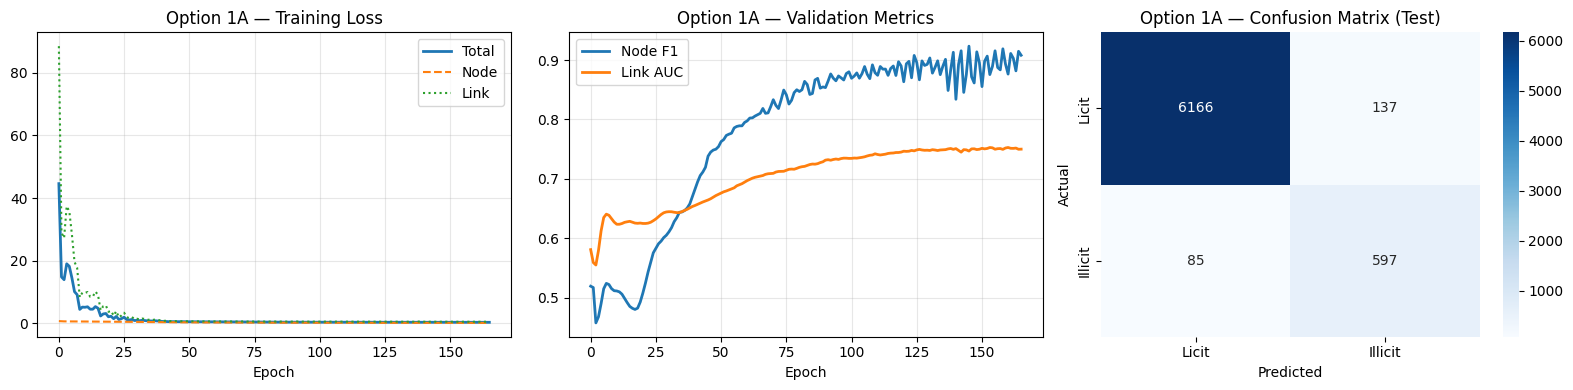

✓ Saved option1a_results.png


In [10]:
print("=" * 65)
print("OPTION 1A — TEST RESULTS")
print("=" * 65)
for split in ['train','val','test']:
    m = evaluate(model_1a, data, split, device)
    print(f"\n{split.upper()}")
    print(f"  Node | F1-macro {m['node_f1_macro']:.4f} | F1-illicit {m['node_f1_illicit']:.4f} | Precision {m['node_precision']:.4f} | Recall {m['node_recall']:.4f} | AUC {m['node_auc']:.4f}")
    print(f"  Link | AUC {m['link_auc']:.4f} | AP {m['link_ap']:.4f}")
test_1a = evaluate(model_1a, data, 'test', device)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ep = range(len(history_1a['total']))
axes[0].plot(ep, history_1a['total'], label='Total', lw=2)
axes[0].plot(ep, history_1a['node'],  label='Node',  ls='--')
axes[0].plot(ep, history_1a['link'],  label='Link',  ls=':')
axes[0].set_title('Option 1A — Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, history_1a['val_f1'],       label='Node F1', lw=2)
axes[1].plot(ep, history_1a['val_link_auc'], label='Link AUC', lw=2)
axes[1].set_title('Option 1A — Validation Metrics'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)
cm = get_confusion(model_1a, data, 'test', device)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Licit','Illicit'], yticklabels=['Licit','Illicit'])
axes[2].set_title('Option 1A — Confusion Matrix (Test)')
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('Actual')
plt.tight_layout(); plt.savefig('option1a_results.png', dpi=150, bbox_inches='tight'); plt.show()
print("\u2713 Saved option1a_results.png")

## 8. Option 1B — Fraud-Label Constrained Training

In [11]:
print("=" * 65)
print("OPTION 1B: FRAUD-LABEL CONSTRAINED LINK PREDICTION")
print(f"Lambda = {LAMBDA}")
print("=" * 65)

torch.manual_seed(SEED); np.random.seed(SEED)  # re-seed before model init
model_1b = ConstrainedDualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
opt_1b   = torch.optim.Adam(model_1b.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
torch.manual_seed(SEED)  # re-seed before training starts
history_1b = training_loop(model_1b, train_1b, {'optimizer': opt_1b, 'alpha': ALPHA, 'lam': LAMBDA}, "Option 1B", data=data)

OPTION 1B: FRAUD-LABEL CONSTRAINED LINK PREDICTION
Lambda = 1.0
Ep 000 | Loss 44.9790 (N 0.7198 L 89.2383  C 0.7304) | ValF1 0.5338 | ValAUC 0.5749
Ep 005 | Loss 14.1394 (N 0.6194 L 27.6594  C 0.5423) | ValF1 0.5161 | ValAUC 0.6025
Ep 006 | Loss 9.8615 (N 0.6121 L 19.1109  C 0.5176) | ValF1 0.5242 | ValAUC 0.6042
Ep 020 | Loss 2.5589 (N 0.5221 L 4.5957  C 0.4633) | ValF1 0.5218 | ValAUC 0.5792
Ep 023 | Loss 1.8299 (N 0.5120 L 3.1477  C 0.4606) | ValF1 0.5553 | ValAUC 0.5842
Ep 024 | Loss 1.8113 (N 0.5033 L 3.1194  C 0.4492) | ValF1 0.5662 | ValAUC 0.5856
Ep 025 | Loss 2.0374 (N 0.4971 L 3.5776  C 0.4543) | ValF1 0.5713 | ValAUC 0.5867
Ep 026 | Loss 1.6957 (N 0.4882 L 2.9032  C 0.4601) | ValF1 0.5805 | ValAUC 0.5879
Ep 027 | Loss 1.9273 (N 0.4867 L 3.3679  C 0.4527) | ValF1 0.5849 | ValAUC 0.5889
Ep 028 | Loss 1.3612 (N 0.4762 L 2.2463  C 0.4493) | ValF1 0.5890 | ValAUC 0.5901
Ep 029 | Loss 1.1709 (N 0.4738 L 1.8680  C 0.4400) | ValF1 0.5912 | ValAUC 0.5920
Ep 030 | Loss 1.1804 (N 0.467

### Option 1B — Results

OPTION 1B — TEST RESULTS

TRAIN
  Node | F1-macro 0.9082 | F1-illicit 0.8367 | Precision 0.7472 | Recall 0.9506 | AUC 0.9924
  Link | AUC 0.8383 | AP 0.8432

VAL
  Node | F1-macro 0.8934 | F1-illicit 0.8104 | Precision 0.7254 | Recall 0.9179 | AUC 0.9828
  Link | AUC 0.6855 | AP 0.6863

TEST
  Node | F1-macro 0.8968 | F1-illicit 0.8161 | Precision 0.7413 | Recall 0.9076 | AUC 0.9856
  Link | AUC 0.6813 | AP 0.6794


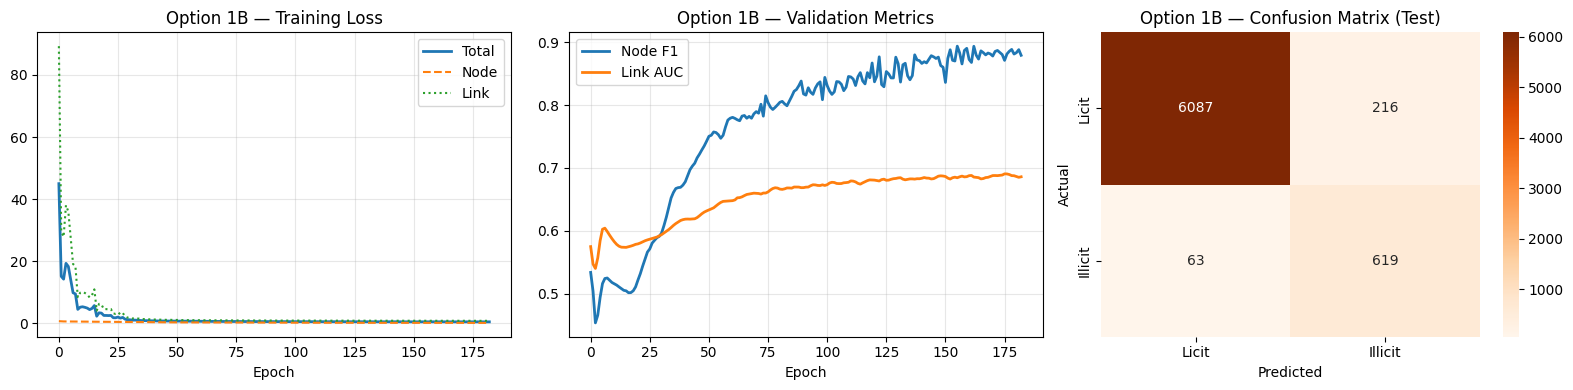

✓ Saved option1b_results.png


In [12]:
print("=" * 65)
print("OPTION 1B — TEST RESULTS")
print("=" * 65)
for split in ['train','val','test']:
    m = evaluate(model_1b, data, split, device, constrained=True)
    print(f"\n{split.upper()}")
    print(f"  Node | F1-macro {m['node_f1_macro']:.4f} | F1-illicit {m['node_f1_illicit']:.4f} | Precision {m['node_precision']:.4f} | Recall {m['node_recall']:.4f} | AUC {m['node_auc']:.4f}")
    print(f"  Link | AUC {m['link_auc']:.4f} | AP {m['link_ap']:.4f}")
test_1b = evaluate(model_1b, data, 'test', device, constrained=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ep = range(len(history_1b['total']))
axes[0].plot(ep, history_1b['total'], label='Total', lw=2)
axes[0].plot(ep, history_1b['node'],  label='Node',  ls='--')
axes[0].plot(ep, history_1b['link'],  label='Link',  ls=':')
axes[0].set_title('Option 1B — Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, history_1b['val_f1'],       label='Node F1', lw=2)
axes[1].plot(ep, history_1b['val_link_auc'], label='Link AUC', lw=2)
axes[1].set_title('Option 1B — Validation Metrics'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)
cm = get_confusion(model_1b, data, 'test', device, constrained=True)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            xticklabels=['Licit','Illicit'], yticklabels=['Licit','Illicit'])
axes[2].set_title('Option 1B — Confusion Matrix (Test)')
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('Actual')
plt.tight_layout(); plt.savefig('option1b_results.png', dpi=150, bbox_inches='tight'); plt.show()
print("\u2713 Saved option1b_results.png")

## 9. Fraud-Label Constraint Analysis

The constraint should suppress predicted scores for cross-class (illicit↔licit) edges well below within-class scores. Analysis runs on both val and test splits to check consistency.

In [13]:
@torch.no_grad()
def analyze_constraint(model, data, split, device):
    model.eval()
    x, y = data.x.to(device), data.y.to(device)
    ei   = getattr(data, f'{split}_msg_edge_index').to(device)
    eli  = getattr(data, f'{split}_edge_label_index').to(device)
    _, link_pred, _ = model.forward_with_constraint(x, ei, eli, y)
    probs      = torch.sigmoid(link_pred).cpu().numpy()
    src_labels = y[eli[0]].cpu().numpy()
    dst_labels = y[eli[1]].cpu().numpy()

    ii = (src_labels == 1) & (dst_labels == 1)
    ll = (src_labels == 0) & (dst_labels == 0)
    cc = ((src_labels == 0) & (dst_labels == 1)) | ((src_labels == 1) & (dst_labels == 0))

    return {
        'illicit_illicit': float(probs[ii].mean()) if ii.any() else 0.0,
        'licit_licit'    : float(probs[ll].mean()) if ll.any() else 0.0,
        'cross_class'    : float(probs[cc].mean()) if cc.any() else 0.0,
        'n_ii': int(ii.sum()), 'n_ll': int(ll.sum()), 'n_cc': int(cc.sum()),
        'probs_ii': probs[ii], 'probs_ll': probs[ll], 'probs_cc': probs[cc],
    }

print("=" * 65)
print("CONSTRAINT IMPACT ANALYSIS")
print("=" * 65)

for split in ['val','test']:
    s = analyze_constraint(model_1b, data, split, device)
    reduction = min(s['illicit_illicit'], s['licit_licit']) - s['cross_class']
    strength  = "Strong" if reduction > 0.10 else ("Moderate" if reduction > 0.03 else "Weak")
    print(f"\n{split.upper()}")
    print(f"  Illicit-Illicit : {s['illicit_illicit']:.4f}  (n={s['n_ii']:,})")
    print(f"  Licit-Licit     : {s['licit_licit']:.4f}  (n={s['n_ll']:,})")
    print(f"  Cross-class     : {s['cross_class']:.4f}  (n={s['n_cc']:,})  \u2190 penalised by constraint")
    print(f"  Reduction       : {reduction:.4f}  [{strength}]")

constraint_stats = analyze_constraint(model_1b, data, 'test', device)
constraint_stats['reduction'] = min(constraint_stats['illicit_illicit'], constraint_stats['licit_licit']) - constraint_stats['cross_class']

CONSTRAINT IMPACT ANALYSIS

VAL
  Illicit-Illicit : 0.7439  (n=243)
  Licit-Licit     : 0.7043  (n=8,915)
  Cross-class     : 0.2859  (n=652)  ← penalised by constraint
  Reduction       : 0.4184  [Strong]

TEST
  Illicit-Illicit : 0.7481  (n=233)
  Licit-Licit     : 0.7076  (n=9,008)
  Cross-class     : 0.2887  (n=682)  ← penalised by constraint
  Reduction       : 0.4189  [Strong]


### Constraint Score Distribution

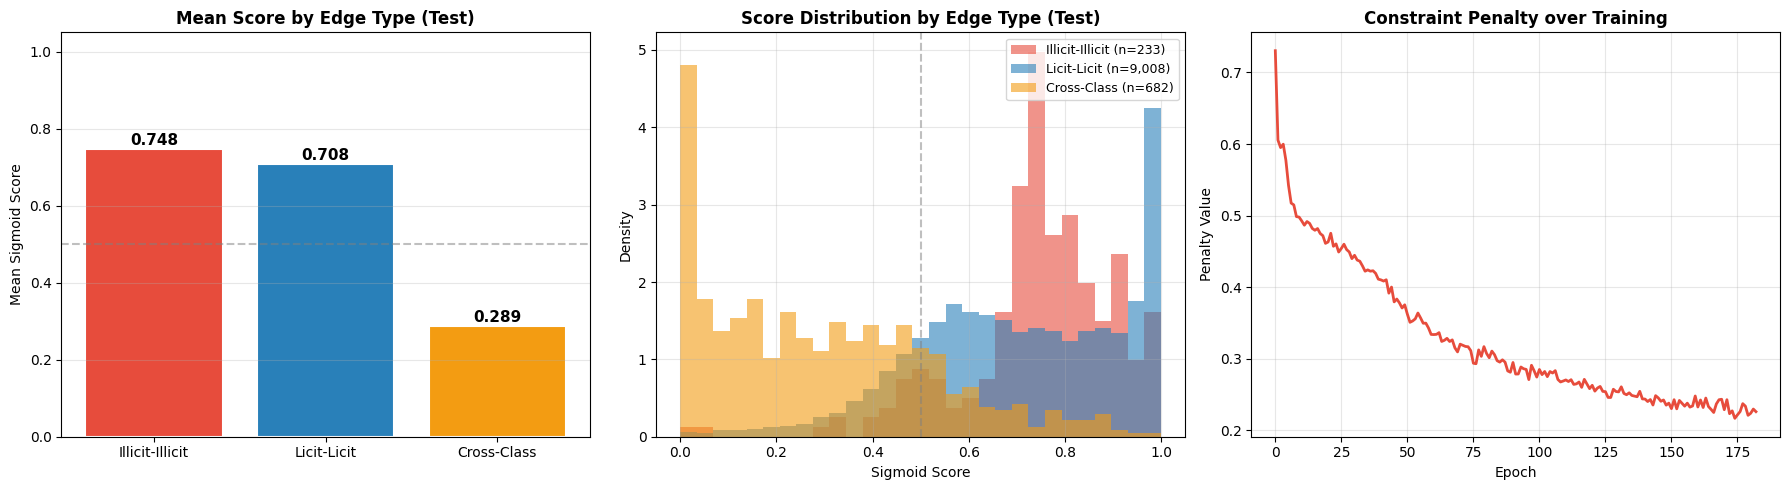

✓ Saved constraint_analysis.png


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mean scores by edge type
types   = ['Illicit-Illicit','Licit-Licit','Cross-Class']
means   = [constraint_stats['illicit_illicit'], constraint_stats['licit_licit'], constraint_stats['cross_class']]
colours = ['#e74c3c','#2980b9','#f39c12']
bars = axes[0].bar(types, means, color=colours, edgecolor='white', linewidth=1.5)
for b, v in zip(bars, means):
    axes[0].text(b.get_x()+b.get_width()/2, v+0.01, f'{v:.3f}', ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylim(0, 1.05)
axes[0].axhline(0.5, color='grey', ls='--', alpha=0.5)
axes[0].set_title('Mean Score by Edge Type (Test)', fontweight='bold')
axes[0].set_ylabel('Mean Sigmoid Score'); axes[0].grid(axis='y', alpha=0.3)

# Score distribution histogram
bins = np.linspace(0, 1, 30)
axes[1].hist(constraint_stats['probs_ii'], bins=bins, alpha=0.6, color='#e74c3c',
             label=f'Illicit-Illicit (n={constraint_stats["n_ii"]:,})', density=True)
axes[1].hist(constraint_stats['probs_ll'], bins=bins, alpha=0.6, color='#2980b9',
             label=f'Licit-Licit (n={constraint_stats["n_ll"]:,})', density=True)
axes[1].hist(constraint_stats['probs_cc'], bins=bins, alpha=0.6, color='#f39c12',
             label=f'Cross-Class (n={constraint_stats["n_cc"]:,})', density=True)
axes[1].axvline(0.5, color='grey', ls='--', alpha=0.5)
axes[1].set_title('Score Distribution by Edge Type (Test)', fontweight='bold')
axes[1].set_xlabel('Sigmoid Score'); axes[1].set_ylabel('Density'); axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

# Constraint penalty over training
# Check if data exists and plot if it does
if history_1b.get('constraint') and len(history_1b['constraint']) > 0:
    axes[2].plot(history_1b['constraint'], color='#e74c3c', lw=2)
else:
    axes[2].text(0.5, 0.5, 'No constraint penalty data', ha='center', va='center', transform=axes[2].transAxes)

# Set labels
axes[2].set_title('Constraint Penalty over Training', fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Penalty Value')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('constraint_analysis.png', dpi=150, bbox_inches='tight'); plt.show()
print("\u2713 Saved constraint_analysis.png")

## 10. Comparative Analysis

In [15]:
print("=" * 70)
print("OPTION 1A vs 1B — FINAL COMPARISON (TEST SET)")
print("=" * 70)
print(f"{'Metric':<28} {'1A (Joint)':>12} {'1B (Constrained)':>18} {'Change':>8}")
print("-" * 70)

metrics = [
    ("Node F1 (macro)",         'node_f1_macro'),
    ("Node F1 (illicit)",       'node_f1_illicit'),
    ("Node Precision",          'node_precision'),
    ("Node Recall",             'node_recall'),
    ("Node AUC",                'node_auc'),
    ("Link AUC",                'link_auc'),
    ("Link AP",                 'link_ap'),
]
for label, key in metrics:
    v1a, v1b = test_1a[key], test_1b[key]
    d = v1b - v1a
    tag = "\u2191" if d > 0.0005 else ("\u2193" if d < -0.0005 else "\u2248")
    print(f"  {label:<26} {v1a:>10.4f}   {v1b:>16.4f}   {tag}{abs(d):.4f}")

print(f"\nConstraint Analysis (1B, Test):")
print(f"  Illicit-Illicit : {constraint_stats['illicit_illicit']:.4f}  (n={constraint_stats['n_ii']:,})")
print(f"  Licit-Licit     : {constraint_stats['licit_licit']:.4f}  (n={constraint_stats['n_ll']:,})")
print(f"  Cross-class     : {constraint_stats['cross_class']:.4f}  (n={constraint_stats['n_cc']:,})  \u2190 penalised")
print(f"  Reduction       : {constraint_stats['reduction']:.4f}")

print("\n" + "=" * 70)
print("CONTEXTUAL COMPARISON WITH PRIOR ELLIPTIC WORK (NODE CLASSIFICATION)")
print("=" * 70)
# Illicit-class F1 (not macro-F1) -- this is the metric Weber et al. (2019)
# actually report (Table 1, "all features" variant), verified directly against
# the primary source (arXiv:1908.02591). See Section 11 for the full citation
# and the random-vs-temporal-split caveat; the fully protocol-matched
# comparison (same split as Weber et al.) is in Section 16, Experiment F.
n_nodes_here = data.x.shape[0]
print(f"Note: Weber et al. (2019) used the full 203,769-node graph with a temporal")
print(f"split. This run uses {n_nodes_here:,} nodes; see Section 16 for the temporal-split,")
print(f"protocol-matched version of this comparison.\n")
prior = [
    ("Weber et al. (2019) — GCN",                 0.628),
    ("Weber et al. (2019) — Skip-GCN",             0.705),
    ("Weber et al. (2019) — Random Forest",        0.788),

]
for study, f1 in prior:
    marker = "  \u2190 this work" if "This work" in study else ""
    print(f"  {study:<45} F1-illicit {f1:.4f}{marker}")

OPTION 1A vs 1B — FINAL COMPARISON (TEST SET)
Metric                         1A (Joint)   1B (Constrained)   Change
----------------------------------------------------------------------
  Node F1 (macro)                0.9128             0.8968   ↓0.0159
  Node F1 (illicit)              0.8432             0.8161   ↓0.0271
  Node Precision                 0.8134             0.7413   ↓0.0720
  Node Recall                    0.8754             0.9076   ↑0.0323
  Node AUC                       0.9853             0.9856   ≈0.0003
  Link AUC                       0.7393             0.6813   ↓0.0580
  Link AP                        0.7382             0.6794   ↓0.0587

Constraint Analysis (1B, Test):
  Illicit-Illicit : 0.7481  (n=233)
  Licit-Licit     : 0.7076  (n=9,008)
  Cross-class     : 0.2887  (n=682)  ← penalised
  Reduction       : 0.4189

CONTEXTUAL COMPARISON WITH PRIOR ELLIPTIC WORK (NODE CLASSIFICATION)
Note: Weber et al. (2019) used the full 203,769-node graph with a temporal
sp

## 11. Baseline Comparison — Node Classification on Elliptic

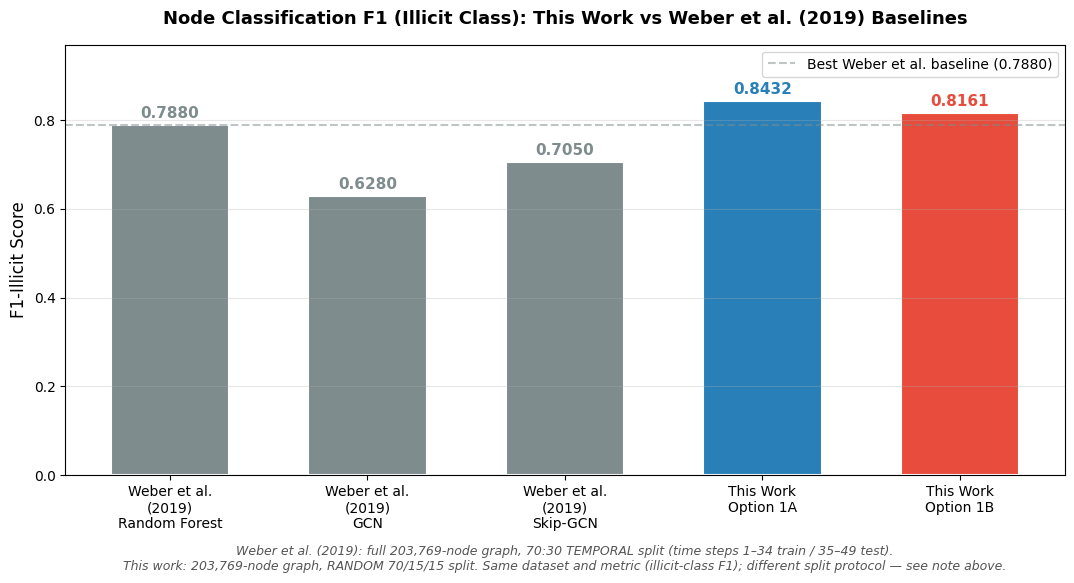

✓ Saved baseline_comparison.png

Source: Weber et al. (2019), 'Anti-Money Laundering in Bitcoin: Experimenting with GNNs',
arXiv:1908.02591, Table 1 (All Features variant). Numbers verified against the primary source.


In [16]:
# Prior work results on the full Elliptic dataset (203,769 nodes), Weber et al. (2019),
# Table 1, "all features" (AF) variant — verified directly against the primary source
# (arXiv:1908.02591). These are ILLICIT-CLASS F1 scores, which is what the original
# paper reports; macro-F1 is not published for these baselines, so this work's
# illicit-F1 (not macro-F1) is used below for a fair, correctly-cited comparison.
#
# IMPORTANT CAVEAT: Weber et al. (2019) use a 70:30 TEMPORAL split (train on time
# steps 1–34, test on 35–49) — not a random split. Until this notebook also moves to
# a temporal split, this remains a partial comparison: same dataset and metric, but a
# different (and generally easier) evaluation protocol. This is called out explicitly
# below and should stay in any figure caption drawn from this cell.

prior_labels  = ["Weber et al.\n(2019)\nRandom Forest", "Weber et al.\n(2019)\nGCN",
                 "Weber et al.\n(2019)\nSkip-GCN",
                 "This Work\nOption 1A", "This Work\nOption 1B"]
prior_f1      = [0.788, 0.628, 0.705,
                 round(test_1a['node_f1_illicit'], 4),
                 round(test_1b['node_f1_illicit'], 4)]
colours       = ['#7f8c8d','#7f8c8d','#7f8c8d','#2980b9','#e74c3c']

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(prior_labels, prior_f1, color=colours, edgecolor='white', linewidth=1.5, width=0.6)

for b, v, c in zip(bars, prior_f1, colours):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.4f}',
            ha='center', va='bottom', fontweight='bold', fontsize=11, color=c)

ax.set_ylim(0.0, max(prior_f1) * 1.15)
ax.set_ylabel('F1-Illicit Score', fontsize=12)
ax.set_title('Node Classification F1 (Illicit Class): This Work vs Weber et al. (2019) Baselines',
             fontsize=13, fontweight='bold', pad=15)
ax.axhline(y=max(prior_f1[:3]), color='#7f8c8d', ls='--', alpha=0.5,
           label=f'Best Weber et al. baseline ({max(prior_f1[:3]):.4f})')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', labelsize=10)

n_nodes = data.x.shape[0]
note = (f"Weber et al. (2019): full 203,769-node graph, 70:30 TEMPORAL split (time steps 1\u201334 train / 35\u201349 test).\n"
        f"This work: {n_nodes:,}-node graph, RANDOM 70/15/15 split. Same dataset and metric (illicit-class F1); "
        f"different split protocol \u2014 see note above.")
ax.text(0.5, -0.22, note, ha='center', transform=ax.transAxes,
        fontsize=9, color='#555555', style='italic')

plt.tight_layout()
plt.savefig('baseline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Saved baseline_comparison.png")
print("\nSource: Weber et al. (2019), 'Anti-Money Laundering in Bitcoin: Experimenting with GNNs',")
print("arXiv:1908.02591, Table 1 (All Features variant). Numbers verified against the primary source.")

## 12. Experiment A — Node-Only GraphSAGE Baseline

Trains a node classification-only GraphSAGE model on the same subgraph and split.
This is the directly-replicated single-task baseline requested by the supervisor.
The cell below is one quick run on the random split. The reported comparison is the 8-seed, two-split version added below Section 23 (node_only_results). This model stops on validation macro-F1, its own task metric. Options 1A and 1B stop on the mean of validation macro-F1 and validation link AUC.

In [17]:
# ── Node-only GraphSAGE (single-task baseline) ───────────────────────────────
class NodeOnlyGNN(nn.Module):
    """Single-task GraphSAGE for node classification only. No link prediction head."""
    def __init__(self, in_channels, hidden_channels, num_classes, dropout=0.5):
        super().__init__()
        self.conv1     = SAGEConv(in_channels, hidden_channels)
        self.conv2     = SAGEConv(hidden_channels, hidden_channels)
        self.node_head = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels // 2, num_classes)
        )
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return self.node_head(x)

def train_node_only(model, data, optimizer, device):
    model.train()
    optimizer.zero_grad()
    logits = model(data.x.to(device), data.edge_index.to(device))
    loss   = node_loss_fn(logits, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    loss.backward(); optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate_node_only(model, data, split, device):
    model.eval()
    x, y = data.x.to(device), data.y.to(device)
    ei   = data.full_edge_index.to(device)
    mask = {'train': data.train_mask, 'val': data.val_mask, 'test': data.test_mask}[split].to(device)
    logits = model(x, ei)
    yt = y[mask].cpu().numpy()
    yp = logits[mask].argmax(-1).cpu().numpy()
    yb = F.softmax(logits[mask], dim=-1)[:, 1].cpu().numpy()
    return {
        'node_f1_macro'  : f1_score(yt, yp, average='macro',  zero_division=0),
        'node_f1_illicit': f1_score(yt, yp, average='binary', zero_division=0),
        'node_precision' : precision_score(yt, yp, zero_division=0),
        'node_recall'    : recall_score(yt, yp, zero_division=0),
        'node_auc'       : roc_auc_score(yt, yb) if len(np.unique(yt)) > 1 else 0.0,
    }

print("=" * 65)
print("EXPERIMENT A: NODE-ONLY GRAPHSAGE BASELINE")
print("=" * 65)

torch.manual_seed(SEED); np.random.seed(SEED)  # re-seed before model init
model_baseline = NodeOnlyGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
opt_baseline   = torch.optim.Adam(model_baseline.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

best_val = 0.0; best_state = None; patience_b = 0
from datetime import datetime
start = datetime.now()

for epoch in range(NUM_EPOCHS):
    loss = train_node_only(model_baseline, data, opt_baseline, device)
    vm   = evaluate_node_only(model_baseline, data, 'val', device)
    val_f1 = vm['node_f1_macro']
    if val_f1 > best_val:
        best_val = val_f1; patience_b = 0
        best_state = {k: v.cpu().clone() for k, v in model_baseline.state_dict().items()}
    else:
        patience_b += 1
    if epoch % 20 == 0 or patience_b == 0:
        print(f"Ep {epoch:03d} | Loss {loss:.4f} | Val F1 {val_f1:.4f}")
    if patience_b >= PATIENCE and epoch >= MIN_EPOCHS:
        print(f"\nEarly stopping at epoch {epoch}")
        break

model_baseline.load_state_dict(best_state)
elapsed = (datetime.now() - start).total_seconds()
print(f"\n✓ Baseline trained in {elapsed:.1f}s")

baseline_test = evaluate_node_only(model_baseline, data, 'test', device)
print("\nNODE-ONLY BASELINE — TEST RESULTS")
print(f"  F1-Macro   : {baseline_test['node_f1_macro']:.4f}")
print(f"  F1-Illicit : {baseline_test['node_f1_illicit']:.4f}")
print(f"  Precision  : {baseline_test['node_precision']:.4f}")
print(f"  Recall     : {baseline_test['node_recall']:.4f}")
print(f"  Node AUC   : {baseline_test['node_auc']:.4f}")


EXPERIMENT A: NODE-ONLY GRAPHSAGE BASELINE
Ep 000 | Loss 0.7198 | Val F1 0.4743
Ep 001 | Loss 0.6354 | Val F1 0.6937
Ep 006 | Loss 0.4087 | Val F1 0.7087
Ep 008 | Loss 0.3759 | Val F1 0.7221
Ep 009 | Loss 0.3429 | Val F1 0.7439
Ep 010 | Loss 0.3262 | Val F1 0.7622
Ep 011 | Loss 0.3093 | Val F1 0.7631
Ep 013 | Loss 0.2938 | Val F1 0.7778
Ep 014 | Loss 0.2778 | Val F1 0.8070
Ep 015 | Loss 0.2682 | Val F1 0.8192
Ep 018 | Loss 0.2433 | Val F1 0.8229
Ep 019 | Loss 0.2358 | Val F1 0.8338
Ep 020 | Loss 0.2254 | Val F1 0.8391
Ep 021 | Loss 0.2237 | Val F1 0.8414
Ep 022 | Loss 0.2155 | Val F1 0.8463
Ep 023 | Loss 0.2108 | Val F1 0.8674
Ep 024 | Loss 0.2035 | Val F1 0.8798
Ep 029 | Loss 0.1837 | Val F1 0.8844
Ep 033 | Loss 0.1737 | Val F1 0.8886
Ep 037 | Loss 0.1572 | Val F1 0.8930
Ep 038 | Loss 0.1567 | Val F1 0.8938
Ep 040 | Loss 0.1498 | Val F1 0.8946
Ep 041 | Loss 0.1441 | Val F1 0.9019
Ep 042 | Loss 0.1449 | Val F1 0.9046
Ep 046 | Loss 0.1380 | Val F1 0.9065
Ep 050 | Loss 0.1323 | Val F1 0.

## 13. Experiment B — Lambda Sensitivity Sweep

Trains Option 1B with lambda values of 0.1, 0.5, 1.0, and 2.0 to characterise
the trade-off between node classification gain and link prediction accuracy.
This addresses the supervisor's request for systematic constraint weight analysis.

EXPERIMENT B: LAMBDA SENSITIVITY SWEEP

--- Lambda = 0.1 ---
  F1-macro=0.9081  Link AUC=0.7210  Reduction=0.2103  Cross-class=0.4594

--- Lambda = 0.5 ---
  F1-macro=0.9101  Link AUC=0.6974  Reduction=0.3574  Cross-class=0.3296

--- Lambda = 1.0 ---
  F1-macro=0.8968  Link AUC=0.6813  Reduction=0.4189  Cross-class=0.2887

--- Lambda = 2.0 ---
  F1-macro=0.8806  Link AUC=0.6514  Reduction=0.4683  Cross-class=0.2506

LAMBDA SWEEP SUMMARY
  Lambda   F1-Macro   F1-Illicit   Recall   Link AUC   Reduction  Cross-Class
----------------------------------------------------------------------
     0.1     0.9081       0.8350   0.8754     0.7210      0.2103       0.4594
     0.5     0.9101       0.8390   0.9018     0.6974      0.3574       0.3296
     1.0     0.8968       0.8161   0.9076     0.6813      0.4189       0.2887
     2.0     0.8806       0.7880   0.9076     0.6514      0.4683       0.2506


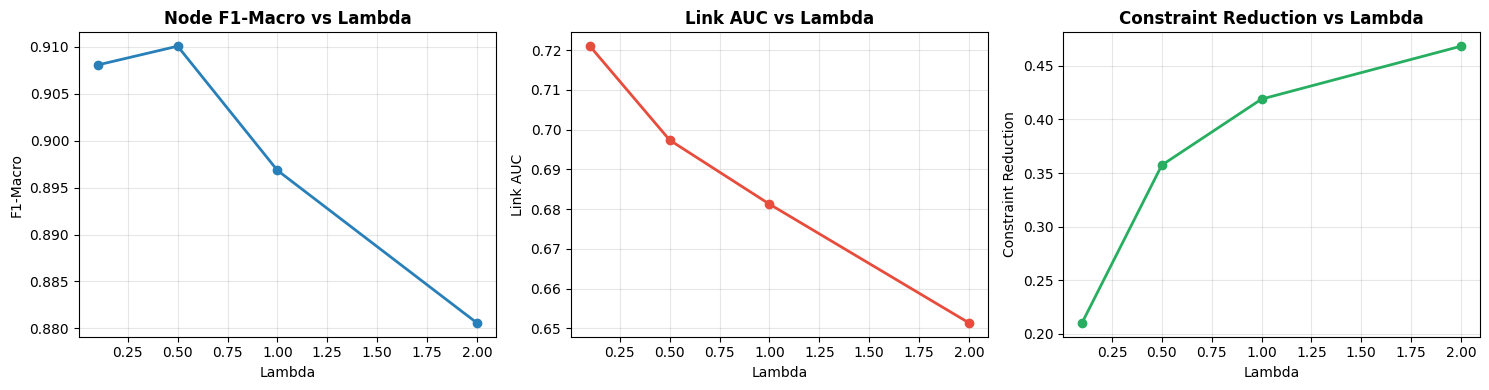

✓ Saved lambda_sweep.png


In [18]:
# ── Lambda sensitivity sweep ─────────────────────────────────────────────────
LAMBDA_VALUES = [0.1, 0.5, 1.0, 2.0]
lambda_results = []

print("=" * 70)
print("EXPERIMENT B: LAMBDA SENSITIVITY SWEEP")
print("=" * 70)

for lam in LAMBDA_VALUES:
    print(f"\n--- Lambda = {lam} ---")
    # Re-seed fully before each lambda model init and training
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

    m_lam = ConstrainedDualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    o_lam = torch.optim.Adam(m_lam.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    best_v = 0.0; best_s = None; pat = 0
    for epoch in range(NUM_EPOCHS):
        tr = train_1b(m_lam, data, o_lam, ALPHA, lam, device)
        vm = evaluate(m_lam, data, 'val', device, constrained=True)
        vs = (vm['node_f1_macro'] + vm['link_auc']) / 2
        if vs > best_v:
            best_v = vs; pat = 0
            best_s = {k: v.cpu().clone() for k, v in m_lam.state_dict().items()}
        else:
            pat += 1
        if pat >= PATIENCE and epoch >= MIN_EPOCHS:
          break

    m_lam.load_state_dict(best_s)
    test_m = evaluate(m_lam, data, 'test', device, constrained=True)

    # Constraint analysis for this lambda
    ca = analyze_constraint(m_lam, data, 'test', device)
    reduction = min(ca['illicit_illicit'], ca['licit_licit']) - ca['cross_class']

    result = {
        'lambda'       : lam,
        'f1_macro'     : test_m['node_f1_macro'],
        'f1_illicit'   : test_m['node_f1_illicit'],
        'recall'       : test_m['node_recall'],
        'link_auc'     : test_m['link_auc'],
        'reduction'    : reduction,
        'cross_class'  : ca['cross_class'],
    }
    lambda_results.append(result)
    print(f"  F1-macro={result['f1_macro']:.4f}  Link AUC={result['link_auc']:.4f}  Reduction={result['reduction']:.4f}  Cross-class={result['cross_class']:.4f}")

print("\n" + "=" * 70)
print("LAMBDA SWEEP SUMMARY")
print("=" * 70)
print(f"{'Lambda':>8} {'F1-Macro':>10} {'F1-Illicit':>12} {'Recall':>8} {'Link AUC':>10} {'Reduction':>11} {'Cross-Class':>12}")
print("-" * 70)
for r in lambda_results:
    print(f"  {r['lambda']:>6} {r['f1_macro']:>10.4f} {r['f1_illicit']:>12.4f} {r['recall']:>8.4f} {r['link_auc']:>10.4f} {r['reduction']:>11.4f} {r['cross_class']:>12.4f}")

# Plot lambda trade-off
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lambdas    = [r['lambda'] for r in lambda_results]
axes[0].plot(lambdas, [r['f1_macro'] for r in lambda_results], 'o-', color='#2980b9', lw=2)
axes[0].set_xlabel('Lambda'); axes[0].set_ylabel('F1-Macro'); axes[0].set_title('Node F1-Macro vs Lambda', fontweight='bold'); axes[0].grid(alpha=0.3)
axes[1].plot(lambdas, [r['link_auc'] for r in lambda_results], 'o-', color='#e74c3c', lw=2)
axes[1].set_xlabel('Lambda'); axes[1].set_ylabel('Link AUC'); axes[1].set_title('Link AUC vs Lambda', fontweight='bold'); axes[1].grid(alpha=0.3)
axes[2].plot(lambdas, [r['reduction'] for r in lambda_results], 'o-', color='#27ae60', lw=2)
axes[2].set_xlabel('Lambda'); axes[2].set_ylabel('Constraint Reduction'); axes[2].set_title('Constraint Reduction vs Lambda', fontweight='bold'); axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lambda_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved lambda_sweep.png")


**Reading this sweep:** lambda trades node classification F1 against constraint strength (cross-class reduction) and link prediction AUC, but not monotonically in F1, small F1 differences between adjacent lambda values here are within the run-to-run noise band measured later by the multi-seed experiments (Section 15), not evidence that a particular lambda is reliably best. Since `LAMBDA = 1.0` was fixed before this sweep was run, not chosen from it (see the note in Section 2), this chart is reported as a sensitivity analysis, showing the shape of the trade-off, rather than as a justification for the specific value used. A properly leakage-free lambda search, selecting on validation performance rather than the metrics shown here, is noted as future work.

## 14. Experiment C — Statistical Significance

Bootstrap confidence interval on the constraint reduction and
McNemar test comparing Option 1A vs Option 1B node classification predictions.
Both tests were requested by the supervisor to check whether the results are statistically robust.

In [19]:
# ── Statistical significance analysis ────────────────────────────────────────
from scipy.stats import chi2
from scipy import stats

print("=" * 65)
print("EXPERIMENT C: STATISTICAL SIGNIFICANCE")
print("=" * 65)

# ── 1. Bootstrap CI on constraint reduction ───────────────────────────────────
@torch.no_grad()
def get_constraint_probs(model, data, split, device):
    model.eval()
    x, y = data.x.to(device), data.y.to(device)
    ei   = getattr(data, f'{split}_msg_edge_index').to(device)
    eli  = getattr(data, f'{split}_edge_label_index').to(device)
    _, link_pred, _ = model.forward_with_constraint(x, ei, eli, y)
    probs      = torch.sigmoid(link_pred).cpu().numpy()
    src_labels = y[eli[0]].cpu().numpy()
    dst_labels = y[eli[1]].cpu().numpy()
    ii = (src_labels == 1) & (dst_labels == 1)
    ll = (src_labels == 0) & (dst_labels == 0)
    cc = ((src_labels == 0) & (dst_labels == 1)) | ((src_labels == 1) & (dst_labels == 0))
    return probs, ii, ll, cc

probs, ii, ll, cc = get_constraint_probs(model_1b, data, 'test', device)

def bootstrap_reduction(probs, ii, ll, cc, n_bootstrap=10000, seed=42):
    rng = np.random.RandomState(seed)
    reductions = []
    for _ in range(n_bootstrap):
        ii_s = probs[ii][rng.randint(0, ii.sum(), ii.sum())]
        ll_s = probs[ll][rng.randint(0, ll.sum(), ll.sum())]
        cc_s = probs[cc][rng.randint(0, cc.sum(), cc.sum())]
        red  = min(ii_s.mean(), ll_s.mean()) - cc_s.mean()
        reductions.append(red)
    return np.array(reductions)

print("\nRunning 10,000 bootstrap iterations...")
bs_reductions = bootstrap_reduction(probs, ii, ll, cc)
ci_low, ci_high = np.percentile(bs_reductions, [2.5, 97.5])
print(f"\nConstraint Reduction Bootstrap CI (95%):")
print(f"  Point estimate : {np.mean(bs_reductions):.4f}")
print(f"  95% CI         : [{ci_low:.4f}, {ci_high:.4f}]")
print(f"  Std deviation  : {np.std(bs_reductions):.4f}")
print(f"  CI excludes 0  : {ci_low > 0}")

# ── 2. McNemar test: Option 1A vs Option 1B node predictions ─────────────────
@torch.no_grad()
def get_predictions(model, data, device, constrained=False):
    model.eval()
    x, y = data.x.to(device), data.y.to(device)
    ei   = data.full_edge_index.to(device)
    eli  = data.test_edge_label_index.to(device)
    mask = data.test_mask.to(device)
    if constrained:
        node_pred, _, _ = model.forward_with_constraint(x, ei, eli, y)
    else:
        node_pred, _ = model(x, ei, eli)
    y_true = y[mask].cpu().numpy()
    y_pred = node_pred[mask].argmax(-1).cpu().numpy()
    return y_true, y_pred

y_true, y_pred_1a = get_predictions(model_1a, data, device, constrained=False)
_,      y_pred_1b = get_predictions(model_1b, data, device, constrained=True)

# McNemar contingency table
b = np.sum((y_pred_1a == y_true) & (y_pred_1b != y_true))  # 1A correct, 1B wrong
c = np.sum((y_pred_1a != y_true) & (y_pred_1b == y_true))  # 1A wrong, 1B correct

# McNemar statistic with continuity correction
if b + c > 0:
    mcnemar_stat = (abs(b - c) - 1) ** 2 / (b + c)
    p_value = 1 - chi2.cdf(mcnemar_stat, df=1)
else:
    mcnemar_stat = 0.0
    p_value = 1.0

print(f"\nMcNemar Test (1A vs 1B node classification):")
print(f"  1A correct, 1B wrong (b) : {b}")
print(f"  1A wrong, 1B correct (c) : {c}")
print(f"  McNemar statistic        : {mcnemar_stat:.4f}")
print(f"  p-value                  : {p_value:.4f}")
print(f"  Significant (p<0.05)     : {p_value < 0.05}")
print(f"  Significant (p<0.01)     : {p_value < 0.01}")

if p_value < 0.05:
    print("\n✓ The difference between Option 1A and Option 1B predictions is statistically significant.")
else:
    print("\n⚠ The difference is not statistically significant at p<0.05.")


EXPERIMENT C: STATISTICAL SIGNIFICANCE

Running 10,000 bootstrap iterations...

Constraint Reduction Bootstrap CI (95%):
  Point estimate : 0.4188
  95% CI         : [0.4013, 0.4361]
  Std deviation  : 0.0090
  CI excludes 0  : True

McNemar Test (1A vs 1B node classification):
  1A correct, 1B wrong (b) : 116
  1A wrong, 1B correct (c) : 59
  McNemar statistic        : 17.9200
  p-value                  : 0.0000
  Significant (p<0.05)     : True
  Significant (p<0.01)     : True

✓ The difference between Option 1A and Option 1B predictions is statistically significant.


In [20]:
@torch.no_grad()
def edge_group_scores(model, data_obj, split, device, constrained):
    model.eval()
    x, y = data_obj.x.to(device), data_obj.y.to(device)
    ei  = getattr(data_obj, f'{split}_msg_edge_index').to(device)
    eli = getattr(data_obj, f'{split}_edge_label_index').to(device)
    el  = getattr(data_obj, f'{split}_edge_label').cpu().numpy()
    if constrained:
        _, lp, _ = model.forward_with_constraint(x, ei, eli, y)
    else:
        _, lp = model(x, ei, eli)
    p = torch.sigmoid(lp).cpu().numpy()
    a, b = y[eli[0]].cpu().numpy(), y[eli[1]].cpu().numpy()
    g = {'ii': (a == 1) & (b == 1), 'll': (a == 0) & (b == 0),
         'cc': ((a == 0) & (b == 1)) | ((a == 1) & (b == 0))}
    return p, el, g

def reduction_of(p, g):
    return min(p[g['ii']].mean(), p[g['ll']].mean()) - p[g['cc']].mean()

p_a, el_t, g_t = edge_group_scores(model_1a, data, 'test', device, constrained=False)
p_b, _,    _   = edge_group_scores(model_1b, data, 'test', device, constrained=True)

print("=" * 65)
print("CONSTRAINT REDUCTION, 1A vs 1B (random split, test edges, seed 42)")
print("=" * 65)
for nm, p in [('1A (no constraint)', p_a), ('1B (constraint)', p_b)]:
    print(f"\n{nm}: reduction = {reduction_of(p, g_t):.4f}")
    for gk, gl in [('ii', 'illicit-illicit'), ('ll', 'licit-licit'), ('cc', 'cross-class')]:
        for lab, ln in [(1, 'real edge'), (0, 'negative sample')]:
            sel = g_t[gk] & (el_t == lab)
            m = f"{p[sel].mean():.4f}" if sel.any() else "n/a"
            print(f"   {gl:<16} {ln:<16} n={int(sel.sum()):>6,}  mean score={m}")

rng = np.random.RandomState(42)
idx = {k: np.where(m)[0] for k, m in g_t.items()}
diffs = []
for _ in range(10000):
    s = {k: v[rng.randint(0, len(v), len(v))] for k, v in idx.items()}
    red_b = min(p_b[s['ii']].mean(), p_b[s['ll']].mean()) - p_b[s['cc']].mean()
    red_a = min(p_a[s['ii']].mean(), p_a[s['ll']].mean()) - p_a[s['cc']].mean()
    diffs.append(red_b - red_a)
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nPaired percentile bootstrap, reduction(1B) - reduction(1A), 10,000 resamples:")
print(f"  sample difference = {reduction_of(p_b, g_t) - reduction_of(p_a, g_t):.4f}   95% CI = [{lo:.4f}, {hi:.4f}]   CI excludes 0: {lo > 0 or hi < 0}")

CONSTRAINT REDUCTION, 1A vs 1B (random split, test edges, seed 42)

1A (no constraint): reduction = 0.0847
   illicit-illicit  real edge        n=   205  mean score=0.6840
   illicit-illicit  negative sample  n=    28  mean score=0.6354
   licit-licit      real edge        n= 6,810  mean score=0.7056
   licit-licit      negative sample  n= 2,198  mean score=0.5717
   cross-class      real edge        n=   363  mean score=0.7043
   cross-class      negative sample  n=   319  mean score=0.4562

1B (constraint): reduction = 0.4189
   illicit-illicit  real edge        n=   205  mean score=0.7500
   illicit-illicit  negative sample  n=    28  mean score=0.7341
   licit-licit      real edge        n= 6,810  mean score=0.7362
   licit-licit      negative sample  n= 2,198  mean score=0.6190
   cross-class      real edge        n=   363  mean score=0.2394
   cross-class      negative sample  n=   319  mean score=0.3448

Paired percentile bootstrap, reduction(1B) - reduction(1A), 10,000 resample

### Constraint reduction: Option 1A against Option 1B

Constraint reduction for both models on the same test edges, split by real and negative-sampled edges, with a paired percentile bootstrap of the difference in reduction.

In [21]:
# ── Constraint reduction comparator: 1A (no constraint) vs 1B, split by edge type ──
@torch.no_grad()
def edge_group_scores(model, data_obj, split, device, constrained):
    model.eval()
    x, y = data_obj.x.to(device), data_obj.y.to(device)
    ei  = getattr(data_obj, f'{split}_msg_edge_index').to(device)
    eli = getattr(data_obj, f'{split}_edge_label_index').to(device)
    el  = getattr(data_obj, f'{split}_edge_label').cpu().numpy()
    if constrained:
        _, lp, _ = model.forward_with_constraint(x, ei, eli, y)
    else:
        _, lp = model(x, ei, eli)
    p = torch.sigmoid(lp).cpu().numpy()
    a, b = y[eli[0]].cpu().numpy(), y[eli[1]].cpu().numpy()
    g = {'ii': (a == 1) & (b == 1), 'll': (a == 0) & (b == 0),
         'cc': ((a == 0) & (b == 1)) | ((a == 1) & (b == 0))}
    return p, el, g

def reduction_of(p, g):
    return min(p[g['ii']].mean(), p[g['ll']].mean()) - p[g['cc']].mean()

p_a, el_t, g_t = edge_group_scores(model_1a, data, 'test', device, constrained=False)
p_b, _,    _   = edge_group_scores(model_1b, data, 'test', device, constrained=True)

print("=" * 65)
print("CONSTRAINT REDUCTION, 1A vs 1B (random split, test edges, seed 42)")
print("=" * 65)
for nm, p in [('1A (no constraint)', p_a), ('1B (constraint)', p_b)]:
    print(f"\n{nm}: reduction = {reduction_of(p, g_t):.4f}")
    for gk, gl in [('ii', 'illicit-illicit'), ('ll', 'licit-licit'), ('cc', 'cross-class')]:
        for lab, ln in [(1, 'real edge'), (0, 'negative sample')]:
            sel = g_t[gk] & (el_t == lab)
            m = f"{p[sel].mean():.4f}" if sel.any() else "n/a"
            print(f"   {gl:<16} {ln:<16} n={int(sel.sum()):>6,}  mean score={m}")

rng = np.random.RandomState(42)
idx = {k: np.where(m)[0] for k, m in g_t.items()}
diffs = []
for _ in range(10000):
    s = {k: v[rng.randint(0, len(v), len(v))] for k, v in idx.items()}
    red_b = min(p_b[s['ii']].mean(), p_b[s['ll']].mean()) - p_b[s['cc']].mean()
    red_a = min(p_a[s['ii']].mean(), p_a[s['ll']].mean()) - p_a[s['cc']].mean()
    diffs.append(red_b - red_a)
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nPaired percentile bootstrap, reduction(1B) - reduction(1A), 10,000 resamples:")
print(f"  sample difference = {reduction_of(p_b, g_t) - reduction_of(p_a, g_t):.4f}   95% CI = [{lo:.4f}, {hi:.4f}]   CI excludes 0: {lo > 0 or hi < 0}")


CONSTRAINT REDUCTION, 1A vs 1B (random split, test edges, seed 42)

1A (no constraint): reduction = 0.0847
   illicit-illicit  real edge        n=   205  mean score=0.6840
   illicit-illicit  negative sample  n=    28  mean score=0.6354
   licit-licit      real edge        n= 6,810  mean score=0.7056
   licit-licit      negative sample  n= 2,198  mean score=0.5717
   cross-class      real edge        n=   363  mean score=0.7043
   cross-class      negative sample  n=   319  mean score=0.4562

1B (constraint): reduction = 0.4189
   illicit-illicit  real edge        n=   205  mean score=0.7500
   illicit-illicit  negative sample  n=    28  mean score=0.7341
   licit-licit      real edge        n= 6,810  mean score=0.7362
   licit-licit      negative sample  n= 2,198  mean score=0.6190
   cross-class      real edge        n=   363  mean score=0.2394
   cross-class      negative sample  n=   319  mean score=0.3448

Paired percentile bootstrap, reduction(1B) - reduction(1A), 10,000 resample

## 15. Experiment E — Multi-Seed Robustness

Every result so far comes from a single training run per model (seed = `SEED`). A single run cannot distinguish a genuine improvement from a lucky (or unlucky) weight initialisation — which matters directly for the Option 1A vs Option 1B comparison, since the McNemar test above was run on only one pair of trained models.

This experiment retrains **both** Option 1A and Option 1B from scratch across `N_SEEDS` independent seeds, on the *same* fixed data split (so we isolate training-run variance from data-split variance), and reports mean ± std for each headline metric. It then runs paired significance tests (paired t-test and Wilcoxon signed-rank) across the seeds — a more informative test of "is 1B actually better than 1A" than a single McNemar test on one pair of models.

Runtime: roughly `N_SEEDS × 2 ×` (time to train one model), since both options are retrained per seed. Per-epoch logging is suppressed here (`verbose=False`) to keep output readable — see the training_loop docstring above.

EXPERIMENT E: MULTI-SEED ROBUSTNESS
Seeds: [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042]
(First seed matches the primary run above — used as a determinism sanity check)


✓ 1A seed=42 | 35.1s | Best val: 0.8351

✓ 1B seed=42 | 39.1s | Best val: 0.7894
[1/8] seed=42 done in 74.4s | 1A F1-macro 0.9128 | 1B F1-macro 0.8968

✓ 1A seed=1042 | 29.3s | Best val: 0.8240

✓ 1B seed=1042 | 42.4s | Best val: 0.8009
[2/8] seed=1042 done in 71.9s | 1A F1-macro 0.9082 | 1B F1-macro 0.9065

✓ 1A seed=2042 | 35.0s | Best val: 0.8312

✓ 1B seed=2042 | 34.8s | Best val: 0.7888
[3/8] seed=2042 done in 70.1s | 1A F1-macro 0.9156 | 1B F1-macro 0.8923

✓ 1A seed=3042 | 26.8s | Best val: 0.8244

✓ 1B seed=3042 | 42.5s | Best val: 0.7889
[4/8] seed=3042 done in 69.6s | 1A F1-macro 0.9024 | 1B F1-macro 0.8943

✓ 1A seed=4042 | 27.7s | Best val: 0.8215

✓ 1B seed=4042 | 34.1s | Best val: 0.7886
[5/8] seed=4042 done in 62.1s | 1A F1-macro 0.9036 | 1B F1-macro 0.8925

✓ 1A seed=5042 | 32.8s | Best val: 0.8203

✓

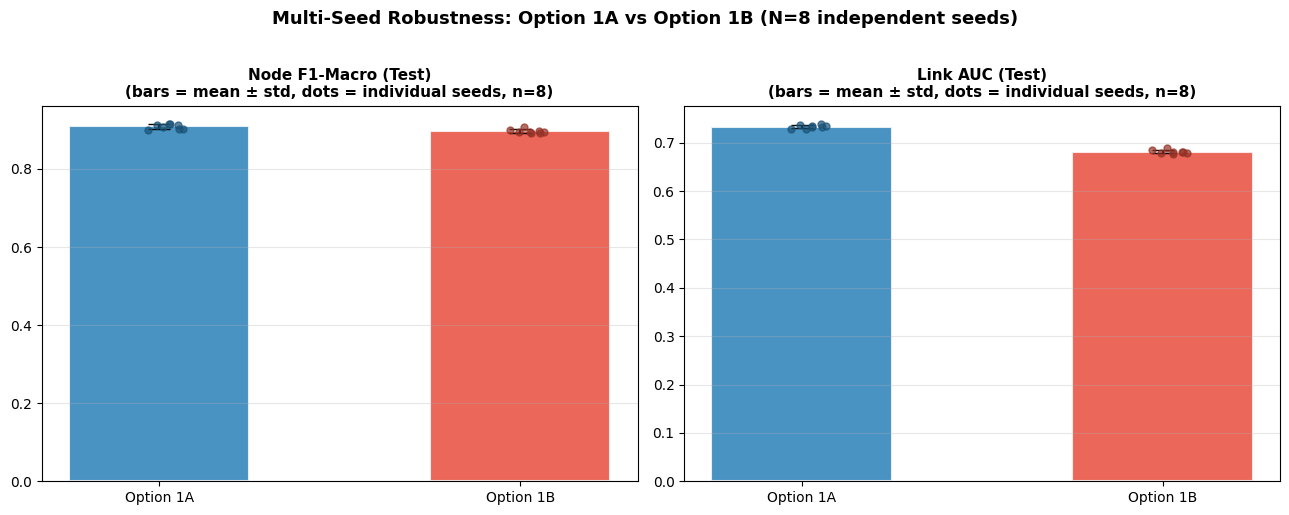

✓ Saved multiseed_robustness.png


In [22]:
# ── Multi-seed robustness sweep ───────────────────────────────────────────────
from scipy.stats import ttest_rel, wilcoxon

print("=" * 65)
print("EXPERIMENT E: MULTI-SEED ROBUSTNESS")
print("=" * 65)

N_SEEDS    = 2 if DRY_RUN else 8
SEEDS_LIST = [SEED] + [SEED + 1000 * i for i in range(1, N_SEEDS)]
METRICS    = ['node_f1_macro', 'node_f1_illicit', 'node_precision',
              'node_recall', 'node_auc', 'link_auc', 'link_ap']

print(f"Seeds: {SEEDS_LIST}")
print(f"(First seed matches the primary run above — used as a determinism sanity check)\n")

sweep_1a, sweep_1b = [], []

for i, sd in enumerate(SEEDS_LIST):
    t0 = datetime.now()

    torch.manual_seed(sd); np.random.seed(sd)
    m1a = DualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    o1a = torch.optim.Adam(m1a.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(sd)
    training_loop(m1a, train_1a, {'optimizer': o1a, 'alpha': ALPHA},
                  f"1A seed={sd}", data=data, verbose=False)
    sweep_1a.append(evaluate(m1a, data, 'test', device))

    torch.manual_seed(sd); np.random.seed(sd)
    m1b = ConstrainedDualTaskGNN(data.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    o1b = torch.optim.Adam(m1b.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(sd)
    training_loop(m1b, train_1b, {'optimizer': o1b, 'alpha': ALPHA, 'lam': LAMBDA},
                  f"1B seed={sd}", data=data, verbose=False)
    sweep_1b.append(evaluate(m1b, data, 'test', device, constrained=True))

    del m1a, m1b, o1a, o1b
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"[{i+1}/{N_SEEDS}] seed={sd} done in {(datetime.now()-t0).total_seconds():.1f}s "
          f"| 1A F1-macro {sweep_1a[-1]['node_f1_macro']:.4f} "
          f"| 1B F1-macro {sweep_1b[-1]['node_f1_macro']:.4f}")

# ── Sanity check: first seed should reproduce the primary run above exactly ──
# (If it doesn't, that's a real signal that determinism has broken somewhere —
# worth investigating rather than ignoring, given the GPU determinism work done earlier.)
first_seed_match = np.isclose(sweep_1a[0]['node_f1_macro'], test_1a['node_f1_macro'], atol=1e-4)
print(f"\nDeterminism sanity check (seed={SEED} reproduces primary run): {first_seed_match}")
if not first_seed_match:
    print(f"  \u26a0 Primary run F1-macro {test_1a['node_f1_macro']:.4f} vs sweep-seed-0 "
          f"{sweep_1a[0]['node_f1_macro']:.4f} \u2014 investigate before trusting these numbers.")

# ── Aggregate: mean ± std per metric ──────────────────────────────────────────
robustness_summary = {'option_1a': {}, 'option_1b': {}}
print(f"\n{'Metric':<18} {'1A mean±std':<20} {'1B mean±std':<20}")
print("-" * 58)
for m in METRICS:
    a_vals = np.array([r[m] for r in sweep_1a])
    b_vals = np.array([r[m] for r in sweep_1b])
    robustness_summary['option_1a'][m] = {'mean': float(a_vals.mean()), 'std': float(a_vals.std())}
    robustness_summary['option_1b'][m] = {'mean': float(b_vals.mean()), 'std': float(b_vals.std())}
    print(f"{m:<18} {a_vals.mean():.4f} ± {a_vals.std():.4f}      {b_vals.mean():.4f} ± {b_vals.std():.4f}")

# ── Paired significance tests across seeds (1A vs 1B, same seed = same split) ──
print(f"\nPaired tests across {N_SEEDS} seeds (1A vs 1B):")
for m in ['node_f1_macro', 'node_f1_illicit', 'link_auc']:
    a_vals = np.array([r[m] for r in sweep_1a])
    b_vals = np.array([r[m] for r in sweep_1b])
    t_stat, t_p = ttest_rel(b_vals, a_vals)
    try:
        w_stat, w_p = wilcoxon(b_vals, a_vals)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')  # all differences identical (zero variance)
    mean_diff = (b_vals - a_vals).mean()
    print(f"\n  {m}:")
    print(f"    Mean difference (1B - 1A) : {mean_diff:+.4f}")
    print(f"    Paired t-test             : t={t_stat:.3f}, p={t_p:.4f}")
    print(f"    Wilcoxon signed-rank      : W={w_stat:.3f}, p={w_p:.4f}")
    robustness_summary.setdefault('paired_tests', {})[m] = {
        'mean_diff_1b_minus_1a': float(mean_diff),
        'ttest_p': float(t_p), 'wilcoxon_p': float(w_p),
    }

print(f"\nNote: with N_SEEDS={N_SEEDS}, Wilcoxon's smallest achievable p-value is "
      f"{2 * (0.5 ** N_SEEDS):.4f} — if it prints exactly that, every seed agreed on\n"
      f"direction but the test still can't go below that floor. More seeds sharpen this further.")

# ── Visualisation: mean ± std bars with individual seed points overlaid ────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title in zip(axes, ['node_f1_macro', 'link_auc'],
                              ['Node F1-Macro (Test)', 'Link AUC (Test)']):
    a_vals = np.array([r[metric] for r in sweep_1a])
    b_vals = np.array([r[metric] for r in sweep_1b])
    ax.bar(['Option 1A', 'Option 1B'], [a_vals.mean(), b_vals.mean()],
           yerr=[a_vals.std(), b_vals.std()], capsize=8,
           color=['#2980b9', '#e74c3c'], edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
    jitter_a = np.random.RandomState(0).normal(0, 0.03, len(a_vals))
    jitter_b = np.random.RandomState(0).normal(0, 0.03, len(b_vals))
    ax.scatter(np.zeros(len(a_vals)) + jitter_a, a_vals, color='#1a5276', zorder=3, s=25, alpha=0.7)
    ax.scatter(np.ones(len(b_vals)) + jitter_b, b_vals, color='#943126', zorder=3, s=25, alpha=0.7)
    ax.set_title(f'{title}\n(bars = mean ± std, dots = individual seeds, n={N_SEEDS})',
                 fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
plt.suptitle(f'Multi-Seed Robustness: Option 1A vs Option 1B (N={N_SEEDS} independent seeds)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('multiseed_robustness.png', dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Saved multiseed_robustness.png")

## 16. Experiment F — Temporal Split Evaluation

Every result up to this point uses a **random** 70/15/15 node split and a random 60/20/20 edge split. For time-ordered financial transaction data, this is a real methodological weakness: a random split lets the model train on transactions from *later* in the dataset's timeline and be evaluated on transactions from *earlier*, which cannot happen in a real deployment and can make the model look better than it would in practice.

Weber et al. (2019), the paper that introduced Elliptic, used a 70:30 temporal split: train on time steps 1 to 34, test on time steps 35 to 49. A 2026 preprint re-examines GNN evaluation on Elliptic under temporal distribution shift (Maganti, 2026).

This experiment rebuilds the split to match Weber et al.'s test boundary (train: steps 1 to 29, validation: steps 30 to 34, test: steps 35 to 49, so that early stopping never touches the test period). The training message-passing graph is restricted to edges with both endpoints at step 29 or earlier. Because every Elliptic edge joins two nodes in the same time step, this restriction does not change the neighbourhood of any training node. Training negatives are drawn from the same time step as their positive edge. Evaluation of validation and test nodes aggregates over the full graph, as in Weber et al.'s transductive setup.

Both Option 1A and Option 1B are retrained from scratch on this split, using identical hyperparameters to the random-split run, so any difference in results is attributable to the split protocol alone — and the results are directly, correctly comparable to Weber et al.'s published numbers in Section 11.

In [23]:
print("=" * 65)
print("EXPERIMENT F: TEMPORAL SPLIT — BUILDING THE DATASET")
print("=" * 65)

# Weber et al. (2019) canonical boundary: train 1–34, test 35–49 (70:30 by time
# step). A validation slice is carved from the tail of their training period so
# early stopping never touches the test period, while the train/test boundary
# stays identical to the published benchmark.
TRAIN_MAX_STEP = 29
VAL_MAX_STEP   = 34   # test = time_step > 34, i.e. steps 35-49 (matches Weber et al. exactly)

# Pulled from data.y (set once in Preprocessing and never reassigned) rather than
# the bare global `labels` name -- a plotting cell earlier in this notebook
# reuses `labels` as a local variable for a legend, which shadows the global.
# Reading from data.y sidesteps that class of bug entirely.
node_labels_np = data.y.cpu().numpy()

unique_steps = np.unique(time_steps)
print(f"Time steps present: {unique_steps.min()}–{unique_steps.max()} ({len(unique_steps)} unique steps)")

train_mask_t = torch.tensor((time_steps <= TRAIN_MAX_STEP) & (node_labels_np != -1))
val_mask_t   = torch.tensor((time_steps > TRAIN_MAX_STEP) & (time_steps <= VAL_MAX_STEP) & (node_labels_np != -1))
test_mask_t  = torch.tensor((time_steps > VAL_MAX_STEP) & (node_labels_np != -1))

print(f"\nTemporal node splits:")
print(f"  Train (steps 1–{TRAIN_MAX_STEP})   : {train_mask_t.sum():,} labeled nodes "
      f"(Illicit: {(node_labels_np[train_mask_t.numpy()]==1).sum():,}, Licit: {(node_labels_np[train_mask_t.numpy()]==0).sum():,})")
print(f"  Val   (steps {TRAIN_MAX_STEP+1}–{VAL_MAX_STEP})  : {val_mask_t.sum():,} labeled nodes "
      f"(Illicit: {(node_labels_np[val_mask_t.numpy()]==1).sum():,}, Licit: {(node_labels_np[val_mask_t.numpy()]==0).sum():,})")
print(f"  Test  (steps {VAL_MAX_STEP+1}–49)  : {test_mask_t.sum():,} labeled nodes "
      f"(Illicit: {(node_labels_np[test_mask_t.numpy()]==1).sum():,}, Licit: {(node_labels_np[test_mask_t.numpy()]==0).sum():,})")

if train_mask_t.sum() == 0 or val_mask_t.sum() == 0 or test_mask_t.sum() == 0:
    raise RuntimeError("One or more temporal partitions is empty — check time_steps / MAX_NODES before proceeding.")

# ── Edge splits by time: an edge's time = the LATER of its two endpoints ──
src_np, dst_np = edge_index[0].numpy(), edge_index[1].numpy()
edge_time = np.maximum(time_steps[src_np], time_steps[dst_np])

train_pos_t = edge_index[:, edge_time <= TRAIN_MAX_STEP]
val_pos_t   = edge_index[:, (edge_time > TRAIN_MAX_STEP) & (edge_time <= VAL_MAX_STEP)]
test_pos_t  = edge_index[:, edge_time > VAL_MAX_STEP]

print(f"\nTemporal edge splits:")
print(f"  Train : {train_pos_t.shape[1]:,} edges")
print(f"  Val   : {val_pos_t.shape[1]:,} edges")
print(f"  Test  : {test_pos_t.shape[1]:,} edges")

# Negative sampling against the FULL edge set (same convention as the random-split
# pipeline), reseeded deterministically before each call.
train_neg_t = same_step_negatives(train_pos_t, SEED + 101)
val_neg_t   = same_step_negatives(val_pos_t,   SEED + 102)
test_neg_t  = same_step_negatives(test_pos_t,  SEED + 103)
torch.manual_seed(SEED)  # restore global seed

train_eil_t = torch.cat([train_pos_t, train_neg_t], dim=1)
train_el_t  = torch.cat([torch.ones(train_pos_t.shape[1]), torch.zeros(train_neg_t.shape[1])])
val_eil_t   = torch.cat([val_pos_t, val_neg_t], dim=1)
val_el_t    = torch.cat([torch.ones(val_pos_t.shape[1]), torch.zeros(val_neg_t.shape[1])])
test_eil_t  = torch.cat([test_pos_t, test_neg_t], dim=1)
test_el_t   = torch.cat([torch.ones(test_pos_t.shape[1]), torch.zeros(test_neg_t.shape[1])])

# ── Training-time message-passing graph: training-period edges ONLY ──
# (both endpoints at time_step <= TRAIN_MAX_STEP). This is what prevents future
# structure from leaking into node embeddings during training -- evaluation
# (val/test) uses the full graph via full_edge_index, matching evaluate()'s
# existing convention everywhere else in this notebook.
train_msg_mask = (time_steps[src_np] <= TRAIN_MAX_STEP) & (time_steps[dst_np] <= TRAIN_MAX_STEP)
train_msg_edge_index = edge_index[:, train_msg_mask]
print(f"\nTraining-time message-passing graph: {train_msg_edge_index.shape[1]:,} edges "
      f"(vs {edge_index.shape[1]:,} in the full graph used at evaluation time)")

# Class weights from the temporal training partition only
train_idx_t = np.where(train_mask_t.numpy())[0]
licit_n_t   = int((node_labels_np[train_idx_t] == 0).sum())
illicit_n_t = int((node_labels_np[train_idx_t] == 1).sum())
total_n_t   = licit_n_t + illicit_n_t
class_weights_t = torch.tensor([total_n_t/(2*licit_n_t), total_n_t/(2*illicit_n_t)], dtype=torch.float)
print(f"\nClass weights (temporal train partition: {licit_n_t:,} licit / {illicit_n_t:,} illicit): "
      f"Licit={class_weights_t[0]:.4f}  Illicit={class_weights_t[1]:.4f}")

# Feature normalisation for the temporal protocol: statistics from the labelled
# training-period nodes only (steps 1-29).
_mu_t = raw_features[train_idx_t].mean(axis=0)
_sd_t = raw_features[train_idx_t].std(axis=0) + 1e-8
x_temporal = torch.tensor((raw_features - _mu_t) / _sd_t, dtype=torch.float)

data_temporal = Data(
    x=x_temporal,  # temporal-train-only scaling, same node ordering as data.x
    edge_index=train_msg_edge_index,
    y=data.y,  # reuse the existing tensor directly rather than rebuilding from `labels`
    train_mask=train_mask_t, val_mask=val_mask_t, test_mask=test_mask_t,
    train_edge_label_index=train_eil_t, train_edge_label=train_el_t,
    val_edge_label_index=val_eil_t,     val_edge_label=val_el_t,
    test_edge_label_index=test_eil_t,   test_edge_label=test_el_t,
    full_edge_index=edge_index,  # full graph — used by evaluate() for val/test, same as `data`
)
data_temporal.class_weights = class_weights_t
data_temporal.val_msg_edge_index  = train_pos_t
data_temporal.test_msg_edge_index = torch.cat([train_pos_t, val_pos_t], 1)
print(f"\n\u2713 data_temporal ready  Nodes: {data_temporal.x.shape[0]:,}  Features: {data_temporal.x.shape[1]}")

EXPERIMENT F: TEMPORAL SPLIT — BUILDING THE DATASET
Time steps present: 1–49 (49 unique steps)

Temporal node splits:
  Train (steps 1–29)   : 26,381 labeled nodes (Illicit: 2,871, Licit: 23,510)
  Val   (steps 30–34)  : 3,513 labeled nodes (Illicit: 591, Licit: 2,922)
  Test  (steps 35–49)  : 16,670 labeled nodes (Illicit: 1,083, Licit: 15,587)

Temporal edge splits:
  Train : 140,223 edges
  Val   : 16,620 edges
  Test  : 77,512 edges

Training-time message-passing graph: 140,223 edges (vs 234,355 in the full graph used at evaluation time)

Class weights (temporal train partition: 23,510 licit / 2,871 illicit): Licit=0.5611  Illicit=4.5944

✓ data_temporal ready  Nodes: 203,769  Features: 165


In [24]:
print("=" * 65)
print("EXPERIMENT F: TEMPORAL SPLIT — TRAINING")
print("=" * 65)

print("\nTraining Option 1A on the temporal split...")
torch.manual_seed(SEED); np.random.seed(SEED)
model_1a_temporal = DualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
opt_1a_temporal   = torch.optim.Adam(model_1a_temporal.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
torch.manual_seed(SEED)
history_1a_temporal = training_loop(model_1a_temporal, train_1a, {'optimizer': opt_1a_temporal, 'alpha': ALPHA},
                                     "Option 1A (temporal)", data=data_temporal, verbose=False)
test_1a_temporal = evaluate(model_1a_temporal, data_temporal, 'test', device)

print("\nTraining Option 1B on the temporal split...")
torch.manual_seed(SEED); np.random.seed(SEED)
model_1b_temporal = ConstrainedDualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
opt_1b_temporal   = torch.optim.Adam(model_1b_temporal.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
torch.manual_seed(SEED)
history_1b_temporal = training_loop(model_1b_temporal, train_1b, {'optimizer': opt_1b_temporal, 'alpha': ALPHA, 'lam': LAMBDA},
                                     "Option 1B (temporal)", data=data_temporal, verbose=False)
test_1b_temporal = evaluate(model_1b_temporal, data_temporal, 'test', device, constrained=True)

print("\n" + "=" * 65)
print("TEMPORAL SPLIT — TEST RESULTS")
print("=" * 65)
print(f"\nOption 1A | F1-macro {test_1a_temporal['node_f1_macro']:.4f} | F1-illicit {test_1a_temporal['node_f1_illicit']:.4f} "
      f"| Precision {test_1a_temporal['node_precision']:.4f} | Recall {test_1a_temporal['node_recall']:.4f} | Link AUC {test_1a_temporal['link_auc']:.4f}")
print(f"Option 1B | F1-macro {test_1b_temporal['node_f1_macro']:.4f} | F1-illicit {test_1b_temporal['node_f1_illicit']:.4f} "
      f"| Precision {test_1b_temporal['node_precision']:.4f} | Recall {test_1b_temporal['node_recall']:.4f} | Link AUC {test_1b_temporal['link_auc']:.4f}")

print(f"\nFor comparison, the random-split results reported earlier in this notebook:")
print(f"Option 1A (random) | F1-macro {test_1a['node_f1_macro']:.4f} | F1-illicit {test_1a['node_f1_illicit']:.4f} | Link AUC {test_1a['link_auc']:.4f}")
print(f"Option 1B (random) | F1-macro {test_1b['node_f1_macro']:.4f} | F1-illicit {test_1b['node_f1_illicit']:.4f} | Link AUC {test_1b['link_auc']:.4f}")
print(f"\nA drop from random to temporal is expected and is the correct, honest result —")
print(f"it reflects genuine task difficulty under distribution shift, not a bug.")

EXPERIMENT F: TEMPORAL SPLIT — TRAINING

Training Option 1A on the temporal split...

✓ Option 1A (temporal) | 35.4s | Best val: 0.7961

Training Option 1B on the temporal split...

✓ Option 1B (temporal) | 34.6s | Best val: 0.7619

TEMPORAL SPLIT — TEST RESULTS

Option 1A | F1-macro 0.7015 | F1-illicit 0.4608 | Precision 0.3467 | Recall 0.6870 | Link AUC 0.7039
Option 1B | F1-macro 0.7700 | F1-illicit 0.5751 | Precision 0.5010 | Recall 0.6750 | Link AUC 0.6282

For comparison, the random-split results reported earlier in this notebook:
Option 1A (random) | F1-macro 0.9128 | F1-illicit 0.8432 | Link AUC 0.7393
Option 1B (random) | F1-macro 0.8968 | F1-illicit 0.8161 | Link AUC 0.6813

A drop from random to temporal is expected and is the correct, honest result —
it reflects genuine task difficulty under distribution shift, not a bug.


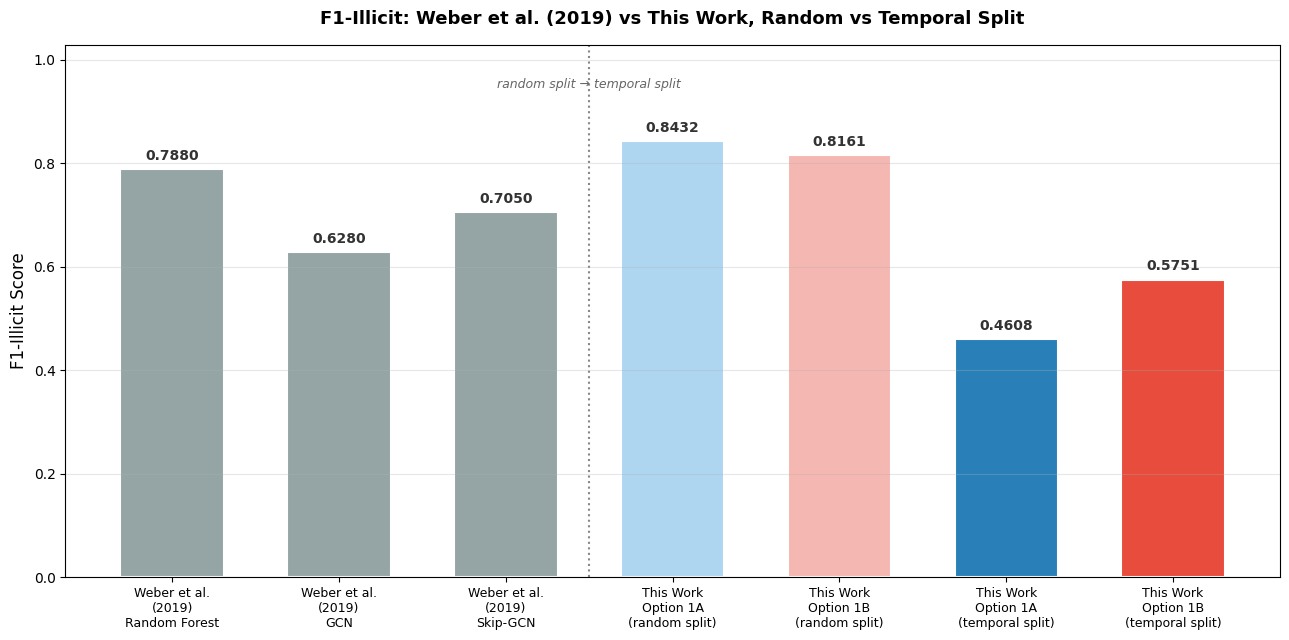

✓ Saved temporal_vs_random_comparison.png

✓ temporal_split_results dict ready for export


In [25]:
# ── Comparison chart: Random split vs Temporal split vs Weber et al. (2019) ──
# This closes the loop on the caveat flagged in Section 11 (Baseline Comparison):
# the temporal-split numbers below are now directly, correctly comparable to
# Weber et al.'s published figures -- same dataset, same metric, same protocol.

weber_labels = ["Weber et al.\n(2019)\nRandom Forest", "Weber et al.\n(2019)\nGCN", "Weber et al.\n(2019)\nSkip-GCN"]
weber_f1     = [0.788, 0.628, 0.705]

this_work_labels = ["This Work\nOption 1A\n(random split)", "This Work\nOption 1B\n(random split)",
                     "This Work\nOption 1A\n(temporal split)", "This Work\nOption 1B\n(temporal split)"]
this_work_f1 = [round(test_1a['node_f1_illicit'], 4), round(test_1b['node_f1_illicit'], 4),
                round(test_1a_temporal['node_f1_illicit'], 4), round(test_1b_temporal['node_f1_illicit'], 4)]

all_labels = weber_labels + this_work_labels
all_f1     = weber_f1 + this_work_f1
colours    = ['#95a5a6']*3 + ['#aed6f1', '#f5b7b1', '#2980b9', '#e74c3c']

fig, ax = plt.subplots(figsize=(13, 6.5))
bars = ax.bar(all_labels, all_f1, color=colours, edgecolor='white', linewidth=1.5, width=0.62)
for b, v, c in zip(bars, all_f1, colours):
    ax.text(b.get_x() + b.get_width()/2, v + 0.012, f'{v:.4f}', ha='center', va='bottom',
            fontweight='bold', fontsize=10, color='#333333')

ax.axvline(x=2.5, color='#888888', linestyle=':', linewidth=1.5)
ax.text(2.5, max(all_f1)*1.12, 'random split \u2192 temporal split', ha='center', fontsize=9,
        color='#666666', style='italic')

ax.set_ylim(0, max(all_f1) * 1.22)
ax.set_ylabel('F1-Illicit Score', fontsize=12)
ax.set_title('F1-Illicit: Weber et al. (2019) vs This Work, Random vs Temporal Split',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.savefig('temporal_vs_random_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Saved temporal_vs_random_comparison.png")

# ── Package for export ──────────────────────────────────────────────────────
temporal_split_results = {
    'split_boundary': {'train_steps': f'1-{TRAIN_MAX_STEP}', 'val_steps': f'{TRAIN_MAX_STEP+1}-{VAL_MAX_STEP}',
                        'test_steps': f'{VAL_MAX_STEP+1}-49', 'matches_weber_et_al_2019_boundary': True},
    'node_counts': {'train': int(train_mask_t.sum()), 'val': int(val_mask_t.sum()), 'test': int(test_mask_t.sum())},
    'edge_counts': {'train': int(train_pos_t.shape[1]), 'val': int(val_pos_t.shape[1]), 'test': int(test_pos_t.shape[1])},
    'option_1a_test': {k: round(v, 4) for k, v in test_1a_temporal.items()},
    'option_1b_test': {k: round(v, 4) for k, v in test_1b_temporal.items()},
    'comparison_to_random_split': {
        'option_1a_f1_illicit_drop': round(test_1a['node_f1_illicit'] - test_1a_temporal['node_f1_illicit'], 4),
        'option_1b_f1_illicit_drop': round(test_1b['node_f1_illicit'] - test_1b_temporal['node_f1_illicit'], 4),
    },
    'comparison_to_weber_et_al_2019': {
        'weber_rf_f1_illicit': 0.788, 'weber_gcn_f1_illicit': 0.628, 'weber_skipgcn_f1_illicit': 0.705,
        'this_work_1a_f1_illicit': round(test_1a_temporal['node_f1_illicit'], 4),
        'this_work_1b_f1_illicit': round(test_1b_temporal['node_f1_illicit'], 4),
    },
}
print("\n\u2713 temporal_split_results dict ready for export")

## 17. Dataset Structure and Distribution Shift

Two claims need evidence: that no future information can reach training through message passing, and that a random split hides a shift that a temporal split exposes. The first is tested by counting edges between time steps, the second by asking whether a classifier can tell the training period from the test period using the features alone.

In [26]:
# ── Shared helpers for the figures and tables below ──
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from scipy.stats import ttest_rel, wilcoxon, spearmanr, t as t_dist

os.makedirs('tables', exist_ok=True)
PALETTE = {'Node-only': '#7f7f7f', '1A': '#1f77b4', '1B': '#d62728', '1C': '#9467bd',
           'Random forest': '#2ca02c', 'Gradient boosting': '#17becf', 'Logistic regression': '#bcbd22'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10, 'axes.titleweight': 'bold'})
_N_SEEDS = 2 if DRY_RUN else 8
SEEDS_LIST   = globals().get('SEEDS_LIST',   [SEED + 1000 * i for i in range(_N_SEEDS)])
SEEDS_LIST_H = globals().get('SEEDS_LIST_H', [SEED + 1000 * i for i in range(_N_SEEDS)])

col = lambda runs, k: [r[k] for r in runs]
ms  = lambda v: f"{np.mean(v):.4f} ± {np.std(v):.4f}"

def save_fig(name):
    plt.tight_layout(); plt.savefig(name, bbox_inches='tight'); plt.show(); print('\u2713 saved', name)

def save_table(df, name):
    df.to_csv(f'tables/{name}.csv', index=False)
    print(f"\n{name}"); print(df.to_string(index=False)); print(f"\u2713 saved tables/{name}.csv")



DATASET STRUCTURE AND DISTRIBUTION SHIFT
Edges with both endpoints in the same time step: 100.0000% of 234,355
Edges that cross time steps: 0

per_step_label_counts
 step  nodes  labelled  illicit  illicit_rate_of_labelled
    1   7880      2147       17                    0.0079
    2   4544      1117       18                    0.0161
    3   6621      1279       11                    0.0086
    4   5693      1440       30                    0.0208
    5   6803      1882        8                    0.0043
    6   4328       485        5                    0.0103
    7   6048      1203      102                    0.0848
    8   4457      1165       67                    0.0575
    9   4996       778      248                    0.3188
   10   6727       972       18                    0.0185
   11   4296       696      131                    0.1882
   12   2047       506       16                    0.0316
   13   4528       809      291                    0.3597
   14   2022       417 

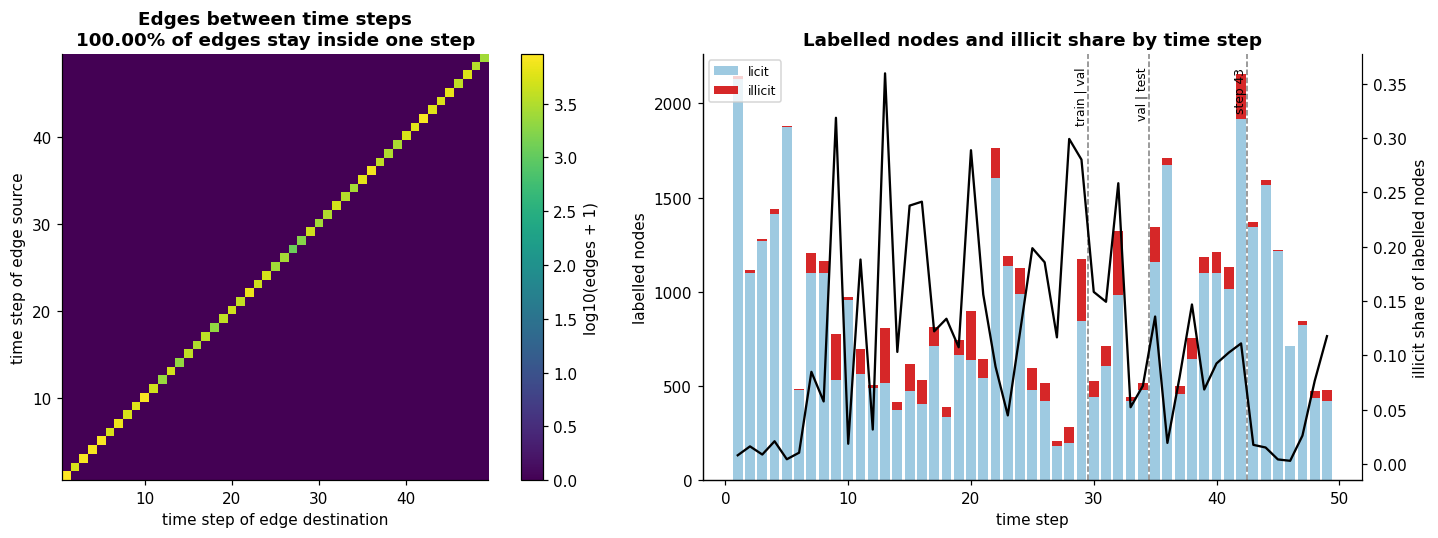

✓ saved fig_dataset_structure.png

Domain classifier AUC (0.5 = indistinguishable):
  training period (steps 1-29) vs test period (steps 35-49): 1.0000
  random split of the same nodes (control)                  : 0.4990


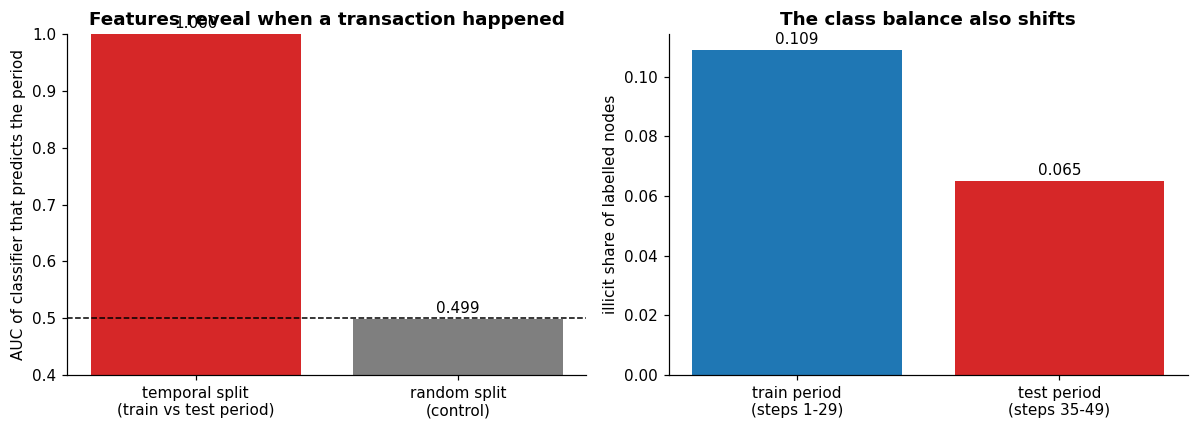

✓ saved fig_distribution_shift.png


In [27]:
# ═══════════════════════════════════════════════════════════════════════════
# DATASET STRUCTURE AND DISTRIBUTION SHIFT: the evidence behind two claims
#   (1) no future information can reach training through message passing
#   (2) a random split hides a distribution shift that a temporal split exposes
# ═══════════════════════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

print("=" * 70)
print("DATASET STRUCTURE AND DISTRIBUTION SHIFT")
print("=" * 70)
s_np, d_np = edge_index[0].numpy(), edge_index[1].numpy()
steps = np.unique(time_steps); S = len(steps)
step_idx = np.searchsorted(steps, time_steps)
M = np.zeros((S, S), dtype=np.int64)
np.add.at(M, (step_idx[s_np], step_idx[d_np]), 1)
share_within = float(np.trace(M) / M.sum())
print(f"Edges with both endpoints in the same time step: {share_within:.4%} of {int(M.sum()):,}")
print(f"Edges that cross time steps: {int(M.sum() - np.trace(M)):,}")

y_np = data.y.cpu().numpy()
per_step = pd.DataFrame({
    'step': steps,
    'nodes': [int((time_steps == s).sum()) for s in steps],
    'labelled': [int(((time_steps == s) & (y_np != -1)).sum()) for s in steps],
    'illicit': [int(((time_steps == s) & (y_np == 1)).sum()) for s in steps]})
per_step['illicit_rate_of_labelled'] = np.where(per_step.labelled > 0, per_step.illicit / per_step.labelled.clip(lower=1), np.nan)
save_table(per_step.round(4), 'per_step_label_counts')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
im = ax[0].imshow(np.log10(M + 1), cmap='viridis', origin='lower', extent=[steps[0] - .5, steps[-1] + .5, steps[0] - .5, steps[-1] + .5])
ax[0].set_xlabel('time step of edge destination'); ax[0].set_ylabel('time step of edge source')
ax[0].set_title(f'Edges between time steps\n{share_within:.2%} of edges stay inside one step')
plt.colorbar(im, ax=ax[0], label='log10(edges + 1)')
ax[1].bar(per_step.step, per_step.labelled - per_step.illicit, color='#9ecae1', label='licit')
ax[1].bar(per_step.step, per_step.illicit, bottom=per_step.labelled - per_step.illicit, color='#d62728', label='illicit')
ax[1].set_xlabel('time step'); ax[1].set_ylabel('labelled nodes')
ax2 = ax[1].twinx(); ax2.plot(per_step.step, per_step.illicit_rate_of_labelled, color='black', lw=1.5, label='illicit share')
ax2.set_ylabel('illicit share of labelled nodes'); ax2.spines['right'].set_visible(True)
for x_, lab in ((29.5, 'train | val'), (34.5, 'val | test'), (42.5, 'step 43')):
    ax[1].axvline(x_, color='grey', ls='--', lw=1); ax[1].text(x_, ax[1].get_ylim()[1] * 0.97, lab, rotation=90, va='top', ha='right', fontsize=8)
ax[1].set_title('Labelled nodes and illicit share by time step'); ax[1].legend(loc='upper left', fontsize=8)
save_fig('fig_dataset_structure.png')

# ── Distribution shift: can a classifier tell WHEN a transaction happened, from its features alone? ──
def domain_auc(idx_a, idx_b, n_max=10000, seed=0):
    rng = np.random.RandomState(seed)
    a = rng.choice(idx_a, min(len(idx_a), n_max), replace=False)
    b = rng.choice(idx_b, min(len(idx_b), n_max), replace=False)
    X = raw_features[np.concatenate([a, b])]; yy = np.r_[np.zeros(len(a)), np.ones(len(b))]
    clf = RandomForestClassifier(n_estimators=100 if not DRY_RUN else 30, n_jobs=-1, random_state=seed)
    p = cross_val_predict(clf, X, yy, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba')[:, 1]
    return float(roc_auc_score(yy, p))

train_period = np.where(time_steps <= 29)[0]; test_period = np.where(time_steps >= 35)[0]
rng = np.random.RandomState(1)
pool = np.concatenate([train_period, test_period]); rng.shuffle(pool)
rand_a, rand_b = pool[:len(train_period)], pool[len(train_period):]
shift_results = {'temporal_train_vs_test_auc': domain_auc(train_period, test_period),
                 'random_split_control_auc':   domain_auc(rand_a, rand_b)}
print(f"\nDomain classifier AUC (0.5 = indistinguishable):")
print(f"  training period (steps 1-29) vs test period (steps 35-49): {shift_results['temporal_train_vs_test_auc']:.4f}")
print(f"  random split of the same nodes (control)                  : {shift_results['random_split_control_auc']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(['temporal split\n(train vs test period)', 'random split\n(control)'],
          [shift_results['temporal_train_vs_test_auc'], shift_results['random_split_control_auc']], color=['#d62728', '#7f7f7f'])
ax[0].axhline(0.5, color='black', ls='--', lw=1); ax[0].set_ylim(0.4, 1.0)
ax[0].set_ylabel('AUC of classifier that predicts the period'); ax[0].set_title('Features reveal when a transaction happened')
for i, v in enumerate([shift_results['temporal_train_vs_test_auc'], shift_results['random_split_control_auc']]):
    ax[0].text(i, v + 0.01, f'{v:.3f}', ha='center')
tr_rate = per_step[per_step.step <= 29].illicit.sum() / per_step[per_step.step <= 29].labelled.sum()
te_rate = per_step[per_step.step >= 35].illicit.sum() / per_step[per_step.step >= 35].labelled.sum()
ax[1].bar(['train period\n(steps 1-29)', 'test period\n(steps 35-49)'], [tr_rate, te_rate], color=['#1f77b4', '#d62728'])
ax[1].set_ylabel('illicit share of labelled nodes'); ax[1].set_title('The class balance also shifts')
for i, v in enumerate([tr_rate, te_rate]): ax[1].text(i, v + 0.002, f'{v:.3f}', ha='center')
save_fig('fig_distribution_shift.png')
shift_results.update({'illicit_share_train_period': float(tr_rate), 'illicit_share_test_period': float(te_rate),
                      'share_edges_within_step': share_within})


## 18. Design Figures: Model and Evaluation Protocols

The dual-task model with the fraud-label constraint, and the random and temporal evaluation protocols.

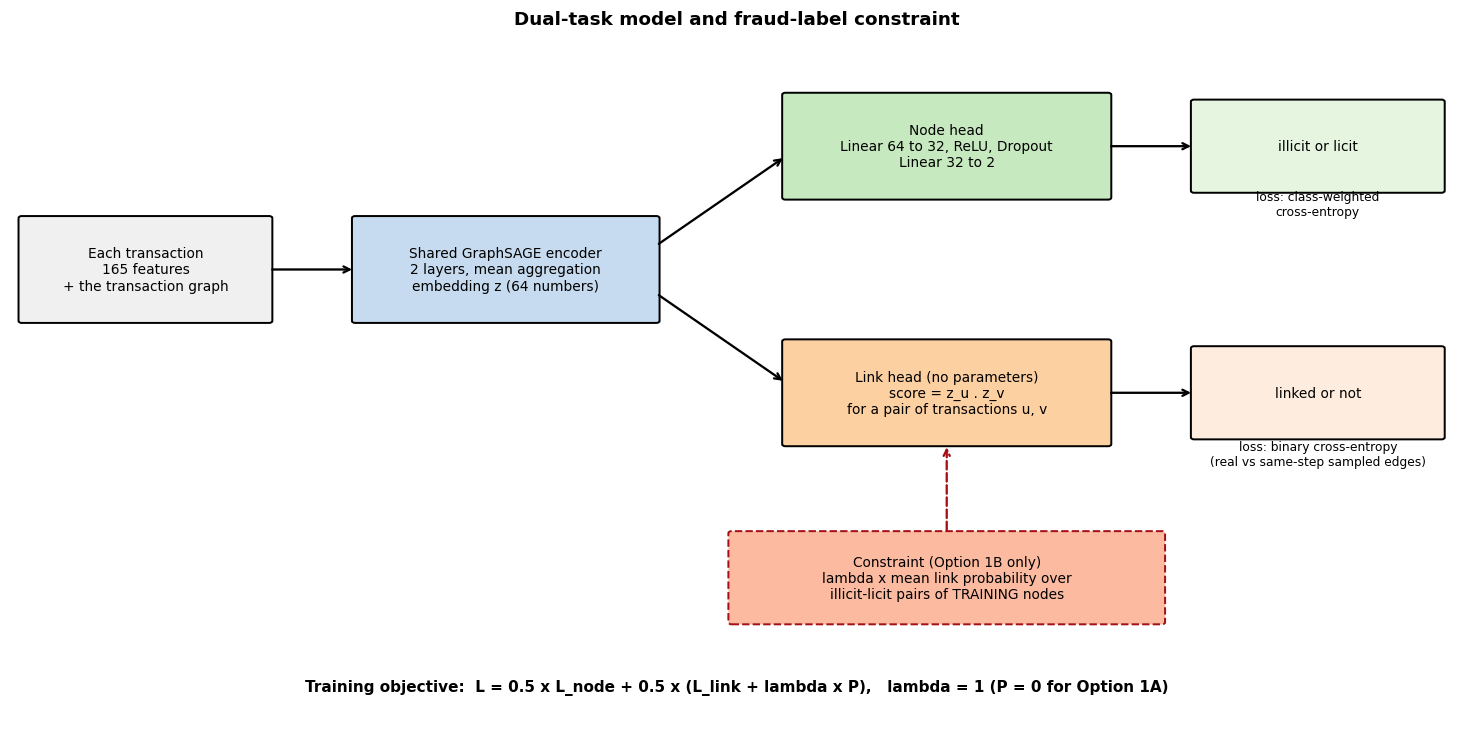

✓ saved fig_architecture.png


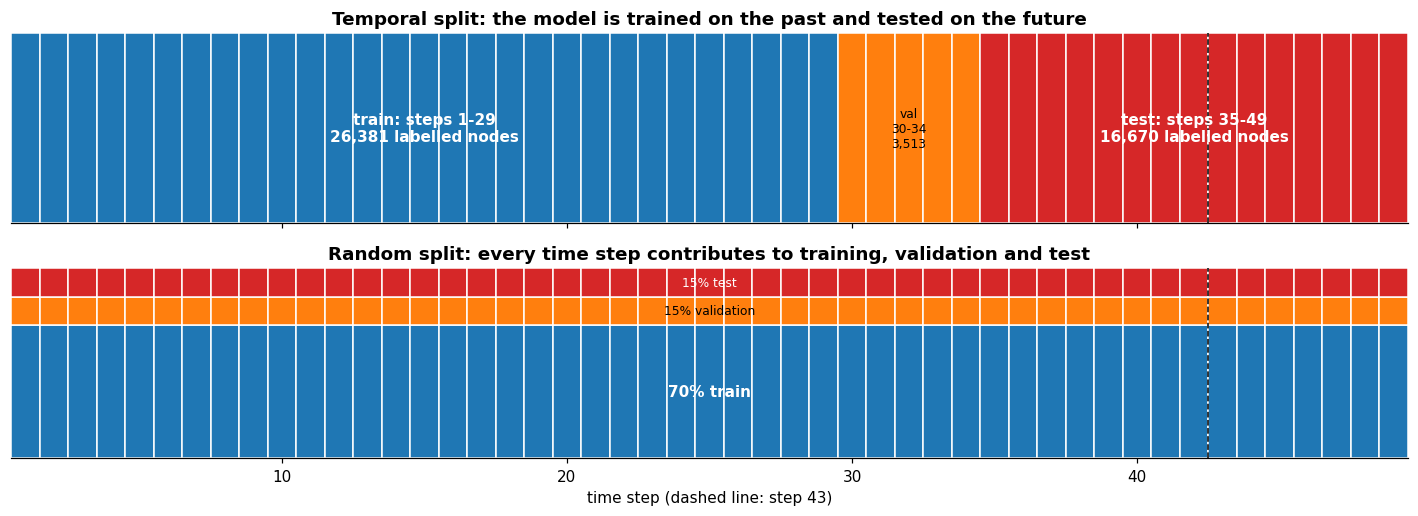

✓ saved fig_evaluation_protocols.png


In [28]:
# ═══════════════════════════════════════════════════════════════════════════
# DESIGN FIGURES: the model and the evaluation protocols
# ═══════════════════════════════════════════════════════════════════════════
import matplotlib.patches as mp
def _box(ax, x, y, w, h, text, fc, ec='black', ls='-', fs=9):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03', fc=fc, ec=ec, lw=1.3, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs)
def _arrow(ax, p, q, color='black', ls='-'):
    ax.annotate('', xy=q, xytext=p, arrowprops=dict(arrowstyle='->', lw=1.5, color=color, ls=ls))

fig, ax = plt.subplots(figsize=(13.5, 6.8)); ax.set_xlim(0, 13.5); ax.set_ylim(-3.1, 7); ax.axis('off')
_box(ax, 0.1, 2.8, 2.3, 1.5, "Each transaction\n165 features\n+ the transaction graph", '#f0f0f0')
_box(ax, 3.2, 2.8, 2.8, 1.5, "Shared GraphSAGE encoder\n2 layers, mean aggregation\nembedding z (64 numbers)", '#c6dbef')
_box(ax, 7.2, 4.6, 3.0, 1.5, "Node head\nLinear 64 to 32, ReLU, Dropout\nLinear 32 to 2", '#c7e9c0')
_box(ax, 11.0, 4.7, 2.3, 1.3, "illicit or licit", '#e5f5e0')
_box(ax, 7.2, 1.0, 3.0, 1.5, "Link head (no parameters)\nscore = z_u . z_v\nfor a pair of transactions u, v", '#fdd0a2')
_box(ax, 11.0, 1.1, 2.3, 1.3, "linked or not", '#feedde')
_box(ax, 6.7, -1.6, 4.0, 1.3, "Constraint (Option 1B only)\nlambda x mean link probability over\nillicit-licit pairs of TRAINING nodes", '#fcbba1', ec='#a50f15', ls='--')
_arrow(ax, (2.4, 3.55), (3.2, 3.55)); _arrow(ax, (6.0, 3.9), (7.2, 5.2)); _arrow(ax, (6.0, 3.2), (7.2, 1.9))
_arrow(ax, (10.2, 5.35), (11.0, 5.35)); _arrow(ax, (10.2, 1.75), (11.0, 1.75)); _arrow(ax, (8.7, -0.3), (8.7, 1.0), color='#a50f15', ls='--')
ax.text(12.15, 4.35, "loss: class-weighted\ncross-entropy", ha='center', fontsize=8); ax.text(12.15, 0.7, "loss: binary cross-entropy\n(real vs same-step sampled edges)", ha='center', fontsize=8)
ax.text(6.75, -2.6, f"Training objective:  L = {ALPHA:g} x L_node + {1 - ALPHA:g} x (L_link + lambda x P),   lambda = {LAMBDA:g} (P = 0 for Option 1A)", fontsize=10, fontweight='bold', ha='center')
ax.set_title("Dual-task model and fraud-label constraint")
save_fig('fig_architecture.png')

# ── Evaluation protocols ──
fig, ax = plt.subplots(2, 1, figsize=(13, 4.8), sharex=True)
steps_ = np.arange(1, 50)
cols = ['#1f77b4', '#ff7f0e', '#d62728']
for s in steps_:
    c = cols[0] if s <= 29 else (cols[1] if s <= 34 else cols[2])
    ax[0].add_patch(mp.Rectangle((s - 0.5, 0), 1, 1, fc=c, ec='white'))
    for frac_lo, frac_hi, cc in ((0, 0.70, cols[0]), (0.70, 0.85, cols[1]), (0.85, 1.0, cols[2])):
        ax[1].add_patch(mp.Rectangle((s - 0.5, frac_lo), 1, frac_hi - frac_lo, fc=cc, ec='white'))
for a_ in ax:
    a_.set_xlim(0.5, 49.5); a_.set_ylim(0, 1); a_.set_yticks([]); a_.axvline(42.5, color='black', ls='--', lw=1)
    a_.spines['left'].set_visible(False)
ax[0].set_title('Temporal split: the model is trained on the past and tested on the future')
ax[1].set_title('Random split: every time step contributes to training, validation and test')
n_tr, n_va, n_te = int(data_temporal.train_mask.sum()), int(data_temporal.val_mask.sum()), int(data_temporal.test_mask.sum())
ax[0].text(15, 0.5, f'train: steps 1-29\n{n_tr:,} labelled nodes', ha='center', va='center', color='white', fontweight='bold')
ax[0].text(32, 0.5, f'val\n30-34\n{n_va:,}', ha='center', va='center', color='black', fontsize=8)
ax[0].text(42, 0.5, f'test: steps 35-49\n{n_te:,} labelled nodes', ha='center', va='center', color='white', fontweight='bold')
ax[1].text(25, 0.35, '70% train', ha='center', va='center', color='white', fontweight='bold'); ax[1].text(25, 0.775, '15% validation', ha='center', va='center', fontsize=8)
ax[1].text(25, 0.925, '15% test', ha='center', va='center', color='white', fontsize=8)
ax[1].set_xlabel('time step (dashed line: step 43)')
save_fig('fig_evaluation_protocols.png')


## 19. Experiment G — Transductive Leakage Ablation

The temporal split above restricts the training-time message-passing graph to training-period edges. Weber et al. (2019) message-pass over the full graph during training. This experiment relaxes the restriction and rebuilds the same split with the full graph available during training, changing only that one variable. Because every Elliptic edge joins two nodes in the same time step, the two conditions are expected to train identically.

This experiment isolates the answer directly. It rebuilds the temporal split with **identical** train/val/test node and edge partitions, changing exactly one thing: the training-time message-passing graph is relaxed back to the **full graph** (matching Weber et al.'s own transductive convention). Everything else — hyperparameters, seed, architecture, labels — is unchanged. Any difference in test performance between this run and Section 16 is attributable to that one variable: whether future-period structure was visible to the encoder during training.

In [29]:
print("=" * 65)
print("EXPERIMENT G: TRANSDUCTIVE LEAKAGE ABLATION — BUILDING THE DATASET")
print("=" * 65)

# Identical splits to data_temporal (Section 16) -- reusing the same masks and
# edge-label tensors already built there. The ONLY change: edge_index (used for
# message passing during TRAINING) is the full graph, not the training-period-only
# subgraph. This matches Weber et al.'s (2019) own transductive GCN setup exactly.
data_temporal_transductive = Data(
    x=x_temporal,
    edge_index=edge_index,  # full graph, including val/test-period edges -- the one change
    y=data.y,
    train_mask=train_mask_t, val_mask=val_mask_t, test_mask=test_mask_t,
    train_edge_label_index=train_eil_t, train_edge_label=train_el_t,
    val_edge_label_index=val_eil_t,     val_edge_label=val_el_t,
    test_edge_label_index=test_eil_t,   test_edge_label=test_el_t,
    full_edge_index=edge_index,
)
data_temporal_transductive.class_weights = class_weights_t
data_temporal_transductive.val_msg_edge_index  = data_temporal.val_msg_edge_index
data_temporal_transductive.test_msg_edge_index = data_temporal.test_msg_edge_index

print(f"Training-time message-passing graph: {edge_index.shape[1]:,} edges "
      f"(full graph, vs {train_msg_edge_index.shape[1]:,} in the strict/inductive version)")
print(f"Node/edge splits: identical to Section 16 (train {int(train_mask_t.sum()):,} / "
      f"val {int(val_mask_t.sum()):,} / test {int(test_mask_t.sum()):,} labeled nodes)")
print(f"\n\u2713 data_temporal_transductive ready")

EXPERIMENT G: TRANSDUCTIVE LEAKAGE ABLATION — BUILDING THE DATASET
Training-time message-passing graph: 234,355 edges (full graph, vs 140,223 in the strict/inductive version)
Node/edge splits: identical to Section 16 (train 26,381 / val 3,513 / test 16,670 labeled nodes)

✓ data_temporal_transductive ready


## 20. Experiment H — Multi-Seed Leakage Ablation

This section repeats the strict versus transductive comparison of Section 19 across N_SEEDS_H seeds. Every Elliptic edge joins two nodes in the same time step, and training negatives are drawn from the same step as their positive edge, so the training loss involves only training-period nodes. Their neighbourhoods are identical under both conditions, so the two conditions should give the same results. The comparison therefore verifies that no future-period information reaches training through message passing.

This experiment retrains all four conditions (1A/1B × strict/transductive) across `N_SEEDS` independent seeds, on the same fixed temporal split used throughout Sections 18–19, and asks three questions with proper paired statistics rather than a single pair of numbers:

1. Does Option 1A's result differ between the strict and transductive conditions?
2. Does Option 1B's result differ between the strict and transductive conditions?
3. Does the gap for 1B differ from the gap for 1A?

Runtime: `N_SEEDS × 4` full-scale trainings (roughly double Experiment E, since two message-passing variants are trained per seed instead of one).

In [30]:
print("=" * 65)
print("EXPERIMENT H: MULTI-SEED LEAKAGE ABLATION")
print("=" * 65)

N_SEEDS_H    = 2 if DRY_RUN else 8
SEEDS_LIST_H = [SEED] + [SEED + 1000 * i for i in range(1, N_SEEDS_H)]
print(f"Seeds: {SEEDS_LIST_H}\n")

def train_eval_once(model_cls, data_variant, seed, train_fn, extra_kwargs, label):
    torch.manual_seed(seed); np.random.seed(seed)
    m = model_cls(data_variant.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(seed)
    training_loop(m, train_fn, {'optimizer': opt, **extra_kwargs}, label, data=data_variant, verbose=False)
    constrained = (model_cls is ConstrainedDualTaskGNN)
    result = evaluate(m, data_variant, 'test', device, constrained=constrained)
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

sweep_1a_strict, sweep_1a_trans = [], []
sweep_1b_strict, sweep_1b_trans = [], []

for i, sd in enumerate(SEEDS_LIST_H):
    t0 = datetime.now()

    sweep_1a_strict.append(train_eval_once(DualTaskGNN, data_temporal, sd, train_1a,
                                            {'alpha': ALPHA}, f"1A strict seed={sd}"))
    sweep_1a_trans.append(train_eval_once(DualTaskGNN, data_temporal_transductive, sd, train_1a,
                                           {'alpha': ALPHA}, f"1A trans seed={sd}"))
    sweep_1b_strict.append(train_eval_once(ConstrainedDualTaskGNN, data_temporal, sd, train_1b,
                                            {'alpha': ALPHA, 'lam': LAMBDA}, f"1B strict seed={sd}"))
    sweep_1b_trans.append(train_eval_once(ConstrainedDualTaskGNN, data_temporal_transductive, sd, train_1b,
                                           {'alpha': ALPHA, 'lam': LAMBDA}, f"1B trans seed={sd}"))

    print(f"[{i+1}/{N_SEEDS_H}] seed={sd} done in {(datetime.now()-t0).total_seconds():.1f}s | "
          f"1A strict {sweep_1a_strict[-1]['node_f1_illicit']:.4f} vs trans {sweep_1a_trans[-1]['node_f1_illicit']:.4f} | "
          f"1B strict {sweep_1b_strict[-1]['node_f1_illicit']:.4f} vs trans {sweep_1b_trans[-1]['node_f1_illicit']:.4f}")

print("\n\u2713 All 4 conditions trained across all seeds")

EXPERIMENT H: MULTI-SEED LEAKAGE ABLATION
Seeds: [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042]


✓ 1A strict seed=42 | 30.2s | Best val: 0.7961

✓ 1A trans seed=42 | 30.8s | Best val: 0.7961

✓ 1B strict seed=42 | 34.8s | Best val: 0.7619

✓ 1B trans seed=42 | 35.2s | Best val: 0.7619
[1/8] seed=42 done in 132.0s | 1A strict 0.4608 vs trans 0.4608 | 1B strict 0.5751 vs trans 0.5751

✓ 1A strict seed=1042 | 31.3s | Best val: 0.7966

✓ 1A trans seed=1042 | 32.2s | Best val: 0.7966

✓ 1B strict seed=1042 | 26.5s | Best val: 0.7526

✓ 1B trans seed=1042 | 27.1s | Best val: 0.7526
[2/8] seed=1042 done in 118.0s | 1A strict 0.4498 vs trans 0.4498 | 1B strict 0.5296 vs trans 0.5296

✓ 1A strict seed=2042 | 19.4s | Best val: 0.7826

✓ 1A trans seed=2042 | 19.7s | Best val: 0.7826

✓ 1B strict seed=2042 | 22.0s | Best val: 0.7428

✓ 1B trans seed=2042 | 22.4s | Best val: 0.7428
[3/8] seed=2042 done in 84.3s | 1A strict 0.3989 vs trans 0.3989 | 1B strict 0.4832 vs trans 0.4832

✓ 1A strict seed

Condition            F1-illicit mean±std     
----------------------------------------------
1A strict            0.4397 ± 0.0394
1A transductive      0.4397 ± 0.0394
1B strict            0.5400 ± 0.0364
1B transductive      0.5400 ± 0.0364

Leakage gap (transductive minus strict, F1-illicit), across 8 seeds:
  Option 1A: +0.0000 ± 0.0000   (per-seed: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)])
  Option 1B: +0.0000 ± 0.0000   (per-seed: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)])

Is each model's leakage gap different from zero?
  Option 1A: paired t-test p=nan, Wilcoxon p=1.0000
  Option 1B: paired t-test p=nan, Wilcoxon p=1.0000


/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se



Is the asymmetry itself real (1B's leakage gap vs 1A's leakage gap, paired by seed)?
  Mean difference (1B gap − 1A gap): +0.0000
  Paired t-test: t=nan, p=nan
  Wilcoxon:      W=0.000, p=1.0000


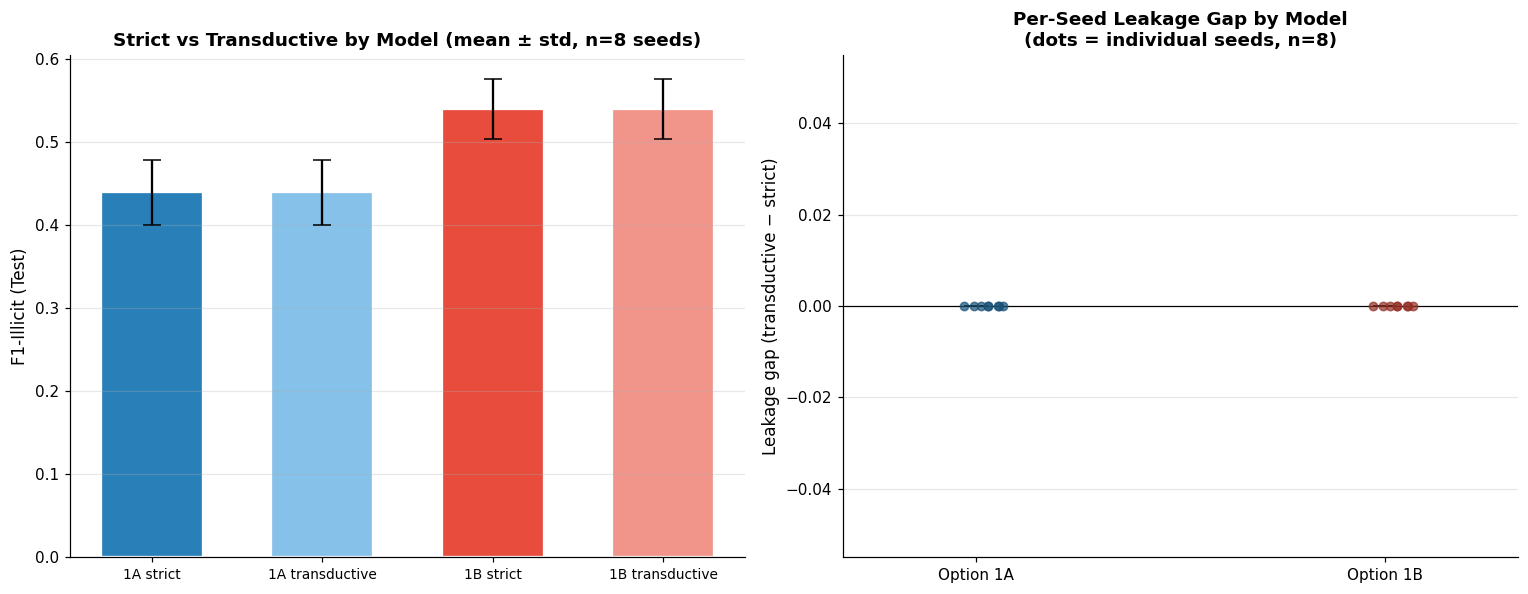

✓ Saved multiseed_leakage_ablation.png

Does the constraint's advantage hold under the STRICT temporal split across seeds?
  1A strict: 0.4397 ± 0.0394
  1B strict: 0.5400 ± 0.0364
  Mean difference (1B - 1A): +0.1002  |  1B wins 8/8 seeds
  Paired t-test: t=7.367, p=0.0002
  Wilcoxon:      W=0.000, p=0.0078

✓ multiseed_leakage_results dict ready for export


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)


checkpoint saved: 217 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


In [31]:
from scipy.stats import ttest_rel, wilcoxon

# ── Aggregate: mean ± std per condition ────────────────────────────────────
print(f"{'Condition':<20} {'F1-illicit mean±std':<24}")
print("-" * 46)
conditions = [('1A strict', sweep_1a_strict), ('1A transductive', sweep_1a_trans),
              ('1B strict', sweep_1b_strict), ('1B transductive', sweep_1b_trans)]
for name, sweep in conditions:
    vals = np.array([r['node_f1_illicit'] for r in sweep])
    print(f"{name:<20} {vals.mean():.4f} ± {vals.std():.4f}")

# ── Per-seed leakage gap (transductive - strict), paired by seed ─────────────
gap_1a = np.array([t['node_f1_illicit'] - s['node_f1_illicit']
                    for s, t in zip(sweep_1a_strict, sweep_1a_trans)])
gap_1b = np.array([t['node_f1_illicit'] - s['node_f1_illicit']
                    for s, t in zip(sweep_1b_strict, sweep_1b_trans)])

print(f"\nLeakage gap (transductive minus strict, F1-illicit), across {N_SEEDS_H} seeds:")
print(f"  Option 1A: {gap_1a.mean():+.4f} ± {gap_1a.std():.4f}   (per-seed: {[round(g,3) for g in gap_1a]})")
print(f"  Option 1B: {gap_1b.mean():+.4f} ± {gap_1b.std():.4f}   (per-seed: {[round(g,3) for g in gap_1b]})")

# Question 1 & 2: is each model's own strict-vs-transductive gap real (different from zero)?
print(f"\nIs each model's leakage gap different from zero?")
for name, strict_sweep, trans_sweep in [('1A', sweep_1a_strict, sweep_1a_trans),
                                          ('1B', sweep_1b_strict, sweep_1b_trans)]:
    s_vals = np.array([r['node_f1_illicit'] for r in strict_sweep])
    t_vals = np.array([r['node_f1_illicit'] for r in trans_sweep])
    t_stat, t_p = ttest_rel(t_vals, s_vals)
    try:
        w_stat, w_p = wilcoxon(t_vals, s_vals)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')
    print(f"  Option {name}: paired t-test p={t_p:.4f}, Wilcoxon p={w_p:.4f}")

# Question 3: is the ASYMMETRY itself real (is 1B's gap bigger than 1A's gap)?
t_stat_asym, t_p_asym = ttest_rel(gap_1b, gap_1a)
try:
    w_stat_asym, w_p_asym = wilcoxon(gap_1b, gap_1a)
except ValueError:
    w_stat_asym, w_p_asym = float('nan'), float('nan')
print(f"\nIs the asymmetry itself real (1B's leakage gap vs 1A's leakage gap, paired by seed)?")
print(f"  Mean difference (1B gap − 1A gap): {(gap_1b - gap_1a).mean():+.4f}")
print(f"  Paired t-test: t={t_stat_asym:.3f}, p={t_p_asym:.4f}")
print(f"  Wilcoxon:      W={w_stat_asym:.3f}, p={w_p_asym:.4f}")

# ── Visualisation ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
means = [np.mean([r['node_f1_illicit'] for r in sweep]) for _, sweep in conditions]
stds  = [np.std([r['node_f1_illicit'] for r in sweep]) for _, sweep in conditions]
colours = ['#2980b9', '#85c1e9', '#e74c3c', '#f1948a']
bars = ax.bar([c[0] for c in conditions], means, yerr=stds, capsize=6,
              color=colours, edgecolor='white', linewidth=1.5, width=0.6)
ax.set_ylabel('F1-Illicit (Test)', fontsize=11)
ax.set_title(f'Strict vs Transductive by Model (mean ± std, n={N_SEEDS_H} seeds)',
             fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', labelsize=9)

ax2 = axes[1]
jitter_a = np.random.RandomState(0).normal(0, 0.03, N_SEEDS_H)
jitter_b = np.random.RandomState(0).normal(0, 0.03, N_SEEDS_H)
ax2.bar(['Option 1A', 'Option 1B'], [gap_1a.mean(), gap_1b.mean()],
        yerr=[gap_1a.std(), gap_1b.std()], capsize=8,
        color=['#2980b9', '#e74c3c'], edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
ax2.scatter(np.zeros(N_SEEDS_H) + jitter_a, gap_1a, color='#1a5276', zorder=3, s=30, alpha=0.7)
ax2.scatter(np.ones(N_SEEDS_H) + jitter_b, gap_1b, color='#943126', zorder=3, s=30, alpha=0.7)
ax2.axhline(y=0, color='black', linewidth=0.8)
ax2.set_ylabel('Leakage gap (transductive − strict)', fontsize=11)
ax2.set_title(f'Per-Seed Leakage Gap by Model\n(dots = individual seeds, n={N_SEEDS_H})',
              fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('multiseed_leakage_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Saved multiseed_leakage_ablation.png")

# ── Closing the loop: does the constraint's advantage under the STRICT (honest,
# no-leakage) temporal split actually replicate across seeds? This is the direct
# multi-seed test of the single-run result from Section 16, using the strict-split
# sweep already collected above -- no additional training needed.
strict_a_vals = np.array([r['node_f1_illicit'] for r in sweep_1a_strict])
strict_b_vals = np.array([r['node_f1_illicit'] for r in sweep_1b_strict])
strict_diff   = strict_b_vals - strict_a_vals
t_stat_strict, t_p_strict = ttest_rel(strict_b_vals, strict_a_vals)
try:
    w_stat_strict, w_p_strict = wilcoxon(strict_b_vals, strict_a_vals)
except ValueError:
    w_stat_strict, w_p_strict = float('nan'), float('nan')

print(f"\nDoes the constraint's advantage hold under the STRICT temporal split across seeds?")
print(f"  1A strict: {strict_a_vals.mean():.4f} ± {strict_a_vals.std():.4f}")
print(f"  1B strict: {strict_b_vals.mean():.4f} ± {strict_b_vals.std():.4f}")
print(f"  Mean difference (1B - 1A): {strict_diff.mean():+.4f}  |  1B wins {int((strict_diff > 0).sum())}/{N_SEEDS_H} seeds")
print(f"  Paired t-test: t={t_stat_strict:.3f}, p={t_p_strict:.4f}")
print(f"  Wilcoxon:      W={w_stat_strict:.3f}, p={w_p_strict:.4f}")
if t_p_strict >= 0.05:
    print(f"\n  Not significant at n={N_SEEDS_H}. Report the point estimate and the seeds won, without claiming an effect.")

multiseed_leakage_results = {
    'n_seeds': N_SEEDS_H,
    'condition_means': {name: {'mean': float(np.mean([r['node_f1_illicit'] for r in sweep])),
                                'std': float(np.std([r['node_f1_illicit'] for r in sweep]))}
                         for name, sweep in conditions},
    'leakage_gap_1a': {'mean': float(gap_1a.mean()), 'std': float(gap_1a.std()), 'per_seed': [float(g) for g in gap_1a]},
    'leakage_gap_1b': {'mean': float(gap_1b.mean()), 'std': float(gap_1b.std()), 'per_seed': [float(g) for g in gap_1b]},
    'asymmetry_test': {'mean_diff_1b_minus_1a_gap': float((gap_1b - gap_1a).mean()),
                        'ttest_p': float(t_p_asym), 'wilcoxon_p': float(w_p_asym)},
    'strict_split_1a_vs_1b': {'mean_diff': float(strict_diff.mean()),
                               'wins_for_1b': int((strict_diff > 0).sum()), 'n_seeds': N_SEEDS_H,
                               'ttest_p': float(t_p_strict), 'wilcoxon_p': float(w_p_strict)},
}
print("\n\u2713 multiseed_leakage_results dict ready for export")

save_checkpoint()

## 21. Multi-Seed Link Prediction Under Temporal Shift

Every temporal multi-seed result so far (Sections 17, 20) tracked node classification metrics only. `evaluate()` has always also returned `link_auc` and `link_ap` for every one of those calls, it just wasn't extracted. This adds no new training: `sweep_1a_strict` and `sweep_1b_strict` from Experiment H already contain 8 seeds of link prediction performance under the strict temporal setup, sitting unused.

MULTI-SEED LINK PREDICTION, TEMPORAL SPLIT (STRICT)

link_auc:
  1A: 0.6966 ± 0.0085
  1B: 0.6123 ± 0.0134
  Mean difference (1B - 1A): -0.0842
  Paired t-test: t=-15.154, p=0.0000  |  Wilcoxon: p=0.0078

link_ap:
  1A: 0.7041 ± 0.0103
  1B: 0.6119 ± 0.0145
  Mean difference (1B - 1A): -0.0922
  Paired t-test: t=-17.186, p=0.0000  |  Wilcoxon: p=0.0078


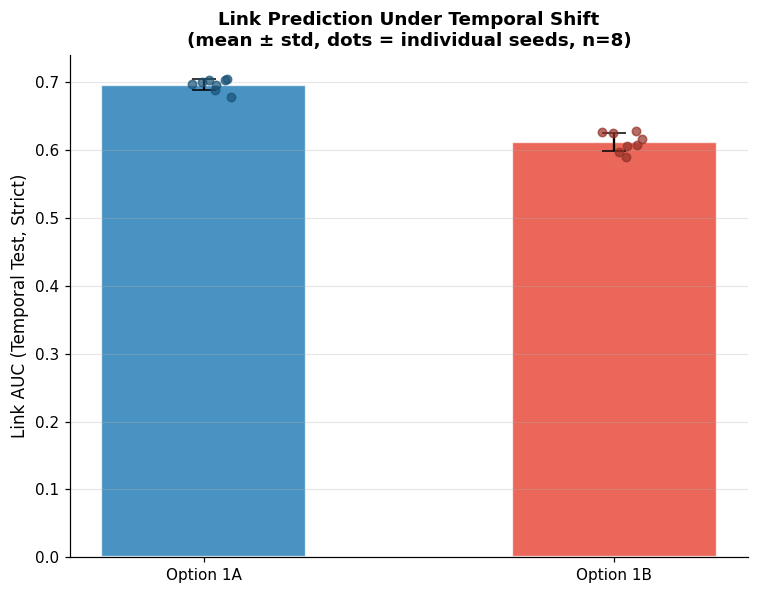


✓ Saved multiseed_temporal_link_auc.png

✓ multiseed_temporal_link_results dict ready for export


In [32]:
print("=" * 65)
print("MULTI-SEED LINK PREDICTION, TEMPORAL SPLIT (STRICT)")
print("=" * 65)

for metric in ['link_auc', 'link_ap']:
    a_vals = np.array([r[metric] for r in sweep_1a_strict])
    b_vals = np.array([r[metric] for r in sweep_1b_strict])
    t_stat, t_p = ttest_rel(b_vals, a_vals)
    try:
        w_stat, w_p = wilcoxon(b_vals, a_vals)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')
    print(f"\n{metric}:")
    print(f"  1A: {a_vals.mean():.4f} ± {a_vals.std():.4f}")
    print(f"  1B: {b_vals.mean():.4f} ± {b_vals.std():.4f}")
    print(f"  Mean difference (1B - 1A): {(b_vals - a_vals).mean():+.4f}")
    print(f"  Paired t-test: t={t_stat:.3f}, p={t_p:.4f}  |  Wilcoxon: p={w_p:.4f}")

fig, ax = plt.subplots(figsize=(7, 5.5))
link_auc_a = np.array([r['link_auc'] for r in sweep_1a_strict])
link_auc_b = np.array([r['link_auc'] for r in sweep_1b_strict])
jitter_a = np.random.RandomState(0).normal(0, 0.03, len(sweep_1a_strict))
jitter_b = np.random.RandomState(0).normal(0, 0.03, len(sweep_1b_strict))
ax.bar(['Option 1A', 'Option 1B'], [link_auc_a.mean(), link_auc_b.mean()],
       yerr=[link_auc_a.std(), link_auc_b.std()], capsize=8,
       color=['#2980b9', '#e74c3c'], edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
ax.scatter(np.zeros(len(sweep_1a_strict)) + jitter_a, link_auc_a, color='#1a5276', zorder=3, s=30, alpha=0.7)
ax.scatter(np.ones(len(sweep_1b_strict)) + jitter_b, link_auc_b, color='#943126', zorder=3, s=30, alpha=0.7)
ax.set_ylabel('Link AUC (Temporal Test, Strict)', fontsize=11)
ax.set_title(f'Link Prediction Under Temporal Shift\n(mean ± std, dots = individual seeds, n={len(sweep_1a_strict)})',
             fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('multiseed_temporal_link_auc.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n\u2713 Saved multiseed_temporal_link_auc.png")

multiseed_temporal_link_results = {
    m: {'1a': {'mean': float(np.mean([r[m] for r in sweep_1a_strict])), 'std': float(np.std([r[m] for r in sweep_1a_strict]))},
        '1b': {'mean': float(np.mean([r[m] for r in sweep_1b_strict])), 'std': float(np.std([r[m] for r in sweep_1b_strict]))}}
    for m in ['link_auc', 'link_ap']
}
print("\n\u2713 multiseed_temporal_link_results dict ready for export")

## 22. Experiment I — Temporal Split Threshold Optimisation

The temporal split results in Section 16 report precision at the default 0.5 decision threshold. On its own, that number is easy to misread as a failure of the model. It's actually a property of the threshold, not necessarily the model: 0.5 is an arbitrary cutoff on the softmax probability, and it was never tuned for this specific, far more imbalanced test period (1,083 illicit against 15,587 licit in the temporal test set, versus a much closer to balanced ratio in the random-split test set).

This experiment computes the full precision-recall curve for both temporal models and reports what performance looks like across the threshold range, rather than at one arbitrary cutoff. This matters for deployment: an AML system's operating point is a business decision (how many false leads can investigators absorb) as much as a modelling one, and reporting only the default-threshold number understates what the model can actually do.

No retraining is needed here. `model_1a_temporal` and `model_1b_temporal` are already trained; this experiment only re-reads their predicted probabilities on the existing temporal test set at every possible threshold.

In [33]:
from sklearn.metrics import precision_recall_curve, auc as sk_auc

print("=" * 65)
print("EXPERIMENT I: TEMPORAL SPLIT THRESHOLD OPTIMISATION")
print("=" * 65)

@torch.no_grad()
def get_node_probs(model, data, split, device, constrained=False):
    """Returns (y_true, y_prob_illicit) for the given split -- no thresholding applied."""
    model.eval()
    x, y = data.x.to(device), data.y.to(device)
    ei   = data.full_edge_index.to(device)
    mask = getattr(data, f'{split}_mask').to(device)
    eli  = getattr(data, f'{split}_edge_label_index').to(device)
    if constrained:
        node_pred, _, _ = model.forward_with_constraint(x, ei, eli, y)
    else:
        node_pred, _ = model(x, ei, eli)
    yt = y[mask].cpu().numpy()
    yp = F.softmax(node_pred[mask], dim=-1)[:, 1].cpu().numpy()
    return yt, yp

# Validation split -- used ONLY to select the operating threshold, never to report
# final performance. Test split -- used ONLY to report performance at that fixed,
# pre-selected threshold. Selecting the threshold on the test set itself would
# leak test information into what looks like a held-out result.
yt_1a_val, yp_1a_val = get_node_probs(model_1a_temporal, data_temporal, 'val', device)
yt_1b_val, yp_1b_val = get_node_probs(model_1b_temporal, data_temporal, 'val', device, constrained=True)

yt_1a, yp_1a = get_node_probs(model_1a_temporal, data_temporal, 'test', device)
yt_1b, yp_1b = get_node_probs(model_1b_temporal, data_temporal, 'test', device, constrained=True)

prec_1a, rec_1a, thr_1a = precision_recall_curve(yt_1a, yp_1a)
prec_1b, rec_1b, thr_1b = precision_recall_curve(yt_1b, yp_1b)
ap_1a = average_precision_score(yt_1a, yp_1a)
ap_1b = average_precision_score(yt_1b, yp_1b)

# PR curve on validation, used only to pick the threshold
prec_1a_val, rec_1a_val, thr_1a_val = precision_recall_curve(yt_1a_val, yp_1a_val)
prec_1b_val, rec_1b_val, thr_1b_val = precision_recall_curve(yt_1b_val, yp_1b_val)

print(f"Temporal test set: {len(yt_1a):,} nodes ({int((yt_1a==1).sum()):,} illicit, "
      f"{int((yt_1a==0).sum()):,} licit, ratio 1:{(yt_1a==0).sum()/(yt_1a==1).sum():.1f})")
print(f"\nAverage precision (PR-AUC): 1A={ap_1a:.4f}  1B={ap_1b:.4f}")

# ── Find, for each model, the threshold that maximises F1, and the threshold
# that reaches a target precision floor (0.5 -- an illustrative "half the
# flagged transactions are real" bar an investigations team might set) ──
def best_f1_threshold(prec, rec, thr):
    f1s = np.where((prec[:-1] + rec[:-1]) > 0, 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12), 0)
    best_i = np.argmax(f1s)
    return thr[best_i], prec[best_i], rec[best_i], f1s[best_i]

def threshold_for_precision(prec, rec, thr, target=0.5):
    ok = np.where(prec[:-1] >= target)[0]
    if len(ok) == 0:
        return None
    i = ok[np.argmax(rec[:-1][ok])]  # among thresholds hitting the precision floor, take best recall
    return thr[i], prec[i], rec[i]

print(f"\n{'Model':<6} {'Default (0.5)':<28} {'Best-F1 threshold':<32}")
print("-" * 66)
for name, yt, yp, prec, rec, thr in [('1A', yt_1a, yp_1a, prec_1a, rec_1a, thr_1a),
                                       ('1B', yt_1b, yp_1b, prec_1b, rec_1b, thr_1b)]:
    yp_default = (yp >= 0.5).astype(int)
    p_def = precision_score(yt, yp_default, zero_division=0)
    r_def = recall_score(yt, yp_default, zero_division=0)
    f_def = f1_score(yt, yp_default, zero_division=0)
    t_best, p_best, r_best, f_best = best_f1_threshold(prec, rec, thr)
    print(f"{name:<6} P={p_def:.4f} R={r_def:.4f} F1={f_def:.4f}      "
          f"t={t_best:.3f} P={p_best:.4f} R={r_best:.4f} F1={f_best:.4f}")

print(f"\nThreshold to reach precision >= 0.50 (illustrative investigator-workload bar, test set):")
for name, prec, rec, thr in [('1A', prec_1a, rec_1a, thr_1a), ('1B', prec_1b, rec_1b, thr_1b)]:
    result = threshold_for_precision(prec, rec, thr, target=0.5)
    if result is None:
        print(f"  {name}: precision 0.50 is not reachable at any threshold on this test set.")
    else:
        t, p, r = result
        print(f"  {name}: threshold={t:.3f}  ->  precision={p:.4f}, recall={r:.4f}")

# ── Correct procedure: select the threshold on VALIDATION, apply it to TEST ──
print(f"\n{'=' * 65}")
print(f"VALIDATION-SELECTED THRESHOLD, APPLIED TO TEST (the number to report)")
print(f"{'=' * 65}")

def apply_threshold(yt, yp, t):
    pred = (yp >= t).astype(int)
    return (precision_score(yt, pred, zero_division=0),
            recall_score(yt, pred, zero_division=0),
            f1_score(yt, pred, zero_division=0))

t_val_1a, p_val_1a, r_val_1a, f_val_1a = best_f1_threshold(prec_1a_val, rec_1a_val, thr_1a_val)
t_val_1b, p_val_1b, r_val_1b, f_val_1b = best_f1_threshold(prec_1b_val, rec_1b_val, thr_1b_val)

p_test_1a, r_test_1a, f_test_1a = apply_threshold(yt_1a, yp_1a, t_val_1a)
p_test_1b, r_test_1b, f_test_1b = apply_threshold(yt_1b, yp_1b, t_val_1b)

print(f"\n{'Model':<6} {'Threshold (from val)':<22} {'Test Precision':<16} {'Test Recall':<14} {'Test F1':<10}")
print("-" * 68)
print(f"{'1A':<6} {t_val_1a:<22.3f} {p_test_1a:<16.4f} {r_test_1a:<14.4f} {f_test_1a:<10.4f}")
print(f"{'1B':<6} {t_val_1b:<22.3f} {p_test_1b:<16.4f} {r_test_1b:<14.4f} {f_test_1b:<10.4f}")
print(f"\nThis is the honest, leakage-free number: the threshold was chosen without ever")
print(f"looking at test labels, then evaluated once. Compare against the default-0.5 row")
print(f"above to see how much of the earlier low-precision result was the threshold, not the model.")

EXPERIMENT I: TEMPORAL SPLIT THRESHOLD OPTIMISATION
Temporal test set: 16,670 nodes (1,083 illicit, 15,587 licit, ratio 1:14.4)

Average precision (PR-AUC): 1A=0.5055  1B=0.6376

Model  Default (0.5)                Best-F1 threshold               
------------------------------------------------------------------
1A     P=0.3467 R=0.6870 F1=0.4608      t=0.945 P=0.6546 R=0.5531 F1=0.5996
1B     P=0.5010 R=0.6750 F1=0.5751      t=0.876 P=0.7567 R=0.5974 F1=0.6677

Threshold to reach precision >= 0.50 (illustrative investigator-workload bar, test set):
  1A: threshold=0.814  ->  precision=0.5000, recall=0.6260
  1B: threshold=0.498  ->  precision=0.5000, recall=0.6759

VALIDATION-SELECTED THRESHOLD, APPLIED TO TEST (the number to report)

Model  Threshold (from val)   Test Precision   Test Recall    Test F1   
--------------------------------------------------------------------
1A     0.776                  0.4703           0.6362         0.5408    
1B     0.751                  0.6564  

## 23. Experiment K — Multi-Seed Temporal Threshold Optimisation

Experiment I selected the decision threshold on validation data instead of using 0.5, and it did so for a single run. A threshold chosen by scanning the test set would be leakage, so the threshold is always chosen on the validation set and then applied unchanged to the test set.

This experiment repeats the analysis across the same 8 seeds used throughout. For each seed it retrains Option 1A and Option 1B on the temporal split, selects the threshold independently on validation data, and reports precision, recall, F1 and average precision on the test set at that threshold. The result is a mean ± SD and a paired significance test for the threshold-based comparison, which is the central comparison of Options 1A and 1B.

Experiment H did not keep the trained models or their probability outputs (they were deleted after the default-threshold metrics were computed, to save memory), so the training here cannot be skipped or reused.


In [34]:
print("=" * 65)
print("EXPERIMENT K: MULTI-SEED TEMPORAL THRESHOLD OPTIMISATION")
print("=" * 65)
print(f"Seeds: {SEEDS_LIST_H}\n")

def train_and_get_probs(model_cls, seed, train_fn, extra_kwargs, label):
    """Trains once on data_temporal and returns (val_probs, test_probs) as
    (y_true, y_prob_illicit) tuples, before the model is discarded."""
    torch.manual_seed(seed); np.random.seed(seed)
    m = model_cls(data_temporal.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(seed)
    training_loop(m, train_fn, {'optimizer': opt, **extra_kwargs}, label, data=data_temporal, verbose=False)
    constrained = hasattr(m, 'forward_with_constraint')
    val_probs  = get_node_probs(m, data_temporal, 'val',  device, constrained=constrained)
    test_probs = get_node_probs(m, data_temporal, 'test', device, constrained=constrained)
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return val_probs, test_probs

k_sweep_1a, k_sweep_1b = [], []

for i, sd in enumerate(SEEDS_LIST_H):
    t0 = datetime.now()

    (yt_v, yp_v), (yt_t, yp_t) = train_and_get_probs(DualTaskGNN, sd, train_1a, {'alpha': ALPHA}, f"1A seed={sd}")
    prec_v, rec_v, thr_v = precision_recall_curve(yt_v, yp_v)
    t_best, _, _, _ = best_f1_threshold(prec_v, rec_v, thr_v)
    p, r, f1 = apply_threshold(yt_t, yp_t, t_best)
    ap = average_precision_score(yt_t, yp_t)
    k_sweep_1a.append({'threshold': t_best, 'precision': p, 'recall': r, 'f1': f1, 'ap': ap})

    (yt_v, yp_v), (yt_t, yp_t) = train_and_get_probs(ConstrainedDualTaskGNN, sd, train_1b,
                                                       {'alpha': ALPHA, 'lam': LAMBDA}, f"1B seed={sd}")
    prec_v, rec_v, thr_v = precision_recall_curve(yt_v, yp_v)
    t_best, _, _, _ = best_f1_threshold(prec_v, rec_v, thr_v)
    p, r, f1 = apply_threshold(yt_t, yp_t, t_best)
    ap = average_precision_score(yt_t, yp_t)
    k_sweep_1b.append({'threshold': t_best, 'precision': p, 'recall': r, 'f1': f1, 'ap': ap})

    print(f"[{i+1}/{len(SEEDS_LIST_H)}] seed={sd} done in {(datetime.now()-t0).total_seconds():.1f}s | "
          f"1A F1={k_sweep_1a[-1]['f1']:.4f} (t={k_sweep_1a[-1]['threshold']:.3f}) | "
          f"1B F1={k_sweep_1b[-1]['f1']:.4f} (t={k_sweep_1b[-1]['threshold']:.3f})")

print("\n\u2713 All 8 seeds trained and thresholded")

EXPERIMENT K: MULTI-SEED TEMPORAL THRESHOLD OPTIMISATION
Seeds: [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042]


✓ 1A seed=42 | 35.7s | Best val: 0.7961

✓ 1B seed=42 | 36.4s | Best val: 0.7619
[1/8] seed=42 done in 72.5s | 1A F1=0.5408 (t=0.776) | 1B F1=0.6438 (t=0.751)

✓ 1A seed=1042 | 32.0s | Best val: 0.7966

✓ 1B seed=1042 | 27.2s | Best val: 0.7526
[2/8] seed=1042 done in 59.5s | 1A F1=0.5664 (t=0.825) | 1B F1=0.6187 (t=0.806)

✓ 1A seed=2042 | 19.7s | Best val: 0.7826

✓ 1B seed=2042 | 22.1s | Best val: 0.7428
[3/8] seed=2042 done in 42.1s | 1A F1=0.5340 (t=0.827) | 1B F1=0.6051 (t=0.774)

✓ 1A seed=3042 | 28.4s | Best val: 0.7931

✓ 1B seed=3042 | 30.6s | Best val: 0.7547
[4/8] seed=3042 done in 59.4s | 1A F1=0.5797 (t=0.686) | 1B F1=0.6690 (t=0.802)

✓ 1A seed=4042 | 35.0s | Best val: 0.7823

✓ 1B seed=4042 | 35.1s | Best val: 0.7650
[5/8] seed=4042 done in 70.5s | 1A F1=0.4934 (t=0.718) | 1B F1=0.5520 (t=0.507)

✓ 1A seed=5042 | 25.6s | Best val: 0.7765

✓ 1B seed=5042 | 34.

Metric       1A mean±std          1B mean±std         
----------------------------------------------------
threshold    0.7800 ± 0.0509      0.7113 ± 0.0972
precision    0.4520 ± 0.0515      0.5831 ± 0.0753
recall       0.6596 ± 0.0171      0.6428 ± 0.0136
f1           0.5341 ± 0.0336      0.6082 ± 0.0354
ap           0.5305 ± 0.0208      0.6481 ± 0.0208

Paired test, F1 at validation-selected threshold, 8 seeds (1B vs 1A):
  Mean difference (1B - 1A): +0.0741  |  1B wins 8/8 seeds
  Paired t-test: t=5.744, p=0.0007
  Wilcoxon:      W=0.000, p=0.0078

Paired test, PR-AUC, 8 seeds (1B vs 1A):
  Mean difference (1B - 1A): +0.1176  |  1B wins 8/8 seeds
  Paired t-test: t=8.912, p=0.0000
  Wilcoxon:      W=0.000, p=0.0078


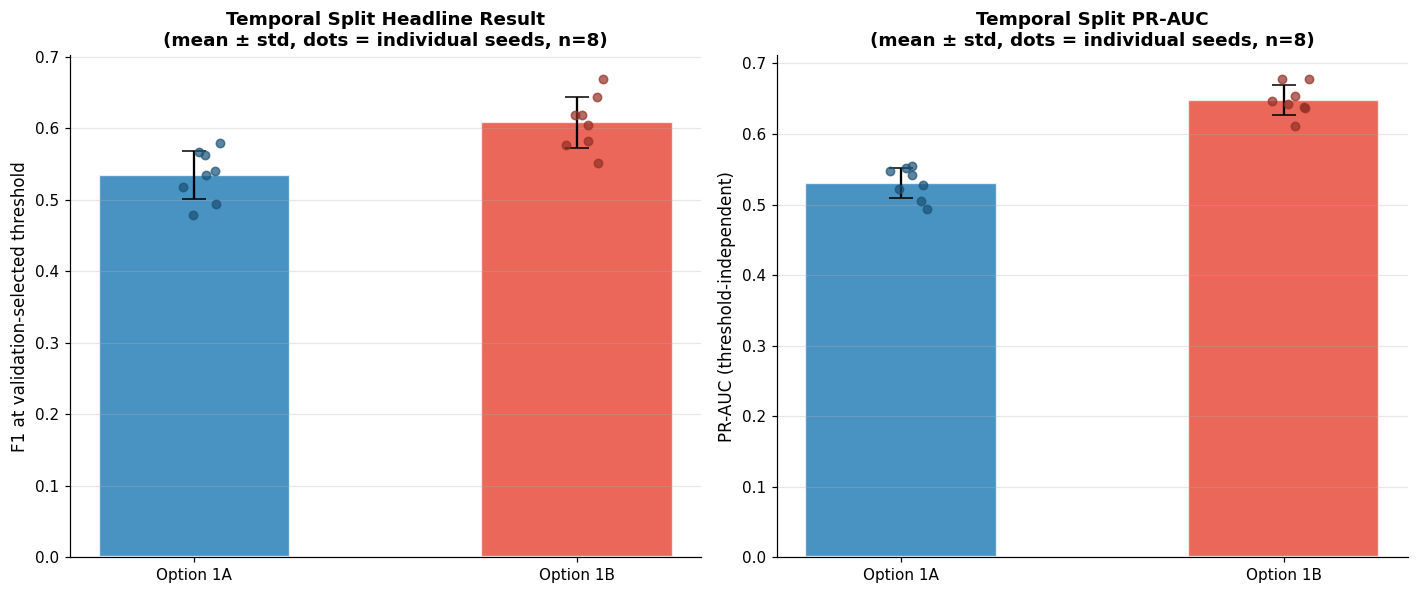


✓ Saved multiseed_temporal_threshold.png

VALIDATION-SELECTED THRESHOLD RESULT (temporal, multi-seed)
  1A: F1=0.5341±0.0336   AP=0.5305±0.0208
  1B: F1=0.6082±0.0354   AP=0.6481±0.0208

  SIGNIFICANT at the validation-selected threshold (p=0.0007).
  State the operating-threshold condition when reporting this result.

✓ multiseed_temporal_threshold_results dict ready for export


In [35]:
# ── Aggregate: mean ± std across 8 seeds, at each seed's own validation-selected threshold ──
print(f"{'Metric':<12} {'1A mean±std':<20} {'1B mean±std':<20}")
print("-" * 52)
for metric in ['threshold', 'precision', 'recall', 'f1', 'ap']:
    a_vals = np.array([r[metric] for r in k_sweep_1a])
    b_vals = np.array([r[metric] for r in k_sweep_1b])
    print(f"{metric:<12} {a_vals.mean():.4f} ± {a_vals.std():.4f}      {b_vals.mean():.4f} ± {b_vals.std():.4f}")

# ── Paired significance test on F1 at validation-selected threshold: this is the
# central question the whole notebook has been building toward. ──
a_f1 = np.array([r['f1'] for r in k_sweep_1a])
b_f1 = np.array([r['f1'] for r in k_sweep_1b])
t_stat_k, t_p_k = ttest_rel(b_f1, a_f1)
try:
    w_stat_k, w_p_k = wilcoxon(b_f1, a_f1)
except ValueError:
    w_stat_k, w_p_k = float('nan'), float('nan')

print(f"\nPaired test, F1 at validation-selected threshold, 8 seeds (1B vs 1A):")
print(f"  Mean difference (1B - 1A): {(b_f1 - a_f1).mean():+.4f}  |  1B wins {int((b_f1 > a_f1).sum())}/8 seeds")
print(f"  Paired t-test: t={t_stat_k:.3f}, p={t_p_k:.4f}")
print(f"  Wilcoxon:      W={w_stat_k:.3f}, p={w_p_k:.4f}")

# Same test on PR-AUC (threshold-independent, arguably the cleanest single number)
a_ap = np.array([r['ap'] for r in k_sweep_1a])
b_ap = np.array([r['ap'] for r in k_sweep_1b])
t_stat_ap, t_p_ap = ttest_rel(b_ap, a_ap)
try:
    w_stat_ap, w_p_ap = wilcoxon(b_ap, a_ap)
except ValueError:
    w_stat_ap, w_p_ap = float('nan'), float('nan')
print(f"\nPaired test, PR-AUC, 8 seeds (1B vs 1A):")
print(f"  Mean difference (1B - 1A): {(b_ap - a_ap).mean():+.4f}  |  1B wins {int((b_ap > a_ap).sum())}/8 seeds")
print(f"  Paired t-test: t={t_stat_ap:.3f}, p={t_p_ap:.4f}")
print(f"  Wilcoxon:      W={w_stat_ap:.3f}, p={w_p_ap:.4f}")

# ── Visualisation ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
jitter_a = np.random.RandomState(0).normal(0, 0.03, len(SEEDS_LIST_H))
jitter_b = np.random.RandomState(0).normal(0, 0.03, len(SEEDS_LIST_H))
ax.bar(['Option 1A', 'Option 1B'], [a_f1.mean(), b_f1.mean()], yerr=[a_f1.std(), b_f1.std()],
       capsize=8, color=['#2980b9', '#e74c3c'], edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
ax.scatter(np.zeros(len(SEEDS_LIST_H)) + jitter_a, a_f1, color='#1a5276', zorder=3, s=30, alpha=0.7)
ax.scatter(np.ones(len(SEEDS_LIST_H)) + jitter_b, b_f1, color='#943126', zorder=3, s=30, alpha=0.7)
ax.set_ylabel('F1 at validation-selected threshold', fontsize=11)
ax.set_title(f'Temporal Split Headline Result\n(mean ± std, dots = individual seeds, n={len(SEEDS_LIST_H)})',
             fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

ax2 = axes[1]
ax2.bar(['Option 1A', 'Option 1B'], [a_ap.mean(), b_ap.mean()], yerr=[a_ap.std(), b_ap.std()],
        capsize=8, color=['#2980b9', '#e74c3c'], edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
ax2.scatter(np.zeros(len(SEEDS_LIST_H)) + jitter_a, a_ap, color='#1a5276', zorder=3, s=30, alpha=0.7)
ax2.scatter(np.ones(len(SEEDS_LIST_H)) + jitter_b, b_ap, color='#943126', zorder=3, s=30, alpha=0.7)
ax2.set_ylabel('PR-AUC (threshold-independent)', fontsize=11)
ax2.set_title(f'Temporal Split PR-AUC\n(mean ± std, dots = individual seeds, n={len(SEEDS_LIST_H)})',
              fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('multiseed_temporal_threshold.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n\u2713 Saved multiseed_temporal_threshold.png")

multiseed_temporal_threshold_results = {
    'n_seeds': len(SEEDS_LIST_H),
    'option_1a': {m: {'mean': float(np.mean([r[m] for r in k_sweep_1a])), 'std': float(np.std([r[m] for r in k_sweep_1a]))}
                  for m in ['threshold', 'precision', 'recall', 'f1', 'ap']},
    'option_1b': {m: {'mean': float(np.mean([r[m] for r in k_sweep_1b])), 'std': float(np.std([r[m] for r in k_sweep_1b]))}
                  for m in ['threshold', 'precision', 'recall', 'f1', 'ap']},
    'f1_paired_test': {'mean_diff': float((b_f1 - a_f1).mean()), 'wins_for_1b': int((b_f1 > a_f1).sum()),
                        'ttest_p': float(t_p_k), 'wilcoxon_p': float(w_p_k)},
    'ap_paired_test': {'mean_diff': float((b_ap - a_ap).mean()), 'wins_for_1b': int((b_ap > a_ap).sum()),
                        'ttest_p': float(t_p_ap), 'wilcoxon_p': float(w_p_ap)},
}

print(f"\n{'='*65}")
print(f"VALIDATION-SELECTED THRESHOLD RESULT (temporal, multi-seed)")
print(f"{'='*65}")
print(f"  1A: F1={a_f1.mean():.4f}±{a_f1.std():.4f}   AP={a_ap.mean():.4f}±{a_ap.std():.4f}")
print(f"  1B: F1={b_f1.mean():.4f}±{b_f1.std():.4f}   AP={b_ap.mean():.4f}±{b_ap.std():.4f}")
if t_p_k < 0.05 or w_p_k < 0.05:
    print(f"\n  SIGNIFICANT at the validation-selected threshold (p={min(t_p_k, w_p_k):.4f}).")
    print(f"  State the operating-threshold condition when reporting this result.")
else:
    print(f"\n  NOT significant at the validation-selected threshold (p={min(t_p_k, w_p_k):.4f}).")
    print(f"  Report means, paired differences and seeds won, without claiming an improvement.")
print(f"\n\u2713 multiseed_temporal_threshold_results dict ready for export")

In [36]:
def train_node_only_probs(data_obj, seed):
    """Node-only model, early stopping on validation macro-F1 (its own task metric).
    Returns ((y_val, p_val), (y_test, p_test)) with p = P(illicit)."""
    torch.manual_seed(seed); np.random.seed(seed)
    m   = NodeOnlyGNN(data_obj.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(seed)
    best_val, best_state, pat = 0.0, None, 0
    for epoch in range(NUM_EPOCHS):
        train_node_only(m, data_obj, opt, device)
        v = evaluate_node_only(m, data_obj, 'val', device)['node_f1_macro']
        if v > best_val:
            best_val, pat = v, 0
            best_state = {k: t.cpu().clone() for k, t in m.state_dict().items()}
        else:
            pat += 1
        if pat >= PATIENCE and epoch >= MIN_EPOCHS:
            break

    m.load_state_dict(best_state)
    out = {}
    with torch.no_grad():
        m.eval()
        x, y = data_obj.x.to(device), data_obj.y.to(device)
        logits = m(x, data_obj.full_edge_index.to(device))
        for sp in ['val', 'test']:
            mk = getattr(data_obj, f'{sp}_mask').to(device)
            out[sp] = (y[mk].cpu().numpy(), F.softmax(logits[mk], dim=-1)[:, 1].cpu().numpy())
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return out['val'], out['test']

def node_metrics_at(yt, yp, t):
    pred = (yp >= t).astype(int)
    return {'f1_illicit': f1_score(yt, pred, zero_division=0),
            'f1_macro':   f1_score(yt, pred, average='macro', zero_division=0),
            'precision':  precision_score(yt, pred, zero_division=0),
            'recall':     recall_score(yt, pred, zero_division=0)}

def paired_report(label, ref_vals, base_vals, ref_name='1A'):
    r, b = np.array(ref_vals), np.array(base_vals)
    t_stat, t_p = ttest_rel(r, b)
    try:
        w_stat, w_p = wilcoxon(r, b)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')
    print(f"  {label}: {ref_name} {r.mean():.4f} ± {r.std():.4f} | baseline {b.mean():.4f} ± {b.std():.4f} | "
          f"{ref_name} - baseline = {np.mean(r - b):+.4f} | {ref_name} wins {int((r > b).sum())}/{len(b)} | "
          f"t-test p={t_p:.4f} | Wilcoxon p={w_p:.4f}")

def tuned_node_metrics(m, data_obj, constrained):
    """Pick the F1-optimal threshold on VALIDATION, apply it to TEST."""
    yt_v, yp_v = get_node_probs(m, data_obj, 'val',  device, constrained=constrained)
    yt_t, yp_t = get_node_probs(m, data_obj, 'test', device, constrained=constrained)
    pv, rv, tv = precision_recall_curve(yt_v, yp_v)
    t_best, _, _, _ = best_f1_threshold(pv, rv, tv)
    p, r, f1 = apply_threshold(yt_t, yp_t, t_best)
    return {'threshold': float(t_best), 'precision': p, 'recall': r, 'f1': f1,
            'ap': average_precision_score(yt_t, yp_t)}

def paired_compare(label, a_name, a_vals, b_name, b_vals):
    a, b = np.array(a_vals), np.array(b_vals)
    t_stat, t_p = ttest_rel(a, b)
    try:
        w_stat, w_p = wilcoxon(a, b)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')
    print(f"  {label}: {a_name} {a.mean():.4f} ± {a.std():.4f} | {b_name} {b.mean():.4f} ± {b.std():.4f} | "
          f"{a_name} - {b_name} = {np.mean(a - b):+.4f} | {a_name} wins {int((a > b).sum())}/{len(a)} | "
          f"t-test p={t_p:.4f} | Wilcoxon p={w_p:.4f}")

In [37]:
print("=" * 65)
print("EXPERIMENT A (MULTI-SEED): NODE-ONLY BASELINE vs OPTION 1A, BOTH SPLITS")
print("=" * 65)

node_only_results = {}
for split_name, dobj, seeds in [('random', data, SEEDS_LIST), ('temporal', data_temporal, SEEDS_LIST_H)]:
    runs = []
    for i, sd in enumerate(seeds):
        (yt_v, yp_v), (yt_t, yp_t) = train_node_only_probs(dobj, sd)
        pv, rv, tv = precision_recall_curve(yt_v, yp_v)
        t_best, _, _, _ = best_f1_threshold(pv, rv, tv)
        d = node_metrics_at(yt_t, yp_t, 0.5)
        v = node_metrics_at(yt_t, yp_t, t_best)
        runs.append({'default_f1_illicit': d['f1_illicit'], 'default_f1_macro': d['f1_macro'],
                     'threshold': float(t_best), 'tuned_precision': v['precision'],
                     'tuned_recall': v['recall'], 'tuned_f1': v['f1_illicit'],
                     'ap': average_precision_score(yt_t, yp_t)})
        print(f"[{split_name} {i+1}/{len(seeds)}] seed={sd} default F1-illicit={d['f1_illicit']:.4f} "
              f"| tuned F1={v['f1_illicit']:.4f} (t={t_best:.3f})")
    node_only_results[split_name] = runs

print("\nPaired comparison against Option 1A (same seeds):")
paired_report("random,   default threshold, F1-illicit",
              [r['node_f1_illicit'] for r in sweep_1a],
              [r['default_f1_illicit'] for r in node_only_results['random']])
paired_report("temporal, default threshold, F1-illicit",
              [r['node_f1_illicit'] for r in sweep_1a_strict],
              [r['default_f1_illicit'] for r in node_only_results['temporal']])
paired_report("temporal, validated threshold, F1-illicit",
              [r['f1'] for r in k_sweep_1a],
              [r['tuned_f1'] for r in node_only_results['temporal']])
paired_report("temporal, average precision",
              [r['ap'] for r in k_sweep_1a],
              [r['ap'] for r in node_only_results['temporal']])

save_checkpoint()

EXPERIMENT A (MULTI-SEED): NODE-ONLY BASELINE vs OPTION 1A, BOTH SPLITS
[random 1/8] seed=42 default F1-illicit=0.8557 | tuned F1=0.8842 (t=0.868)
[random 2/8] seed=1042 default F1-illicit=0.8604 | tuned F1=0.8781 (t=0.800)
[random 3/8] seed=2042 default F1-illicit=0.8494 | tuned F1=0.8731 (t=0.823)
[random 4/8] seed=3042 default F1-illicit=0.8520 | tuned F1=0.8734 (t=0.881)
[random 5/8] seed=4042 default F1-illicit=0.8394 | tuned F1=0.8766 (t=0.865)
[random 6/8] seed=5042 default F1-illicit=0.8637 | tuned F1=0.8828 (t=0.863)
[random 7/8] seed=6042 default F1-illicit=0.8569 | tuned F1=0.8807 (t=0.807)
[random 8/8] seed=7042 default F1-illicit=0.8551 | tuned F1=0.8811 (t=0.800)
[temporal 1/8] seed=42 default F1-illicit=0.5045 | tuned F1=0.5259 (t=0.609)
[temporal 2/8] seed=1042 default F1-illicit=0.4898 | tuned F1=0.5122 (t=0.684)
[temporal 3/8] seed=2042 default F1-illicit=0.4861 | tuned F1=0.5045 (t=0.649)
[temporal 4/8] seed=3042 default F1-illicit=0.4776 | tuned F1=0.5151 (t=0.758)


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)


checkpoint saved: 296 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


In [38]:
print("=" * 65)
print("OPTION 1B vs NODE-ONLY BASELINE (same seeds)")
print("=" * 65)
paired_compare("random,   default threshold, F1-illicit", '1B', [r['node_f1_illicit'] for r in sweep_1b],
               'node-only', [r['default_f1_illicit'] for r in node_only_results['random']])
paired_compare("temporal, default threshold, F1-illicit", '1B', [r['node_f1_illicit'] for r in sweep_1b_strict],
               'node-only', [r['default_f1_illicit'] for r in node_only_results['temporal']])
paired_compare("temporal, validated threshold, F1-illicit", '1B', [r['f1'] for r in k_sweep_1b],
               'node-only', [r['tuned_f1'] for r in node_only_results['temporal']])
paired_compare("temporal, average precision", '1B', [r['ap'] for r in k_sweep_1b],
               'node-only', [r['ap'] for r in node_only_results['temporal']])

OPTION 1B vs NODE-ONLY BASELINE (same seeds)
  random,   default threshold, F1-illicit: 1B 0.8159 ± 0.0078 | node-only 0.8541 ± 0.0070 | 1B - node-only = -0.0382 | 1B wins 0/8 | t-test p=0.0000 | Wilcoxon p=0.0078
  temporal, default threshold, F1-illicit: 1B 0.5400 ± 0.0364 | node-only 0.5061 ± 0.0216 | 1B - node-only = +0.0339 | 1B wins 5/8 | t-test p=0.0849 | Wilcoxon p=0.1484
  temporal, validated threshold, F1-illicit: 1B 0.6082 ± 0.0354 | node-only 0.5246 ± 0.0167 | 1B - node-only = +0.0836 | 1B wins 8/8 | t-test p=0.0016 | Wilcoxon p=0.0078
  temporal, average precision: 1B 0.6481 ± 0.0208 | node-only 0.4564 ± 0.0513 | 1B - node-only = +0.1918 | 1B wins 8/8 | t-test p=0.0000 | Wilcoxon p=0.0078


## 24. Feature-Only Baselines

Random forest, gradient boosting and logistic regression on the same 165 features, the same splits and the same validation-selected threshold, with no graph. Settings are fixed in advance and not tuned. These rows answer whether the graph machinery improves on a model that ignores the graph.

In [39]:
# ── Experiment: feature-only baselines under the identical splits ──────────────
from sklearn.metrics import precision_recall_curve, average_precision_score, f1_score, precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from scipy.stats import ttest_ind, mannwhitneyu
_N_SEEDS = 2 if DRY_RUN else 8
SEEDS_LIST   = globals().get('SEEDS_LIST',   [SEED + 1000 * i for i in range(_N_SEEDS)])
SEEDS_LIST_H = globals().get('SEEDS_LIST_H', [SEED + 1000 * i for i in range(_N_SEEDS)])


def _pick_threshold(yv, pv):
    p, r, t = precision_recall_curve(yv, pv)
    f = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(t[int(np.argmax(f))])

def _prf(yt, pt, thr):
    pred = (pt >= thr).astype(int)
    return (f1_score(yt, pred, zero_division=0), precision_score(yt, pred, zero_division=0),
            recall_score(yt, pred, zero_division=0))

feature_baseline_probs = {}   # (tag, model) -> per-seed probabilities, used by the per-step analysis

def run_feature_baselines(data_obj, seeds, tag=None):
    X, y = data_obj.x.numpy(), data_obj.y.numpy()
    tr, va, te = [getattr(data_obj, f'{s}_mask').numpy() for s in ('train', 'val', 'test')]
    makers = {
        'Random forest':       lambda s: RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=s),
        'Gradient boosting':   lambda s: HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06, class_weight='balanced', random_state=s),
        'Logistic regression': lambda s: LogisticRegression(max_iter=2000, class_weight='balanced'),
    }
    out = {}
    for name, mk in makers.items():
        runs, probs = [], []
        for s in (seeds[:1] if name == 'Logistic regression' else seeds):   # logistic regression is deterministic
            m  = mk(s).fit(X[tr], y[tr])
            pv = m.predict_proba(X[va])[:, 1]
            pt = m.predict_proba(X[te])[:, 1]
            thr = _pick_threshold(y[va], pv)
            f_def, _, _ = _prf(y[te], pt, 0.5)
            f_tun, p_tun, r_tun = _prf(y[te], pt, thr)
            runs.append({'default_f1': f_def, 'tuned_f1': f_tun, 'tuned_precision': p_tun,
                         'tuned_recall': r_tun, 'ap': average_precision_score(y[te], pt), 'threshold': thr})
            probs.append({'val_y': y[va], 'val_p': pv, 'test_y': y[te], 'test_p': pt, 'thr': thr})
        out[name] = runs
        feature_baseline_probs[(tag, name)] = probs
    return out

print("=" * 70)
print("FEATURE-ONLY BASELINES (same features, same splits, no graph)")
print("=" * 70)
feature_baseline_results = {
    'random':   run_feature_baselines(data, SEEDS_LIST, tag='random'),
    'temporal': run_feature_baselines(data_temporal, SEEDS_LIST_H, tag='temporal'),
}
for split_name in ('random', 'temporal'):
    print(f"\n{split_name.upper()} split (mean ± population SD over seeds; logistic regression has one deterministic run)")
    print(f"  {'model':<20} {'F1 @0.5':>16} {'F1 @validated':>16} {'AP':>16}")
    for name, runs in feature_baseline_results[split_name].items():
        c = lambda k: f"{np.mean([r[k] for r in runs]):.4f} ± {np.std([r[k] for r in runs]):.4f}"
        print(f"  {name:<20} {c('default_f1'):>16} {c('tuned_f1'):>16} {c('ap'):>16}")

def _unpaired(label, a_name, a, b_name, b):
    a, b = np.array(a), np.array(b)
    t_p = ttest_ind(a, b, equal_var=False).pvalue
    u_p = mannwhitneyu(a, b, alternative='two-sided').pvalue
    print(f"  {label}: {a_name} {a.mean():.4f} vs {b_name} {b.mean():.4f} | difference {a.mean()-b.mean():+.4f} | Welch p={t_p:.4f} | Mann-Whitney p={u_p:.4f}")

print("\nRandom forest vs the dual-task models (temporal split, 8 seeds each, unpaired because seeds differ in meaning)")
rf_t = feature_baseline_results['temporal']['Random forest']
if 'k_sweep_1b' in globals():
    _unpaired("validated-threshold F1", 'RF', [r['tuned_f1'] for r in rf_t], '1B', [r['f1'] for r in k_sweep_1b])
    _unpaired("validated-threshold F1", 'RF', [r['tuned_f1'] for r in rf_t], '1A', [r['f1'] for r in k_sweep_1a])
    _unpaired("average precision    ", 'RF', [r['ap'] for r in rf_t], '1B', [r['ap'] for r in k_sweep_1b])
else:
    print("  (run Experiment K first to see this comparison)")


FEATURE-ONLY BASELINES (same features, same splits, no graph)

RANDOM split (mean ± population SD over seeds; logistic regression has one deterministic run)
  model                         F1 @0.5    F1 @validated               AP
  Random forest         0.9187 ± 0.0011  0.9334 ± 0.0018  0.9794 ± 0.0006
  Gradient boosting     0.9346 ± 0.0045  0.9357 ± 0.0028  0.9811 ± 0.0013
  Logistic regression   0.5995 ± 0.0000  0.7664 ± 0.0000  0.7726 ± 0.0000

TEMPORAL split (mean ± population SD over seeds; logistic regression has one deterministic run)
  model                         F1 @0.5    F1 @validated               AP
  Random forest         0.7499 ± 0.0118  0.8008 ± 0.0062  0.7861 ± 0.0015
  Gradient boosting     0.7122 ± 0.0165  0.7819 ± 0.0207  0.7939 ± 0.0039
  Logistic regression   0.2444 ± 0.0000  0.3091 ± 0.0000  0.2033 ± 0.0000

Random forest vs the dual-task models (temporal split, 8 seeds each, unpaired because seeds differ in meaning)
  validated-threshold F1: RF 0.8008 vs 1B 

## 25. Evidence Harness and Mechanism Runs

One function trains a model and returns everything needed to explain a result: metrics, per-node probabilities, embedding separation and link scores by edge type. Option 1A and 1B are trained again for every seed on both splits, together with the node-only model on the temporal split. These runs use the same code and seeds as the earlier experiments, so they must reproduce them, and the cell prints the agreement as a check.

In [40]:
# ═══ EVIDENCE HARNESS ═══
def tuned_from_probs(yv, pv, yt, pt):
    """Threshold chosen on VALIDATION only, applied to TEST."""
    thr  = _pick_threshold(yv, pv)
    pred = (pt >= thr).astype(int)
    return {'thr': float(thr),
            'f1_default': float(f1_score(yt, (pt >= 0.5).astype(int), zero_division=0)),
            'f1': float(f1_score(yt, pred, zero_division=0)),
            'precision': float(precision_score(yt, pred, zero_division=0)),
            'recall': float(recall_score(yt, pred, zero_division=0)),
            'ap': float(average_precision_score(yt, pt))}

def separation_metrics(z, y, idx, max_n=3000, seed=0):
    """Scale-invariant class separation of labelled nodes `idx` in the ORIGINAL embedding space."""
    rng = np.random.RandomState(seed)
    yy  = y[idx]
    ill, lic = idx[yy == 1], idx[yy == 0]
    if len(ill) < 2 or len(lic) < 2:
        return {'silhouette': np.nan, 'separation_ratio': np.nan}
    k = max_n // 2
    a = rng.choice(ill, min(len(ill), k), replace=False)
    b = rng.choice(lic, min(len(lic), k), replace=False)
    sel = np.concatenate([a, b]); lab = np.concatenate([np.ones(len(a)), np.zeros(len(b))])
    sil = silhouette_score(z[sel], lab)
    within = np.sqrt((z[ill].var(0).sum() + z[lic].var(0).sum()) / 2.0)
    ratio  = np.linalg.norm(z[ill].mean(0) - z[lic].mean(0)) / (within + 1e-12)
    return {'silhouette': float(sil), 'separation_ratio': float(ratio)}

def run_dual(data_obj, seed, constrained, lam=None, label='', fn_override=None):
    """Train Option 1A (constrained=False) or 1B (constrained=True) and return the full evidence record."""
    lam = LAMBDA if lam is None else lam
    torch.manual_seed(seed); np.random.seed(seed)
    cls = ConstrainedDualTaskGNN if constrained else DualTaskGNN
    m   = cls(data_obj.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(seed)
    fn, kw = (train_1b, {'alpha': ALPHA, 'lam': lam}) if constrained else (train_1a, {'alpha': ALPHA})
    fn = fn_override or fn
    training_loop(m, fn, {'optimizer': opt, **kw}, label or f"seed={seed}", data=data_obj, verbose=False)
    ev = evaluate(m, data_obj, 'test', device, constrained=constrained)
    yv, pv = get_node_probs(m, data_obj, 'val',  device, constrained=constrained)
    yt, pt = get_node_probs(m, data_obj, 'test', device, constrained=constrained)
    m.eval()
    with torch.no_grad():
        x_d  = data_obj.x.to(device)
        z    = m.encode(x_d, data_obj.full_edge_index.to(device)).cpu().numpy()
        zl   = m.encode(x_d, data_obj.test_msg_edge_index.to(device))
        eli  = data_obj.test_edge_label_index.to(device)
        link = torch.sigmoid(m.decode_links(zl, eli)).cpu().numpy()
    y_np = data_obj.y.cpu().numpy()
    tr_idx = np.where(data_obj.train_mask.numpy())[0]
    te_idx = np.where(data_obj.test_mask.numpy())[0]
    eli_np = eli.cpu().numpy(); el = data_obj.test_edge_label.numpy()
    a, b = y_np[eli_np[0]], y_np[eli_np[1]]
    grp = {'ii': (a == 1) & (b == 1), 'll': (a == 0) & (b == 0), 'cc': ((a == 0) & (b == 1)) | ((a == 1) & (b == 0))}
    edge_means = {f"{g}_{n}": (float(link[mk & (el == v)].mean()) if (mk & (el == v)).any() else np.nan)
                  for g, mk in grp.items() for n, v in (('real', 1), ('neg', 0))}
    reduction = float(min(link[grp['ii']].mean(), link[grp['ll']].mean()) - link[grp['cc']].mean()) \
                if grp['ii'].any() and grp['ll'].any() and grp['cc'].any() else np.nan
    rec = {'ev': {k: float(v) for k, v in ev.items()}, 'tuned': tuned_from_probs(yv, pv, yt, pt),
           'sep_train': separation_metrics(z, y_np, tr_idx), 'sep_test': separation_metrics(z, y_np, te_idx),
           'edge_means': edge_means, 'reduction': reduction,
           'val_y': yv, 'val_p': pv, 'test_y': yt, 'test_p': pt}
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return rec

def run_node_only(data_obj, seed):
    (yv, pv), (yt, pt) = train_node_only_probs(data_obj, seed)
    return {'tuned': tuned_from_probs(yv, pv, yt, pt), 'val_y': yv, 'val_p': pv, 'test_y': yt, 'test_p': pt}

def paired_stats(a, b):
    """Paired comparison of two equal-length seed lists (a minus b)."""
    a, b = np.asarray(a, float), np.asarray(b, float); d = a - b; n = len(d)
    mean = float(d.mean()); sd = float(d.std(ddof=1)) if n > 1 else np.nan
    half = t_dist.ppf(0.975, n - 1) * sd / np.sqrt(n) if n > 1 else np.nan
    try: w_p = float(wilcoxon(a, b).pvalue)
    except ValueError: w_p = np.nan
    t_p = float(ttest_rel(a, b).pvalue) if np.any(d != 0) else np.nan
    return {'mean_diff': mean, 'ci_lo': mean - half, 'ci_hi': mean + half,
            'dz': (mean / sd if sd and sd > 0 else np.nan), 'wins': int((d > 0).sum()), 'n': n, 't_p': t_p, 'w_p': w_p}

def holm(pvals):
    p = np.asarray(pvals, float)
    if np.isnan(p).any(): return np.full_like(p, np.nan)
    order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def build_temporal_fold(train_max, val_max, test_max, offset=0):
    """Same construction as the main temporal split, for any rolling-origin window."""
    y_np = data.y.cpu().numpy()
    tm = (time_steps <= train_max) & (y_np != -1)
    vm = (time_steps > train_max) & (time_steps <= val_max) & (y_np != -1)
    sm = (time_steps > val_max) & (time_steps <= test_max) & (y_np != -1)
    s_np, d_np = edge_index[0].numpy(), edge_index[1].numpy()
    et = np.maximum(time_steps[s_np], time_steps[d_np])
    tr_pos = edge_index[:, et <= train_max]
    va_pos = edge_index[:, (et > train_max) & (et <= val_max)]
    te_pos = edge_index[:, (et > val_max) & (et <= test_max)]
    tr_neg = same_step_negatives(tr_pos, SEED + 201 + offset)
    va_neg = same_step_negatives(va_pos, SEED + 202 + offset)
    te_neg = same_step_negatives(te_pos, SEED + 203 + offset)
    cat = lambda p, n: (torch.cat([p, n], 1), torch.cat([torch.ones(p.shape[1]), torch.zeros(n.shape[1])]))
    tr_eil, tr_el = cat(tr_pos, tr_neg); va_eil, va_el = cat(va_pos, va_neg); te_eil, te_el = cat(te_pos, te_neg)
    msg = (time_steps[s_np] <= train_max) & (time_steps[d_np] <= train_max)
    tr_idx = np.where(tm)[0]
    lic, ill = int((y_np[tr_idx] == 0).sum()), int((y_np[tr_idx] == 1).sum())
    cw = torch.tensor([(lic + ill) / (2 * lic), (lic + ill) / (2 * ill)], dtype=torch.float)
    mu, sd_ = raw_features[tr_idx].mean(0), raw_features[tr_idx].std(0) + 1e-8
    d = Data(x=torch.tensor((raw_features - mu) / sd_, dtype=torch.float), edge_index=edge_index[:, msg], y=data.y,
             train_mask=torch.tensor(tm), val_mask=torch.tensor(vm), test_mask=torch.tensor(sm),
             train_edge_label_index=tr_eil, train_edge_label=tr_el, val_edge_label_index=va_eil, val_edge_label=va_el,
             test_edge_label_index=te_eil, test_edge_label=te_el, full_edge_index=edge_index)
    d.class_weights = cw
    d.val_msg_edge_index, d.test_msg_edge_index = tr_pos, torch.cat([tr_pos, va_pos], 1)
    return d
print("\u2713 evidence harness ready")


✓ evidence harness ready


In [41]:
# ── Mechanism runs: 1A vs 1B (and node-only on the temporal split), every seed, both protocols ──
print("=" * 70)
print("MECHANISM RUNS (eight seeds): metrics, per-node probabilities, embeddings, link scores")
print("=" * 70)
mech = {'temporal': {'Node-only': [], '1A': [], '1B': []}, 'random': {'1A': [], '1B': []}}
for i, sd in enumerate(SEEDS_LIST_H):
    mech['temporal']['Node-only'].append(run_node_only(data_temporal, sd))
    mech['temporal']['1A'].append(run_dual(data_temporal, sd, False, label=f"temporal 1A seed={sd}"))
    mech['temporal']['1B'].append(run_dual(data_temporal, sd, True,  label=f"temporal 1B seed={sd}"))
    print(f"[temporal {i+1}/{len(SEEDS_LIST_H)}] seed={sd}  F1@validated  node-only={mech['temporal']['Node-only'][-1]['tuned']['f1']:.4f}"
          f"  1A={mech['temporal']['1A'][-1]['tuned']['f1']:.4f}  1B={mech['temporal']['1B'][-1]['tuned']['f1']:.4f}", flush=True)
for i, sd in enumerate(SEEDS_LIST):
    mech['random']['1A'].append(run_dual(data, sd, False, label=f"random 1A seed={sd}"))
    mech['random']['1B'].append(run_dual(data, sd, True,  label=f"random 1B seed={sd}"))
    print(f"[random   {i+1}/{len(SEEDS_LIST)}] seed={sd}  F1@0.5  1A={mech['random']['1A'][-1]['tuned']['f1_default']:.4f}"
          f"  1B={mech['random']['1B'][-1]['tuned']['f1_default']:.4f}", flush=True)

# Reproducibility check: these runs use the same code path and seeds as Experiment K, so they must agree with it.
if 'k_sweep_1a' in globals() and len(k_sweep_1a) == len(mech['temporal']['1A']):
    d1 = max(abs(a['f1'] - b['tuned']['f1']) for a, b in zip(k_sweep_1a, mech['temporal']['1A']))
    d2 = max(abs(a['f1'] - b['tuned']['f1']) for a, b in zip(k_sweep_1b, mech['temporal']['1B']))
    print(f"\nAgreement with Experiment K (max |difference| in validated-threshold F1): 1A {d1:.2e}, 1B {d2:.2e}")

save_checkpoint()


MECHANISM RUNS (eight seeds): metrics, per-node probabilities, embeddings, link scores

✓ temporal 1A seed=42 | 30.0s | Best val: 0.7961

✓ temporal 1B seed=42 | 34.9s | Best val: 0.7619
[temporal 1/8] seed=42  F1@validated  node-only=0.5259  1A=0.5408  1B=0.6438

✓ temporal 1A seed=1042 | 31.7s | Best val: 0.7966

✓ temporal 1B seed=1042 | 26.8s | Best val: 0.7526
[temporal 2/8] seed=1042  F1@validated  node-only=0.5122  1A=0.5664  1B=0.6187

✓ temporal 1A seed=2042 | 19.5s | Best val: 0.7826

✓ temporal 1B seed=2042 | 21.8s | Best val: 0.7428
[temporal 3/8] seed=2042  F1@validated  node-only=0.5045  1A=0.5340  1B=0.6051

✓ temporal 1A seed=3042 | 27.7s | Best val: 0.7931

✓ temporal 1B seed=3042 | 29.5s | Best val: 0.7547
[temporal 4/8] seed=3042  F1@validated  node-only=0.5151  1A=0.5797  1B=0.6690

✓ temporal 1A seed=4042 | 33.9s | Best val: 0.7823

✓ temporal 1B seed=4042 | 34.8s | Best val: 0.7650
[temporal 5/8] seed=4042  F1@validated  node-only=0.5337  1A=0.4934  1B=0.5520

✓ t

/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)


checkpoint saved: 301 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


## 26. Mechanism Analysis

Why does the constraint behave as it does? Three links are tested: it lowers link scores for illicit-licit pairs, that pushes the two classes apart in the shared embedding, and more separation goes with better classification where there is room to gain.

MECHANISM ANALYSIS

table_mechanism
   split                            metric  1A mean  1B mean  diff (1B-1A)   ci_lo   ci_hi seeds 1B higher  wilcoxon p
temporal constraint reduction (test edges)  -0.0149   0.2366        0.2515  0.2251  0.2779             8/8      0.0078
temporal        silhouette, training nodes   0.1618   0.3042        0.1424  0.1277  0.1571             8/8      0.0078
temporal            silhouette, test nodes  -0.0674  -0.0025        0.0649  0.0210  0.1088             8/8      0.0078
temporal  separation ratio, training nodes   0.5352   1.0086        0.4734  0.2664  0.6803             8/8      0.0078
temporal      separation ratio, test nodes   0.2238   0.2837        0.0599  0.0149  0.1050             7/8      0.0156
temporal         link AUC (held-out edges)   0.6966   0.6123       -0.0842 -0.0974 -0.0711             0/8      0.0078
temporal          F1 on illicit class @0.5   0.4397   0.5400        0.1002  0.0681  0.1324             8/8      0.0078
  random con

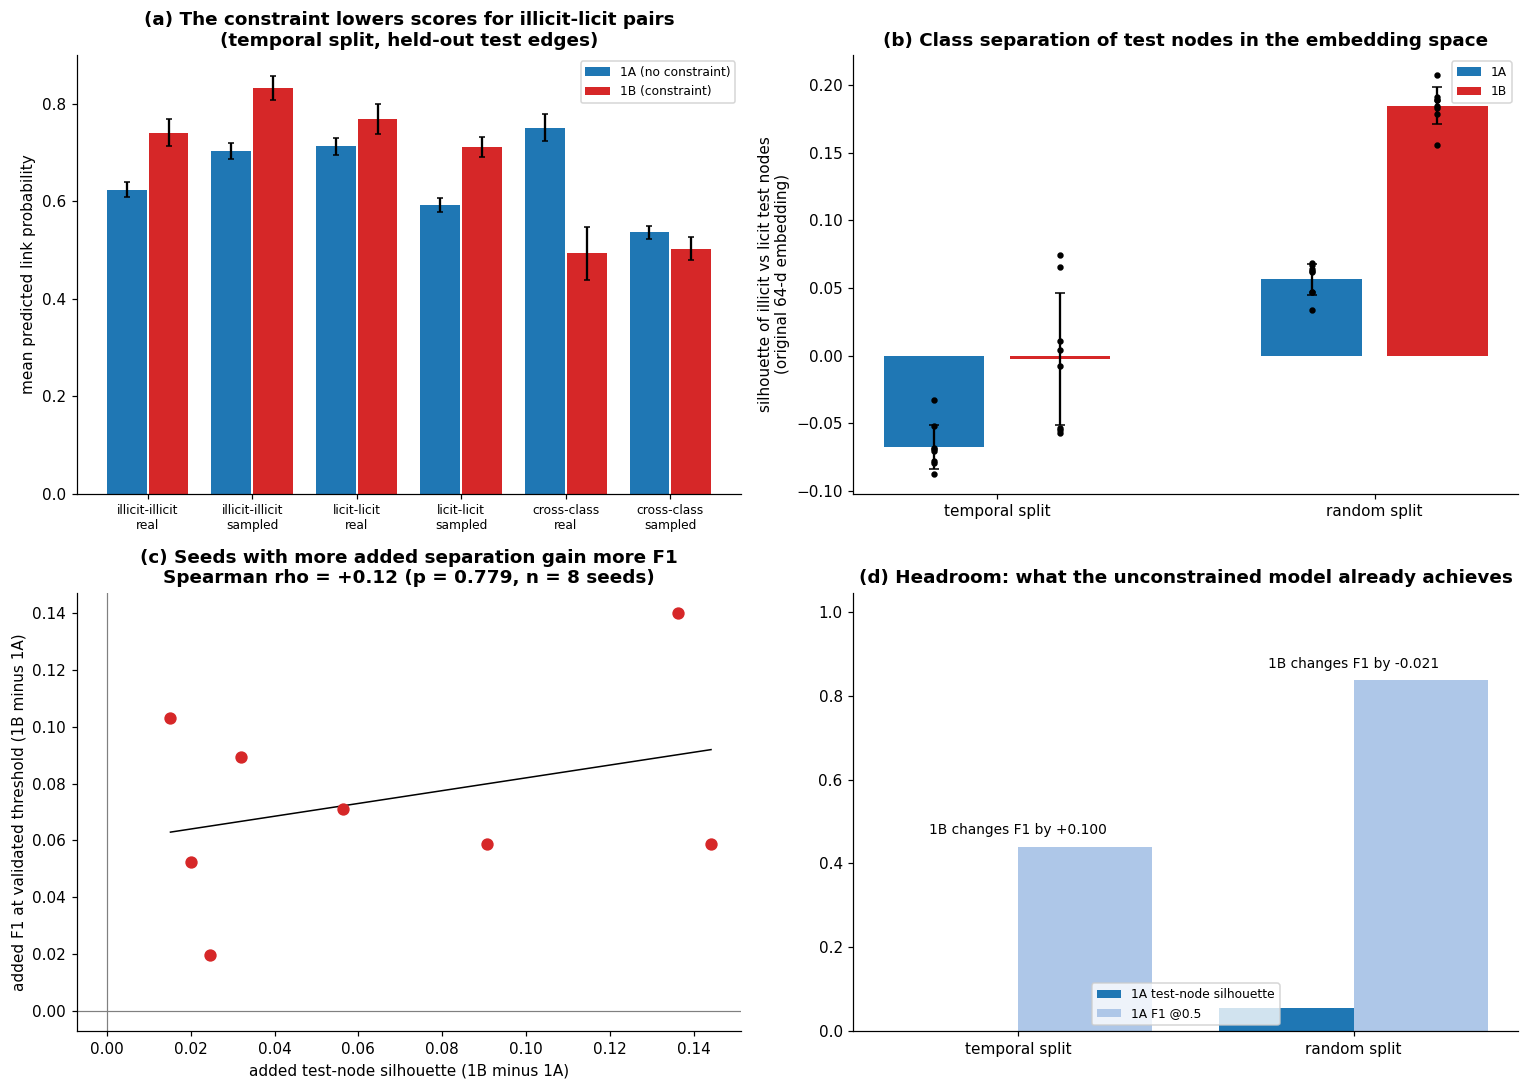

✓ saved fig_mechanism.png

Mechanism summary (numbers only, no interpretation):
  temporal  1A silhouette(test)=-0.067  1A F1@0.5=0.440  1B-1A F1@0.5=+0.100
  random    1A silhouette(test)=0.056  1A F1@0.5=0.836  1B-1A F1@0.5=-0.021
  Spearman rho (added separation vs added F1, temporal, per seed): +0.119  p=0.779  (n=8; read as supporting, not conclusive)


In [42]:
# ═══════════════════════════════════════════════════════════════════════════
# MECHANISM: why does the constraint behave as it does?
# Three testable links in the explanation:
#   (a) the constraint lowers link scores for illicit-licit pairs      -> suppression, per seed
#   (b) that pushes illicit and licit embeddings apart in the shared space -> separation, per seed
#   (c) more separation goes with better classification where there is room to gain
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("MECHANISM ANALYSIS")
print("=" * 70)
def sd_of(R, path):
    out = []
    for r in R:
        v = r
        for p in path: v = v[p]
        out.append(v)
    return out

mech_rows = []
def add_row(split, metric, path, higher_is='better'):
    A = sd_of(mech[split]['1A'], path); B = sd_of(mech[split]['1B'], path)
    st = paired_stats(B, A)
    mech_rows.append({'split': split, 'metric': metric, '1A mean': np.mean(A), '1B mean': np.mean(B), 'diff (1B-1A)': st['mean_diff'],
                      'ci_lo': st['ci_lo'], 'ci_hi': st['ci_hi'], 'seeds 1B higher': f"{st['wins']}/{st['n']}", 'wilcoxon p': st['w_p']})
for split in ('temporal', 'random'):
    add_row(split, 'constraint reduction (test edges)', ['reduction'])
    add_row(split, 'silhouette, training nodes', ['sep_train', 'silhouette'])
    add_row(split, 'silhouette, test nodes', ['sep_test', 'silhouette'])
    add_row(split, 'separation ratio, training nodes', ['sep_train', 'separation_ratio'])
    add_row(split, 'separation ratio, test nodes', ['sep_test', 'separation_ratio'])
    add_row(split, 'link AUC (held-out edges)', ['ev', 'link_auc'])
    add_row(split, 'F1 on illicit class @0.5', ['tuned', 'f1_default'])
mech_df = pd.DataFrame(mech_rows)
save_table(mech_df.round(4), 'table_mechanism')

# ── Figure: what the constraint does to link scores and to the embedding ──
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
cats = [('ii_real', 'illicit-illicit\nreal'), ('ii_neg', 'illicit-illicit\nsampled'), ('ll_real', 'licit-licit\nreal'),
        ('ll_neg', 'licit-licit\nsampled'), ('cc_real', 'cross-class\nreal'), ('cc_neg', 'cross-class\nsampled')]
for k, (nm, off) in enumerate((('1A', -0.2), ('1B', 0.2))):
    vals = [[r['edge_means'][c] for r in mech['temporal'][nm]] for c, _ in cats]
    ax[0, 0].bar(np.arange(len(cats)) + off, [np.nanmean(v) for v in vals], 0.38, yerr=[np.nanstd(v) for v in vals],
                 color=PALETTE[nm], label={'1A': '1A (no constraint)', '1B': '1B (constraint)'}[nm], capsize=2)
ax[0, 0].set_xticks(range(len(cats))); ax[0, 0].set_xticklabels([l for _, l in cats], fontsize=8)
ax[0, 0].set_ylabel('mean predicted link probability'); ax[0, 0].legend(fontsize=8)
ax[0, 0].set_title('(a) The constraint lowers scores for illicit-licit pairs\n(temporal split, held-out test edges)')

for k, (nm, off) in enumerate((('1A', 0), ('1B', 1))):
    for split, base_x in (('temporal', 0), ('random', 3)):
        v = sd_of(mech[split][nm], ['sep_test', 'silhouette'])
        ax[0, 1].bar(base_x + off, np.mean(v), 0.8, yerr=np.std(v), color=PALETTE[nm], capsize=3, label=nm if base_x == 0 else None)
        ax[0, 1].scatter(np.full(len(v), base_x + off), v, color='black', s=10, zorder=3)
ax[0, 1].set_xticks([0.5, 3.5]); ax[0, 1].set_xticklabels(['temporal split', 'random split'])
ax[0, 1].set_ylabel('silhouette of illicit vs licit test nodes\n(original 64-d embedding)'); ax[0, 1].legend(fontsize=8)
ax[0, 1].set_title('(b) Class separation of test nodes in the embedding space')

dsep = np.array(sd_of(mech['temporal']['1B'], ['sep_test', 'silhouette'])) - np.array(sd_of(mech['temporal']['1A'], ['sep_test', 'silhouette']))
df1  = np.array(sd_of(mech['temporal']['1B'], ['tuned', 'f1'])) - np.array(sd_of(mech['temporal']['1A'], ['tuned', 'f1']))
ax[1, 0].scatter(dsep, df1, color=PALETTE['1B'], s=50, zorder=3)
if len(dsep) > 2 and np.std(dsep) > 0:
    rho, rho_p = spearmanr(dsep, df1); slope, icpt = np.polyfit(dsep, df1, 1)
    xs = np.linspace(dsep.min(), dsep.max(), 20); ax[1, 0].plot(xs, slope * xs + icpt, color='black', lw=1)
    ttl = f"(c) Seeds with more added separation gain more F1\nSpearman rho = {rho:+.2f} (p = {rho_p:.3f}, n = {len(dsep)} seeds)"
else:
    rho, rho_p, ttl = np.nan, np.nan, '(c) Added separation against F1 gain'
ax[1, 0].axhline(0, color='grey', lw=0.8); ax[1, 0].axvline(0, color='grey', lw=0.8)
ax[1, 0].set_xlabel('added test-node silhouette (1B minus 1A)'); ax[1, 0].set_ylabel('added F1 at validated threshold (1B minus 1A)'); ax[1, 0].set_title(ttl)

# (d) headroom: separation the unconstrained model already has, per protocol, with its F1
heads = []
for split in ('temporal', 'random'):
    sil = np.mean(sd_of(mech[split]['1A'], ['sep_test', 'silhouette'])); f1_ = np.mean(sd_of(mech[split]['1A'], ['tuned', 'f1_default']))
    gain = np.mean(sd_of(mech[split]['1B'], ['tuned', 'f1_default'])) - f1_
    heads.append((split, sil, f1_, gain))
xs_ = np.arange(2)
ax[1, 1].bar(xs_ - 0.2, [h[1] for h in heads], 0.4, color=PALETTE['1A'], label='1A test-node silhouette')
ax[1, 1].bar(xs_ + 0.2, [h[2] for h in heads], 0.4, color='#aec7e8', label='1A F1 @0.5')
for i, h in enumerate(heads): ax[1, 1].text(i, max(h[1], h[2]) + 0.03, f"1B changes F1 by {h[3]:+.3f}", ha='center', fontsize=9)
ax[1, 1].set_ylim(0, max(max(h[1], h[2]) for h in heads) * 1.25)
ax[1, 1].set_xticks(xs_); ax[1, 1].set_xticklabels([h[0] + ' split' for h in heads]); ax[1, 1].legend(fontsize=8, loc='lower center')
ax[1, 1].set_title('(d) Headroom: what the unconstrained model already achieves')
save_fig('fig_mechanism.png')

mechanism_summary = {'spearman_rho_dsep_vs_df1_temporal': float(rho), 'spearman_p': float(rho_p),
                     'headroom': {h[0]: {'1A_test_silhouette': float(h[1]), '1A_f1_at_0.5': float(h[2]), '1B_minus_1A_f1_at_0.5': float(h[3])} for h in heads}}
print("\nMechanism summary (numbers only, no interpretation):")
for h in heads: print(f"  {h[0]:<9} 1A silhouette(test)={h[1]:.3f}  1A F1@0.5={h[2]:.3f}  1B-1A F1@0.5={h[3]:+.3f}")
print(f"  Spearman rho (added separation vs added F1, temporal, per seed): {rho:+.3f}  p={rho_p:.3f}  (n={len(dsep)}; read as supporting, not conclusive)")


## 27. Lambda Sensitivity on the Temporal Split

The constraint weight was fixed in advance. This repeats the comparison for other weights over eight seeds and judges them on validation data.

TEMPORAL LAMBDA SENSITIVITY (lambda = 1.0 reuses the mechanism runs)

✓ lambda=0.1 seed=42 | 27.6s | Best val: 0.7912

✓ lambda=0.1 seed=1042 | 22.1s | Best val: 0.7618

✓ lambda=0.1 seed=2042 | 27.8s | Best val: 0.8009

✓ lambda=0.1 seed=3042 | 23.4s | Best val: 0.7773

✓ lambda=0.1 seed=4042 | 28.8s | Best val: 0.7650

✓ lambda=0.1 seed=5042 | 24.1s | Best val: 0.7710

✓ lambda=0.1 seed=6042 | 30.9s | Best val: 0.7817

✓ lambda=0.1 seed=7042 | 31.3s | Best val: 0.7982
done lambda=0.1

✓ lambda=0.5 seed=42 | 25.3s | Best val: 0.7567

✓ lambda=0.5 seed=1042 | 24.5s | Best val: 0.7496

✓ lambda=0.5 seed=2042 | 26.4s | Best val: 0.7788

✓ lambda=0.5 seed=3042 | 32.9s | Best val: 0.7712

✓ lambda=0.5 seed=4042 | 34.7s | Best val: 0.7640

✓ lambda=0.5 seed=5042 | 34.4s | Best val: 0.7761

✓ lambda=0.5 seed=6042 | 30.6s | Best val: 0.7736

✓ lambda=0.5 seed=7042 | 33.7s | Best val: 0.7801
done lambda=0.5

✓ lambda=2.0 seed=42 | 29.8s | Best val: 0.7595

✓ lambda=2.0 seed=1042 | 25.3s | Best

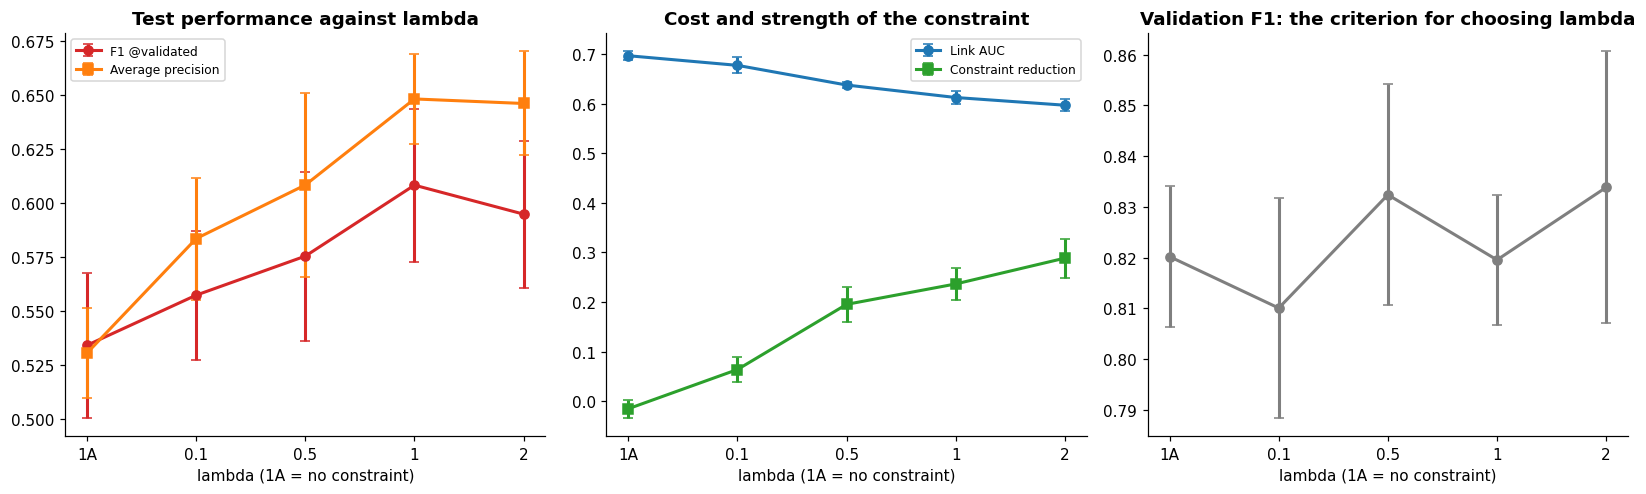

✓ saved fig_lambda_temporal.png


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 331 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


In [43]:
# ═══════════════════════════════════════════════════════════════════════════
# LAMBDA SENSITIVITY ON THE TEMPORAL SPLIT (eight seeds), judged on validation data
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("TEMPORAL LAMBDA SENSITIVITY (lambda = 1.0 reuses the mechanism runs)")
print("=" * 70)
LAMBDA_GRID = [0.1, 2.0] if DRY_RUN else [0.1, 0.5, 2.0]
lam_results = {0.0: mech['temporal']['1A'], float(LAMBDA): mech['temporal']['1B']}
for lam in LAMBDA_GRID:
    lam_results[lam] = [run_dual(data_temporal, sd, True, lam=lam, label=f"lambda={lam} seed={sd}") for sd in SEEDS_LIST_H]
    print(f"done lambda={lam}", flush=True)

def best_val_f1(r):
    p, rc, _ = precision_recall_curve(r['val_y'], r['val_p'])
    return float(np.max(2 * p[:-1] * rc[:-1] / (p[:-1] + rc[:-1] + 1e-12)))
lams = sorted(lam_results)
lam_rows = []
for lam in lams:
    R = lam_results[lam]
    lam_rows.append({'lambda': lam, 'F1 @validated (test)': ms([r['tuned']['f1'] for r in R]), 'Average precision (test)': ms([r['tuned']['ap'] for r in R]),
                     'Link AUC (test)': ms([r['ev']['link_auc'] for r in R]), 'Constraint reduction': ms([r['reduction'] for r in R]),
                     'Best validation F1': ms([best_val_f1(r) for r in R])})
lam_df = pd.DataFrame(lam_rows); lam_df.loc[lam_df['lambda'] == 0.0, 'lambda'] = 0.0
save_table(lam_df, 'table_lambda_temporal')
val_by_lam = {lam: float(np.mean([best_val_f1(r) for r in lam_results[lam]])) for lam in lams if lam > 0}
chosen = max(val_by_lam, key=val_by_lam.get)
print(f"\nLambda with the highest mean VALIDATION F1: {chosen}  (the thesis fixed lambda = {LAMBDA} in advance)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
def line(a_, getter, label, color, marker='o'):
    mu = [np.mean([getter(r) for r in lam_results[l]]) for l in lams]; sd_ = [np.std([getter(r) for r in lam_results[l]]) for l in lams]
    a_.errorbar(range(len(lams)), mu, yerr=sd_, marker=marker, color=color, label=label, capsize=3, lw=2)
xt = [('1A' if l == 0 else f'{l:g}') for l in lams]
line(ax[0], lambda r: r['tuned']['f1'], 'F1 @validated', '#d62728'); line(ax[0], lambda r: r['tuned']['ap'], 'Average precision', '#ff7f0e', 's')
ax[0].set_title('Test performance against lambda'); ax[0].legend(fontsize=8)
line(ax[1], lambda r: r['ev']['link_auc'], 'Link AUC', '#1f77b4'); line(ax[1], lambda r: r['reduction'], 'Constraint reduction', '#2ca02c', 's')
ax[1].set_title('Cost and strength of the constraint'); ax[1].legend(fontsize=8)
line(ax[2], best_val_f1, 'Best validation F1', '#7f7f7f'); ax[2].set_title('Validation F1: the criterion for choosing lambda')
for a_ in ax:
    a_.set_xticks(range(len(lams))); a_.set_xticklabels(xt); a_.set_xlabel('lambda (1A = no constraint)')
save_fig('fig_lambda_temporal.png')
lambda_summary = {'chosen_by_validation': float(chosen), 'fixed_a_priori': float(LAMBDA),
                  'by_lambda': {str(l): {'f1': float(np.mean([r['tuned']['f1'] for r in lam_results[l]])), 'ap': float(np.mean([r['tuned']['ap'] for r in lam_results[l]])),
                                          'link_auc': float(np.mean([r['ev']['link_auc'] for r in lam_results[l]]))} for l in lams}}

save_checkpoint()


### Dose-response across lambda

Does performance, and class separation, change with the constraint weight? This reuses the lambda runs above and pools every (lambda, seed) pair.

DOSE-RESPONSE ACROSS LAMBDA

table_dose_response
 lambda        reduction       sil_train         sil_test              f1              ap        link_auc
    0.0 -0.0149 ± 0.0184 0.1618 ± 0.0091 -0.0674 ± 0.0163 0.5341 ± 0.0336 0.5305 ± 0.0208 0.6966 ± 0.0085
    0.1  0.0642 ± 0.0261 0.1930 ± 0.0112 -0.0645 ± 0.0220 0.5573 ± 0.0299 0.5835 ± 0.0283 0.6771 ± 0.0162
    0.5  0.1955 ± 0.0359 0.2804 ± 0.0158 -0.0075 ± 0.0521 0.5754 ± 0.0391 0.6083 ± 0.0424 0.6375 ± 0.0065
    1.0  0.2366 ± 0.0318 0.3042 ± 0.0150 -0.0025 ± 0.0491 0.6082 ± 0.0354 0.6481 ± 0.0208 0.6123 ± 0.0134
    2.0  0.2886 ± 0.0392 0.3070 ± 0.0255  0.0005 ± 0.0480 0.5948 ± 0.0340 0.6460 ± 0.0241 0.5968 ± 0.0119
✓ saved tables/table_dose_response.csv

Spearman correlations over all 40 (lambda, seed) runs (numbers only):
  reduction_vs_f1                  rho = +0.593  p = 0.0001
  sil_test_vs_f1                   rho = +0.234  p = 0.1456
  sil_train_vs_f1                  rho = +0.645  p = 0.0000
  sil_test_vs_ap         

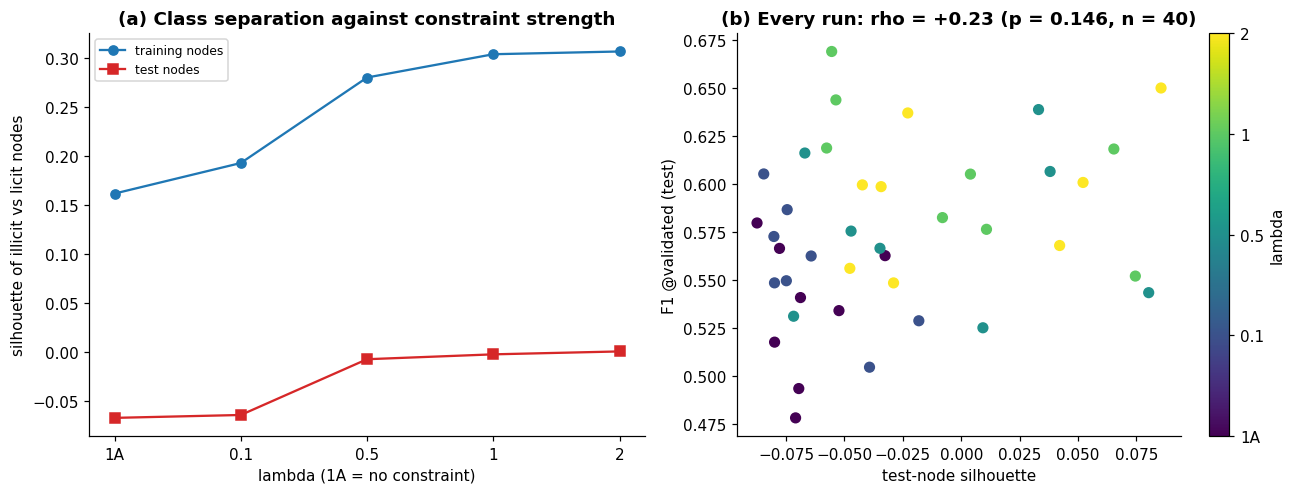

✓ saved fig_dose_response.png


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 338 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


In [44]:
# ═══════════════════════════════════════════════════════════════════════════
# DOSE-RESPONSE: does more constraint strength go with more separation and better F1?
# Uses the lambda runs above (no new training). Pools every (lambda, seed) pair, which has far more
# power than the eight-seed correlation, and also looks at seed-to-seed variation at a fixed lambda.
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("DOSE-RESPONSE ACROSS LAMBDA")
print("=" * 70)
dr_rows = []
for lam in sorted(lam_results):
    for r in lam_results[lam]:
        dr_rows.append({'lambda': lam, 'reduction': r['reduction'], 'sil_train': r['sep_train']['silhouette'], 'sil_test': r['sep_test']['silhouette'],
                        'f1': r['tuned']['f1'], 'ap': r['tuned']['ap'], 'link_auc': r['ev']['link_auc']})
dr = pd.DataFrame(dr_rows)
dr_out = pd.DataFrame({'lambda': sorted(lam_results)})
for c_ in ('reduction', 'sil_train', 'sil_test', 'f1', 'ap', 'link_auc'):
    dr_out[c_] = [f"{dr[dr['lambda'] == l][c_].mean():.4f} ± {dr[dr['lambda'] == l][c_].std(ddof=0):.4f}" for l in dr_out['lambda']]
save_table(dr_out, 'table_dose_response')
dr['sil_test_within'] = dr['sil_test'] - dr.groupby('lambda')['sil_test'].transform('mean')
dr['f1_within'] = dr['f1'] - dr.groupby('lambda')['f1'].transform('mean')
dose_summary = {'n_pairs': int(len(dr))}
for key, (x, y) in {'reduction_vs_f1': ('reduction', 'f1'), 'sil_test_vs_f1': ('sil_test', 'f1'), 'sil_train_vs_f1': ('sil_train', 'f1'),
                    'sil_test_vs_ap': ('sil_test', 'ap'), 'sil_test_within_vs_f1_within': ('sil_test_within', 'f1_within')}.items():
    rho, p = spearmanr(dr[x], dr[y]); dose_summary[key] = {'rho': float(rho), 'p': float(p)}
print(f"\nSpearman correlations over all {len(dr)} (lambda, seed) runs (numbers only):")
for k, v in dose_summary.items():
    if k != 'n_pairs': print(f"  {k:<32} rho = {v['rho']:+.3f}  p = {v['p']:.4f}")
print("  'within' removes each lambda's mean first, so it looks only at seed-to-seed variation at a fixed lambda")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
lams_ = sorted(lam_results); xl = [('1A' if l == 0 else f'{l:g}') for l in lams_]
ax[0].plot(range(len(lams_)), [dr[dr['lambda'] == l].sil_train.mean() for l in lams_], 'o-', color='#1f77b4', label='training nodes')
ax[0].plot(range(len(lams_)), [dr[dr['lambda'] == l].sil_test.mean() for l in lams_], 's-', color='#d62728', label='test nodes')
ax[0].set_xticks(range(len(lams_))); ax[0].set_xticklabels(xl); ax[0].set_xlabel('lambda (1A = no constraint)')
ax[0].set_ylabel('silhouette of illicit vs licit nodes'); ax[0].set_title('(a) Class separation against constraint strength'); ax[0].legend(fontsize=8)
sc = ax[1].scatter(dr.sil_test, dr.f1, c=[lams_.index(l) for l in dr['lambda']], cmap='viridis', s=40)
cb = plt.colorbar(sc, ax=ax[1]); cb.set_ticks(range(len(lams_))); cb.set_ticklabels(xl); cb.set_label('lambda')
ax[1].set_xlabel('test-node silhouette'); ax[1].set_ylabel('F1 @validated (test)')
ax[1].set_title(f"(b) Every run: rho = {dose_summary['sil_test_vs_f1']['rho']:+.2f} (p = {dose_summary['sil_test_vs_f1']['p']:.3f}, n = {len(dr)})")
save_fig('fig_dose_response.png')
save_checkpoint()


## 28. Rolling Temporal Folds

Two earlier training and test periods, in addition to the main split, to check that the result is not specific to one test window.

ROLLING TEMPORAL FOLDS
fold A (train 1-19, test 25-34): train 17,989 labelled (1,511 illicit) | val 5,617 labelled (708 illicit) | test 6,288 labelled (1,243 illicit)

✓ fold A (train 1-19, test 25-34) 1A 42 | 33.5s | Best val: 0.7990

✓ fold A (train 1-19, test 25-34) 1A 1042 | 24.6s | Best val: 0.7941

✓ fold A (train 1-19, test 25-34) 1A 2042 | 24.5s | Best val: 0.7924

✓ fold A (train 1-19, test 25-34) 1A 3042 | 24.6s | Best val: 0.7955

✓ fold A (train 1-19, test 25-34) 1A 4042 | 25.4s | Best val: 0.7919

✓ fold A (train 1-19, test 25-34) 1A 5042 | 24.4s | Best val: 0.7889

✓ fold A (train 1-19, test 25-34) 1A 6042 | 32.7s | Best val: 0.7999

✓ fold A (train 1-19, test 25-34) 1A 7042 | 30.4s | Best val: 0.7934

✓ fold A (train 1-19, test 25-34) 1B 42 | 28.1s | Best val: 0.7432

✓ fold A (train 1-19, test 25-34) 1B 1042 | 28.9s | Best val: 0.7502

✓ fold A (train 1-19, test 25-34) 1B 2042 | 24.7s | Best val: 0.7290

✓ fold A (train 1-19, test 25-34) 1B 3042 | 21.9s | Best val: 0.74

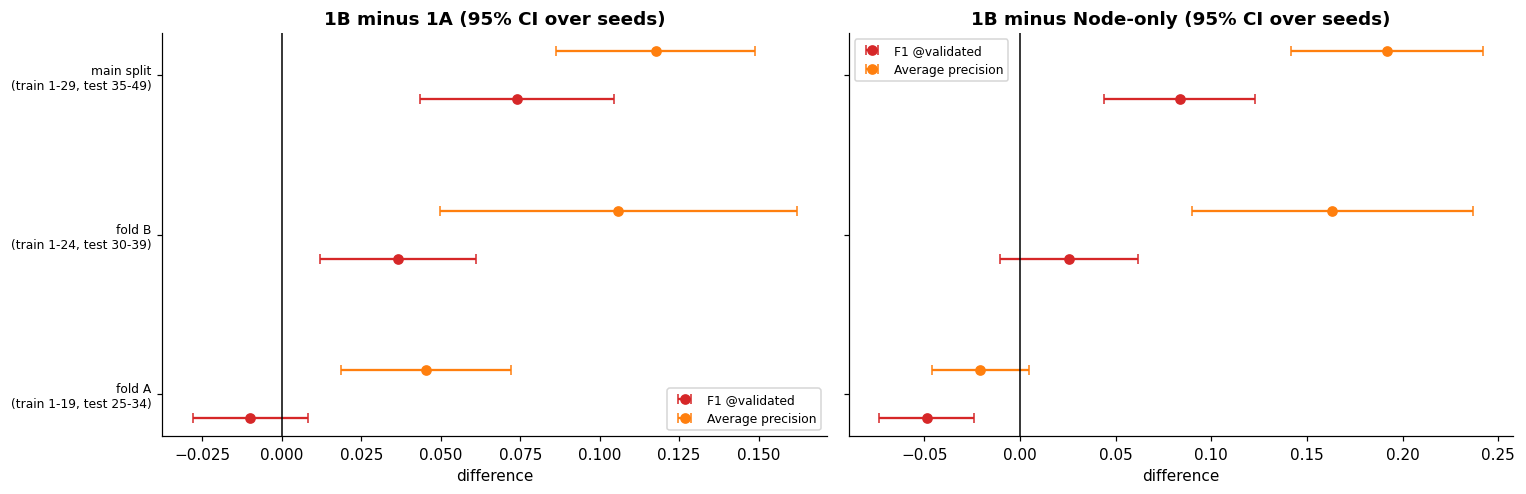

✓ saved fig_rolling_folds.png


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 355 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


In [45]:
# ═══════════════════════════════════════════════════════════════════════════
# ROLLING TEMPORAL FOLDS: is the result specific to one test window?
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("ROLLING TEMPORAL FOLDS")
print("=" * 70)
FOLDS = [('fold A (train 1-19, test 25-34)', 19, 24, 34), ('fold B (train 1-24, test 30-39)', 24, 29, 39)]
fold_results = {}
for k, (name, trm, vam, tem) in enumerate(FOLDS):
    d_f = build_temporal_fold(trm, vam, tem, offset=10 * k)
    y_ = d_f.y.cpu().numpy()
    cnt = lambda m: f"{int(m.sum()):,} labelled ({int((y_[m.numpy()] == 1).sum()):,} illicit)"
    print(f"{name}: train {cnt(d_f.train_mask)} | val {cnt(d_f.val_mask)} | test {cnt(d_f.test_mask)}")
    fold_results[name] = {'Node-only': [run_node_only(d_f, sd) for sd in SEEDS_LIST_H],
                          '1A': [run_dual(d_f, sd, False, label=f"{name} 1A {sd}") for sd in SEEDS_LIST_H],
                          '1B': [run_dual(d_f, sd, True,  label=f"{name} 1B {sd}") for sd in SEEDS_LIST_H]}
    fold_results[name]['Random forest'] = run_feature_baselines(d_f, SEEDS_LIST_H, tag=name)['Random forest']
    del d_f
fold_results['main split (train 1-29, test 35-49)'] = {'Node-only': mech['temporal']['Node-only'], '1A': mech['temporal']['1A'],
                                                        '1B': mech['temporal']['1B'], 'Random forest': feature_baseline_results['temporal']['Random forest']}
fold_names = list(fold_results)
def f1_of(rec): return rec['tuned']['f1'] if 'tuned' in rec else rec['tuned_f1']
def ap_of(rec): return rec['tuned']['ap'] if 'tuned' in rec else rec['ap']
fold_rows, fold_pairs = [], []
for fn_ in fold_names:
    F_ = fold_results[fn_]
    for nm in ('Node-only', '1A', '1B', 'Random forest'):
        fold_rows.append({'Fold': fn_, 'Model': nm, 'F1 @validated': ms([f1_of(r) for r in F_[nm]]), 'Average precision': ms([ap_of(r) for r in F_[nm]])})
    for comp, A, B in (('1B minus 1A', '1B', '1A'), ('1B minus Node-only', '1B', 'Node-only')):
        for lab, g in (('F1 @validated', f1_of), ('Average precision', ap_of)):
            st = paired_stats([g(r) for r in F_[A]], [g(r) for r in F_[B]]); st.update({'fold': fn_, 'comparison': comp, 'metric': lab}); fold_pairs.append(st)
save_table(pd.DataFrame(fold_rows), 'table_rolling_folds')
fold_pairs_df = pd.DataFrame(fold_pairs)
save_table(fold_pairs_df[['fold', 'comparison', 'metric', 'mean_diff', 'ci_lo', 'ci_hi', 'wins', 'n', 'w_p']].round(4), 'table_rolling_folds_paired')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for a_, comp in zip(ax, ('1B minus 1A', '1B minus Node-only')):
    for j, lab in enumerate(('F1 @validated', 'Average precision')):
        sub = fold_pairs_df[(fold_pairs_df.comparison == comp) & (fold_pairs_df.metric == lab)].reset_index(drop=True)
        ypos = np.arange(len(sub)) + (j - 0.5) * 0.3
        a_.errorbar(sub.mean_diff, ypos, xerr=[sub.mean_diff - sub.ci_lo, sub.ci_hi - sub.mean_diff], fmt='o', color=['#d62728', '#ff7f0e'][j], capsize=3, label=lab)
    a_.axvline(0, color='black', lw=1); a_.set_yticks(range(len(fold_names))); a_.set_yticklabels([f.split(' (')[0] + '\n(' + f.split(' (')[1] if ' (' in f else f for f in fold_names], fontsize=8)
    a_.set_title(f'{comp} (95% CI over seeds)'); a_.set_xlabel('difference'); a_.legend(fontsize=8)
save_fig('fig_rolling_folds.png')

save_checkpoint()


## 29. Pipeline Audit: Effect of Each Flaw

Each flaw found during the audit is put back into the final pipeline one at a time, and then all together, to measure what it does to the headline result. Reduce `FLAW_SEEDS` if GPU time is short.

PIPELINE AUDIT: EFFECT OF EACH FLAW

✓ F1 1A 42 | 29.8s | Best val: 0.7961

✓ F1 1A 1042 | 31.0s | Best val: 0.7966

✓ F1 1A 2042 | 19.8s | Best val: 0.7826

✓ F1 1A 3042 | 27.8s | Best val: 0.7931

✓ F1 1A 4042 | 34.1s | Best val: 0.7823

✓ F1 1A 5042 | 25.6s | Best val: 0.7765

✓ F1 1A 6042 | 24.6s | Best val: 0.7846

✓ F1 1A 7042 | 22.0s | Best val: 0.7818

✓ F1 1B 42 | 34.4s | Best val: 0.7619

✓ F1 1B 1042 | 26.2s | Best val: 0.7526

✓ F1 1B 2042 | 21.5s | Best val: 0.7428

✓ F1 1B 3042 | 29.4s | Best val: 0.7547

✓ F1 1B 4042 | 34.1s | Best val: 0.7650

✓ F1 1B 5042 | 34.5s | Best val: 0.7561

✓ F1 1B 6042 | 23.2s | Best val: 0.7475

✓ F1 1B 7042 | 27.0s | Best val: 0.7519
done: flaw 1

✓ F2 1A 42 | 17.4s | Best val: 0.6536

✓ F2 1A 1042 | 17.1s | Best val: 0.6677

✓ F2 1A 2042 | 17.0s | Best val: 0.6585

✓ F2 1A 3042 | 17.2s | Best val: 0.6567

✓ F2 1A 4042 | 17.2s | Best val: 0.6241

✓ F2 1A 5042 | 25.8s | Best val: 0.6293

✓ F2 1A 6042 | 19.4s | Best val: 0.5963

✓ F2 1A 7042 

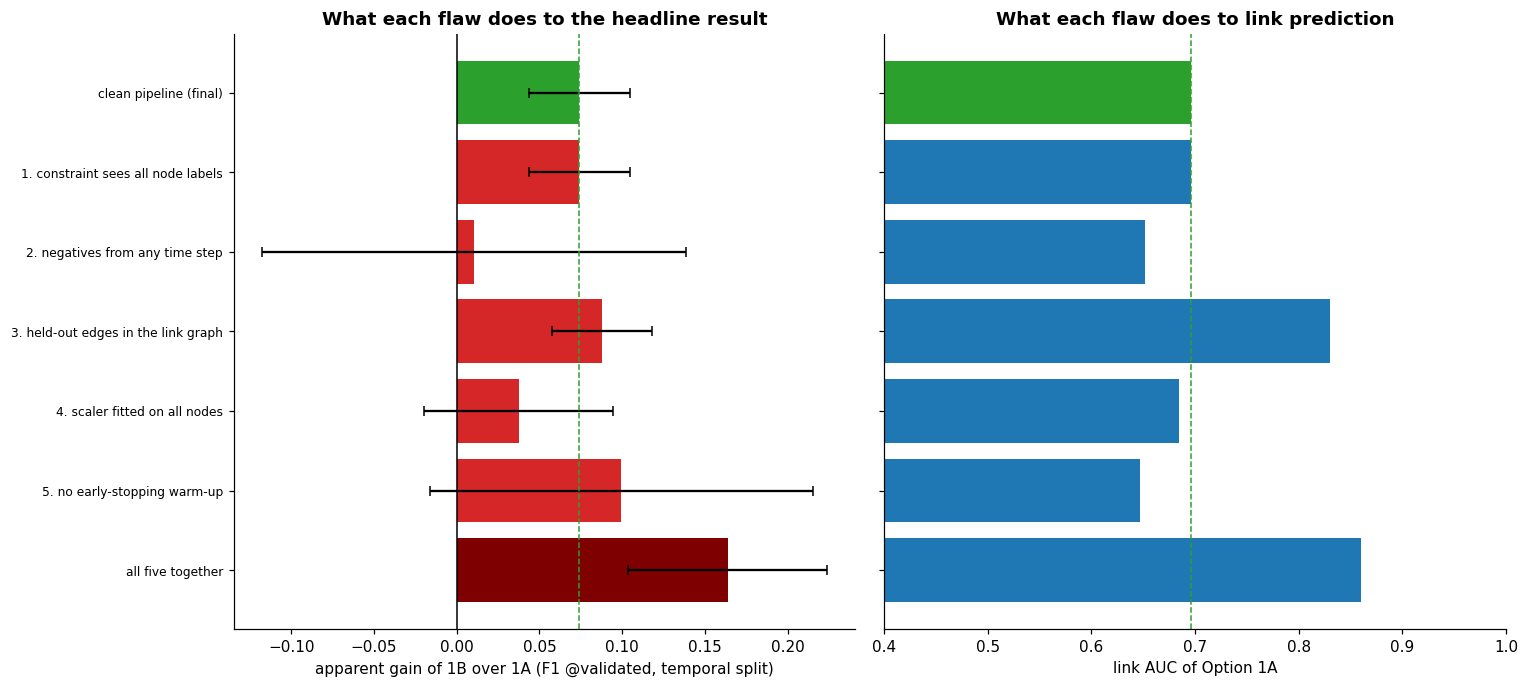

✓ saved fig_pipeline_audit.png


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 358 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


In [46]:
# ═══════════════════════════════════════════════════════════════════════════
# PIPELINE AUDIT, WITH PROOF: re-introduce each flaw I found and measure what it does.
# Each variant changes ONE thing in the final pipeline (temporal split, eight seeds, 1A and 1B).
# ═══════════════════════════════════════════════════════════════════════════
from torch_geometric.utils import negative_sampling
print("=" * 70)
print("PIPELINE AUDIT: EFFECT OF EACH FLAW")
print("=" * 70)
FLAW_SEEDS = SEEDS_LIST_H           # reduce (for example SEEDS_LIST_H[:4]) if GPU time is short

def train_1b_leaky_labels(model, data, optimizer, alpha, lam, device):
    """Option 1B exactly as the final code, except the constraint sees the labels of ALL nodes."""
    model.train(); optimizer.zero_grad()
    node_pred, link_pred, cross_mask = model.forward_with_constraint(
        data.x.to(device), data.edge_index.to(device), data.train_edge_label_index.to(device), data.y.to(device))
    n_loss = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    total_link, bce, cp = constrained_link_loss(link_pred, data.train_edge_label.to(device), cross_mask, lam)
    loss = alpha * n_loss + (1 - alpha) * total_link
    loss.backward(); optimizer.step()
    return {'total': loss.item(), 'node': n_loss.item(), 'link': total_link.item(), 'bce': bce.item(),
            'constraint': float(cp.detach()) if isinstance(cp, torch.Tensor) else cp, 'n_cross': cross_mask.sum().item()}

def variant_data(easy_negatives=False, heldout_in_graph=False, scaler_all=False):
    d0 = data_temporal
    d2 = Data(**d0.to_dict())
    d2.class_weights = d0.class_weights
    d2.val_msg_edge_index, d2.test_msg_edge_index = d0.val_msg_edge_index, d0.test_msg_edge_index
    if easy_negatives:     # negatives from ANY pair of nodes, as in the first version of the pipeline
        for k, part in enumerate(('train', 'val', 'test')):
            eli, el = getattr(d0, f'{part}_edge_label_index'), getattr(d0, f'{part}_edge_label')
            pos = eli[:, el == 1]
            torch.manual_seed(SEED + 301 + k)
            neg = negative_sampling(edge_index, num_nodes=d0.x.shape[0], num_neg_samples=pos.shape[1])
            setattr(d2, f'{part}_edge_label_index', torch.cat([pos, neg], 1))
            setattr(d2, f'{part}_edge_label', torch.cat([torch.ones(pos.shape[1]), torch.zeros(neg.shape[1])]))
        torch.manual_seed(SEED)
    if heldout_in_graph:   # score links on a graph that already contains the edges being scored
        d2.val_msg_edge_index = d2.test_msg_edge_index = d2.full_edge_index
    if scaler_all:         # feature scaler fitted on every node, test period included
        d2.x = torch.tensor((raw_features - raw_features.mean(0)) / (raw_features.std(0) + 1e-8), dtype=torch.float)
    return d2

def run_pair(d_obj, seeds, leaky_labels=False, tag=''):
    A = [run_dual(d_obj, sd, False, label=f"{tag} 1A {sd}") for sd in seeds]
    B = [run_dual(d_obj, sd, True,  label=f"{tag} 1B {sd}", fn_override=(train_1b_leaky_labels if leaky_labels else None)) for sd in seeds]
    return A, B

flaw = {'clean pipeline (final)': (mech['temporal']['1A'][:len(FLAW_SEEDS)], mech['temporal']['1B'][:len(FLAW_SEEDS)])}
d_easy, d_held, d_scal = variant_data(easy_negatives=True), variant_data(heldout_in_graph=True), variant_data(scaler_all=True)
d_all = variant_data(easy_negatives=True, heldout_in_graph=True, scaler_all=True)
flaw['1. constraint sees all node labels'] = (flaw['clean pipeline (final)'][0], run_pair(data_temporal, FLAW_SEEDS, True, 'F1')[1])
print("done: flaw 1", flush=True)
flaw['2. negatives from any time step']   = run_pair(d_easy, FLAW_SEEDS, False, 'F2'); print("done: flaw 2", flush=True)
flaw['3. held-out edges in the link graph'] = run_pair(d_held, FLAW_SEEDS, False, 'F3'); print("done: flaw 3", flush=True)
flaw['4. scaler fitted on all nodes']     = run_pair(d_scal, FLAW_SEEDS, False, 'F4'); print("done: flaw 4", flush=True)
_saved_min = MIN_EPOCHS; MIN_EPOCHS = 0
try:
    flaw['5. no early-stopping warm-up']  = run_pair(data_temporal, FLAW_SEEDS, False, 'F5')
finally:
    MIN_EPOCHS = _saved_min
print("done: flaw 5", flush=True)
_saved_min = MIN_EPOCHS; MIN_EPOCHS = 0
try:
    flaw['all five together']             = run_pair(d_all, FLAW_SEEDS, True, 'ALL')
finally:
    MIN_EPOCHS = _saved_min
print("done: all five", flush=True)
del d_easy, d_held, d_scal, d_all

def audit_report(flaw):
    """Table, figure and summary for whatever variants are in `flaw`."""
    flaw_rows, flaw_stats = [], {}
    for name, (A, B) in flaw.items():
        f1a, f1b = [r['tuned']['f1'] for r in A], [r['tuned']['f1'] for r in B]
        apa, apb = [r['tuned']['ap'] for r in A], [r['tuned']['ap'] for r in B]
        st = paired_stats(f1b, f1a); sta = paired_stats(apb, apa); flaw_stats[name] = st
        flaw_rows.append({'Variant': name, '1A F1 @validated': ms(f1a), '1B F1 @validated': ms(f1b),
                          'Gain of 1B (F1)': f"{st['mean_diff']:+.4f} (CI {st['ci_lo']:+.4f} to {st['ci_hi']:+.4f}), wins {st['wins']}/{st['n']}",
                          'Gain of 1B (AP)': f"{sta['mean_diff']:+.4f}", '1A link AUC': ms([r['ev']['link_auc'] for r in A]),
                          '1B link AUC': ms([r['ev']['link_auc'] for r in B])})
    save_table(pd.DataFrame(flaw_rows), 'table_pipeline_audit')
    names = list(flaw_stats)
    colors = ['#2ca02c' if n.startswith('clean') else ('#7f0000' if n.startswith('all five together') else '#d62728') for n in names]
    fig, ax = plt.subplots(1, 2, figsize=(14, 0.55 * len(names) + 2.5))
    g = [flaw_stats[n]['mean_diff'] for n in names]
    err = [[flaw_stats[n]['mean_diff'] - flaw_stats[n]['ci_lo'] for n in names], [flaw_stats[n]['ci_hi'] - flaw_stats[n]['mean_diff'] for n in names]]
    ax[0].barh(range(len(names)), g, xerr=err, color=colors, capsize=3)
    ax[0].axvline(g[0], color='#2ca02c', ls='--', lw=1); ax[0].axvline(0, color='black', lw=1)
    ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names, fontsize=8); ax[0].invert_yaxis()
    ax[0].set_xlabel('apparent gain of 1B over 1A (F1 @validated, temporal split)'); ax[0].set_title('What each flaw does to the headline result')
    la = [np.mean([r['ev']['link_auc'] for r in flaw[n][0]]) for n in names]
    ax[1].barh(range(len(names)), la, color=['#2ca02c' if c == '#2ca02c' else '#1f77b4' for c in colors]); ax[1].axvline(la[0], color='#2ca02c', ls='--', lw=1)
    ax[1].set_yticks(range(len(names))); ax[1].set_yticklabels([]); ax[1].invert_yaxis(); ax[1].set_xlim(0.4, 1.0)
    ax[1].set_xlabel('link AUC of Option 1A'); ax[1].set_title('What each flaw does to link prediction')
    save_fig('fig_pipeline_audit.png')
    summ = {n: {'gain_f1': float(s['mean_diff']), 'ci': [float(s['ci_lo']), float(s['ci_hi'])]} for n, s in flaw_stats.items()}
    summ['link_auc_1A'] = {n: float(np.mean([r['ev']['link_auc'] for r in flaw[n][0]])) for n in names}
    return summ

audit_summary = audit_report(flaw)
save_checkpoint()


### Flaw interaction checks

Two extra variants test why leaking labels did nothing on its own in the single-flaw runs, then the audit table and figure are rebuilt.

FLAW INTERACTION CHECKS

✓ F1+F2 1B 42 | 35.9s | Best val: 0.6571

✓ F1+F2 1B 1042 | 22.2s | Best val: 0.6651

✓ F1+F2 1B 2042 | 21.0s | Best val: 0.6798

✓ F1+F2 1B 3042 | 20.8s | Best val: 0.6527

✓ F1+F2 1B 4042 | 35.8s | Best val: 0.7585

✓ F1+F2 1B 5042 | 35.5s | Best val: 0.7151

✓ F1+F2 1B 6042 | 35.9s | Best val: 0.7090

✓ F1+F2 1B 7042 | 18.2s | Best val: 0.6816
done: flaws 1+2

✓ ALL-but-1 1B 42 | 26.5s | Best val: 0.8064

✓ ALL-but-1 1B 1042 | 18.6s | Best val: 0.8027

✓ ALL-but-1 1B 2042 | 4.8s | Best val: 0.7228

✓ ALL-but-1 1B 3042 | 18.3s | Best val: 0.8033

✓ ALL-but-1 1B 4042 | 18.2s | Best val: 0.7866

✓ ALL-but-1 1B 5042 | 24.0s | Best val: 0.8014

✓ ALL-but-1 1B 6042 | 4.3s | Best val: 0.7314

✓ ALL-but-1 1B 7042 | 24.0s | Best val: 0.8058
done: all five except flaw 1

table_pipeline_audit
                                         Variant 1A F1 @validated 1B F1 @validated                           Gain of 1B (F1) Gain of 1B (AP)     1A link AUC     1B link AUC
      

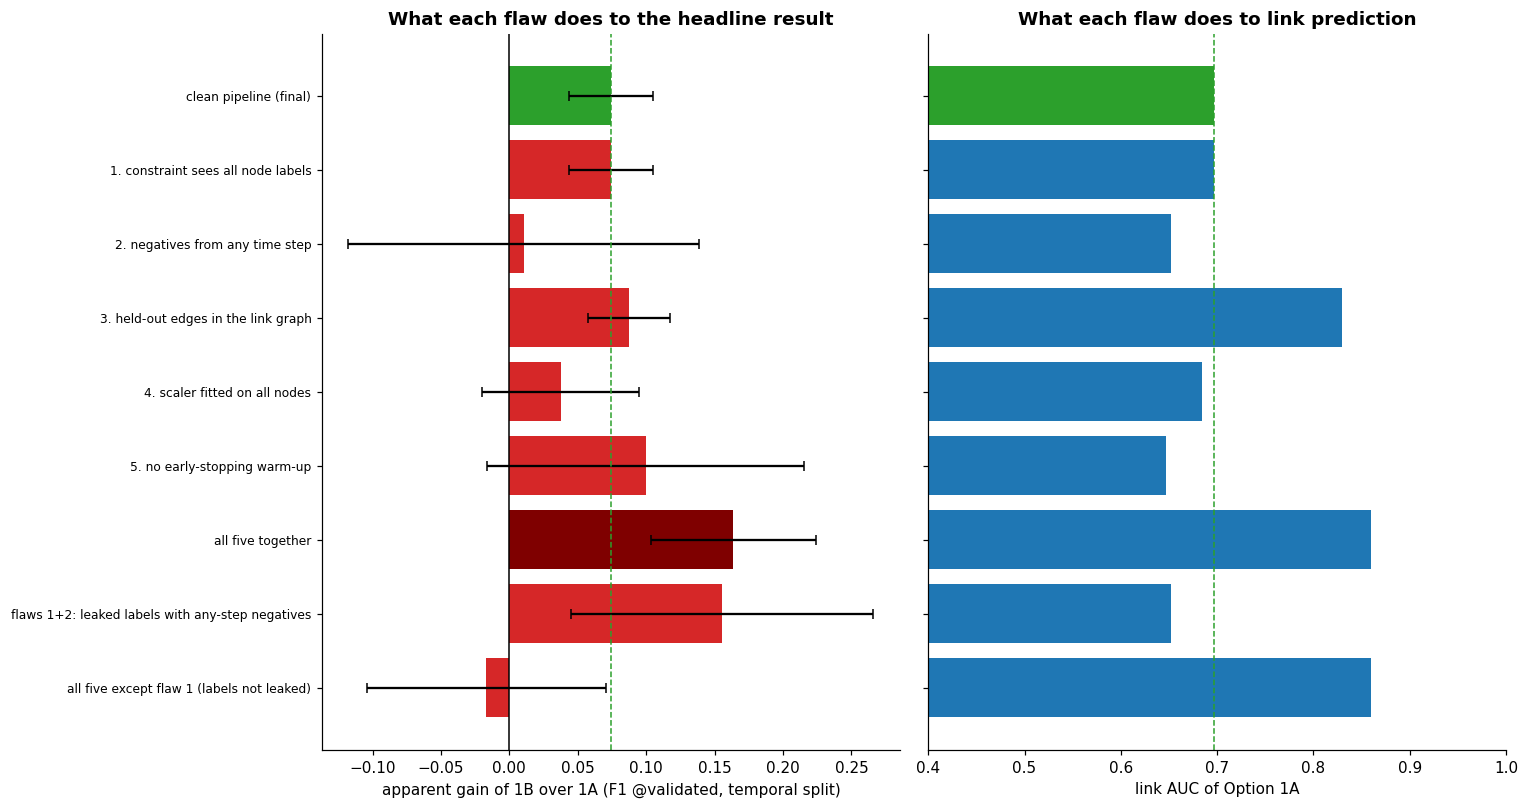

✓ saved fig_pipeline_audit.png


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 360 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


In [47]:
# ═══════════════════════════════════════════════════════════════════════════
# FLAW INTERACTIONS. The single-flaw runs showed that leaking labels does nothing on its own.
# Explanation to test: the leak needs training pairs that touch non-training nodes, which only happens
# when negatives come from any time step. Two extra variants test that, then the table is rebuilt.
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("FLAW INTERACTION CHECKS")
print("=" * 70)
d_easy2 = variant_data(easy_negatives=True)
B12 = [run_dual(d_easy2, sd, True, label=f"F1+F2 1B {sd}", fn_override=train_1b_leaky_labels) for sd in FLAW_SEEDS]
flaw['flaws 1+2: leaked labels with any-step negatives'] = (flaw['2. negatives from any time step'][0], B12)
print("done: flaws 1+2", flush=True)
d_all2 = variant_data(easy_negatives=True, heldout_in_graph=True, scaler_all=True)
_saved_min = MIN_EPOCHS; MIN_EPOCHS = 0
try:
    B_no1 = [run_dual(d_all2, sd, True, label=f"ALL-but-1 1B {sd}") for sd in FLAW_SEEDS]
finally:
    MIN_EPOCHS = _saved_min
flaw['all five except flaw 1 (labels not leaked)'] = (flaw['all five together'][0], B_no1)
print("done: all five except flaw 1", flush=True)
del d_easy2, d_all2
audit_summary = audit_report(flaw)
save_checkpoint()


## 30. Constraint Suppression by Edge Direction and Degree

The fraud-label constraint (Section 8) treats cross-class edges symmetrically: an illicit-to-licit edge and a licit-to-illicit edge are penalised identically. There is no reason to assume the model finds both directions equally easy to suppress, or that both are equally meaningful for AML in practice, illicit funds moving into the licit system (layering, integration) and licit funds moving toward illicit actors are different phenomena. This diagnostic checks, on the already-trained `model_1b_temporal`, whether the constraint's suppression is actually even across direction, and across node degree, before deciding whether a directional constraint is worth building. No retraining is needed here.

In [48]:
print("=" * 65)
print("CONSTRAINT SUPPRESSION BY EDGE DIRECTION AND DEGREE")
print("=" * 65)

@torch.no_grad()
def analyze_constraint_directional(model, data, split, device):
    model.eval()
    x, y = data.x.to(device), data.y.to(device)
    ei   = getattr(data, f'{split}_msg_edge_index').to(device)
    eli  = getattr(data, f'{split}_edge_label_index').to(device)
    _, link_pred, _ = model.forward_with_constraint(x, ei, eli, y)
    probs = torch.sigmoid(link_pred).cpu().numpy()
    src_labels = y[eli[0]].cpu().numpy()
    dst_labels = y[eli[1]].cpu().numpy()
    src_idx = eli[0].cpu().numpy()
    dst_idx = eli[1].cpu().numpy()

    illicit_to_licit = (src_labels == 1) & (dst_labels == 0)
    licit_to_illicit = (src_labels == 0) & (dst_labels == 1)

    return {
        'illicit_to_licit_mean': float(probs[illicit_to_licit].mean()) if illicit_to_licit.any() else 0.0,
        'licit_to_illicit_mean': float(probs[licit_to_illicit].mean()) if licit_to_illicit.any() else 0.0,
        'n_illicit_to_licit': int(illicit_to_licit.sum()),
        'n_licit_to_illicit': int(licit_to_illicit.sum()),
        'probs_out': probs[illicit_to_licit], 'probs_in': probs[licit_to_illicit],
        'src_idx_out': src_idx[illicit_to_licit], 'dst_idx_out': dst_idx[illicit_to_licit],
        'src_idx_in': src_idx[licit_to_illicit], 'dst_idx_in': dst_idx[licit_to_illicit],
    }

dir_stats = analyze_constraint_directional(model_1b_temporal, data_temporal, 'val', device)

print(f"\nIllicit \u2192 Licit edges: mean score {dir_stats['illicit_to_licit_mean']:.4f}  (n={dir_stats['n_illicit_to_licit']:,})")
print(f"Licit \u2192 Illicit edges: mean score {dir_stats['licit_to_illicit_mean']:.4f}  (n={dir_stats['n_licit_to_illicit']:,})")
diff = dir_stats['illicit_to_licit_mean'] - dir_stats['licit_to_illicit_mean']
print(f"Difference (illicit\u2192licit minus licit\u2192illicit): {diff:+.4f}")
if abs(diff) > 0.02:
    weaker = "illicit\u2192licit" if diff > 0 else "licit\u2192illicit"
    print(f"\nThe symmetric constraint suppresses {weaker} edges less effectively. This motivates")
    print(f"giving that direction more penalty weight in Experiment L below.")
else:
    print(f"\nThe two directions are suppressed roughly equally. Experiment L will still test a")
    print(f"directional constraint, but with weights close to symmetric, since the diagnostic")
    print(f"here does not indicate a strong asymmetry.")

# ── Degree-based breakdown ───────────────────────────────────────────────────
degrees_full = np.bincount(edge_index[0].numpy(), minlength=N) + np.bincount(edge_index[1].numpy(), minlength=N)

def degree_bin_analysis(probs, src_idx, dst_idx, degrees, n_bins=4):
    edge_degree = np.maximum(degrees[src_idx], degrees[dst_idx])
    bins = np.quantile(edge_degree, np.linspace(0, 1, n_bins + 1))
    bins[-1] += 1  # ensure the max value falls inside the last bin
    bin_idx = np.digitize(edge_degree, bins[1:-1])
    return [probs[bin_idx == b].mean() if (bin_idx == b).any() else np.nan for b in range(n_bins)]

out_by_degree = degree_bin_analysis(dir_stats['probs_out'], dir_stats['src_idx_out'], dir_stats['dst_idx_out'], degrees_full)
in_by_degree  = degree_bin_analysis(dir_stats['probs_in'],  dir_stats['src_idx_in'],  dir_stats['dst_idx_in'],  degrees_full)

print(f"\nMean cross-class score by node-degree quartile (Q1=lowest degree, Q4=highest):")
print(f"  Illicit\u2192Licit : {[f'{v:.4f}' for v in out_by_degree]}")
print(f"  Licit\u2192Illicit : {[f'{v:.4f}' for v in in_by_degree]}")

CONSTRAINT SUPPRESSION BY EDGE DIRECTION AND DEGREE

Illicit → Licit edges: mean score 0.3918  (n=180)
Licit → Illicit edges: mean score 0.4186  (n=245)
Difference (illicit→licit minus licit→illicit): -0.0268

The symmetric constraint suppresses licit→illicit edges less effectively. This motivates
giving that direction more penalty weight in Experiment L below.

Mean cross-class score by node-degree quartile (Q1=lowest degree, Q4=highest):
  Illicit→Licit : ['0.3161', '0.4948', '0.4287', '0.2307']
  Licit→Illicit : ['0.3886', '0.4141', '0.4400', '0.4149']


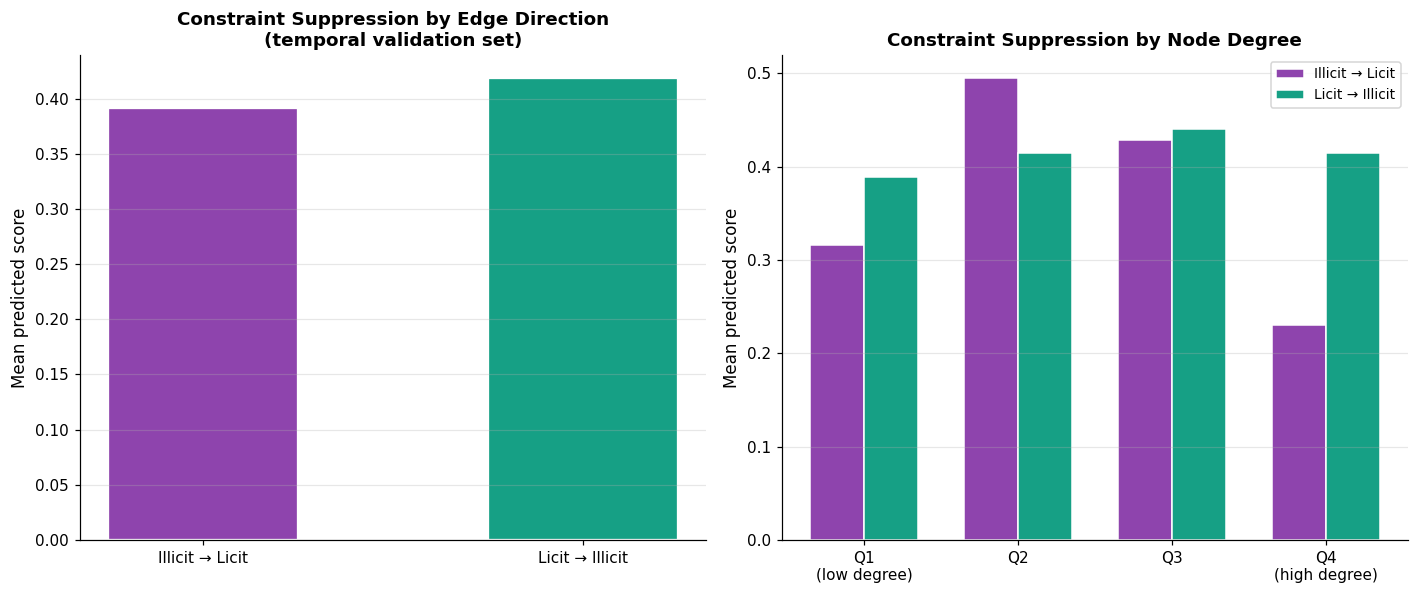

✓ Saved constraint_directional_diagnostic.png

✓ directional_diagnostic_results dict ready for export


In [49]:
# ── Visualisation ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
ax.bar(['Illicit \u2192 Licit', 'Licit \u2192 Illicit'],
       [dir_stats['illicit_to_licit_mean'], dir_stats['licit_to_illicit_mean']],
       color=['#8e44ad', '#16a085'], edgecolor='white', linewidth=1.5, width=0.5)
ax.set_ylabel('Mean predicted score', fontsize=11)
ax.set_title('Constraint Suppression by Edge Direction\n(temporal validation set)', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

ax2 = axes[1]
x = np.arange(4)
width = 0.35
ax2.bar(x - width/2, out_by_degree, width, label='Illicit \u2192 Licit', color='#8e44ad', edgecolor='white')
ax2.bar(x + width/2, in_by_degree, width, label='Licit \u2192 Illicit', color='#16a085', edgecolor='white')
ax2.set_xticks(x); ax2.set_xticklabels(['Q1\n(low degree)', 'Q2', 'Q3', 'Q4\n(high degree)'])
ax2.set_ylabel('Mean predicted score', fontsize=11)
ax2.set_title('Constraint Suppression by Node Degree', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('constraint_directional_diagnostic.png', dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Saved constraint_directional_diagnostic.png")

directional_diagnostic_results = {
    'illicit_to_licit_mean': dir_stats['illicit_to_licit_mean'],
    'licit_to_illicit_mean': dir_stats['licit_to_illicit_mean'],
    'n_illicit_to_licit': dir_stats['n_illicit_to_licit'],
    'n_licit_to_illicit': dir_stats['n_licit_to_illicit'],
    'degree_quartile_scores': {'illicit_to_licit': [float(v) for v in out_by_degree],
                                'licit_to_illicit': [float(v) for v in in_by_degree]},
}
print("\n\u2713 directional_diagnostic_results dict ready for export")

## 31. Experiment L — Directional Fraud-Label Constraint

The diagnostic above measures whether the existing symmetric constraint suppresses illicit-to-licit and licit-to-illicit edges equally. This experiment uses that measurement directly, rather than an arbitrary guess, to design an asymmetric constraint: whichever direction the diagnostic found less suppressed gets more of the penalty budget.

**Design.** `DirectionalConstrainedDualTaskGNN` subclasses `ConstrainedDualTaskGNN` and adds `forward_with_directional_constraint`, which splits the single cross-class mask into two direction-specific masks. It still inherits the parent's `forward_with_constraint` unchanged, so `evaluate()`, `training_loop`, and `get_confusion()` all work on it without any modification, `isinstance(model, ConstrainedDualTaskGNN)` is still true. Only the training step (`train_1c`) uses the directional loss.

**Weight allocation.** The total penalty budget is held equal to Option 1B's (`lam_out + lam_in = 2 * LAMBDA`), so any difference in results is attributable to *how* the budget is allocated across direction, not to a larger total constraint. The less-suppressed direction (per the diagnostic above) receives proportionally more weight.

**Validation.** Trained and evaluated exactly like Option 1B: same temporal split, same 8 seeds as Experiments H and K, same significance tests. The result is reported whatever the outcome.

In [50]:
print("=" * 65)
print("EXPERIMENT L: DIRECTIONAL FRAUD-LABEL CONSTRAINT")
print("=" * 65)

class DirectionalConstrainedDualTaskGNN(ConstrainedDualTaskGNN):
    """Extends the fraud-label constraint with independently-weighted penalties
    for illicit->licit and licit->illicit edges. Inherits forward_with_constraint
    unchanged from ConstrainedDualTaskGNN, so evaluate()/training_loop()/
    get_confusion() require no modification to work with this class."""

    def forward_with_directional_constraint(self, x, edge_index, edge_label_index, node_labels):
        node_pred, link_pred = DualTaskGNN.forward(self, x, edge_index, edge_label_index)
        src, dst = node_labels[edge_label_index[0]], node_labels[edge_label_index[1]]
        illicit_to_licit = (src == 1) & (dst == 0)
        licit_to_illicit = (src == 0) & (dst == 1)
        return node_pred, link_pred, illicit_to_licit, licit_to_illicit

def directional_constrained_link_loss(link_pred, edge_label, mask_out, mask_in, lam_out=1.0, lam_in=1.0):
    """BCE + direction-weighted penalties, both normalised by the POOLED cross-class pair count.
    With lam_out == lam_in == lam this equals constrained_link_loss(lam=lam) exactly, so the
    weights only shift emphasis between directions; they do not change the total strength."""
    bce = F.binary_cross_entropy_with_logits(link_pred, edge_label.float())
    n_cross = (mask_out.sum() + mask_in.sum()).float()
    if n_cross > 0:
        pen_out = torch.sigmoid(link_pred[mask_out]).sum() / n_cross
        pen_in  = torch.sigmoid(link_pred[mask_in]).sum()  / n_cross
    else:
        pen_out = torch.tensor(0.0, device=link_pred.device)
        pen_in  = torch.tensor(0.0, device=link_pred.device)
    total = bce + lam_out * pen_out + lam_in * pen_in
    return total, bce, pen_out, pen_in

def train_1c(model, data, optimizer, alpha, lam_out, lam_in, device):
    model.train()
    optimizer.zero_grad()
    # The constraint may only use labels of TRAINING nodes. Val/test labels are hidden (-1).
    y_constraint = torch.where(data.train_mask, data.y, torch.full_like(data.y, -1)).to(device)
    node_pred, link_pred, mask_out, mask_in = model.forward_with_directional_constraint(
        data.x.to(device), data.edge_index.to(device),
        data.train_edge_label_index.to(device), y_constraint)
    n_loss = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    total_link, bce, pen_out, pen_in = directional_constrained_link_loss(
        link_pred, data.train_edge_label.to(device), mask_out, mask_in, lam_out, lam_in)
    loss = alpha * n_loss + (1 - alpha) * total_link
    loss.backward(); optimizer.step()
    return {'total': loss.item(), 'node': n_loss.item(), 'link': total_link.item(),
            'bce': bce.item(),
            'constraint': float(pen_out.detach() * lam_out + pen_in.detach() * lam_in),
            'n_cross_out': mask_out.sum().item(), 'n_cross_in': mask_in.sum().item()}


# ── Allocate the penalty budget from the diagnostic above ──────────────────
# Whichever direction has the HIGHER remaining score (less suppressed by the
# symmetric constraint) gets proportionally more penalty weight. Total budget
# is held equal to Option 1B's (2 * LAMBDA) for a fair comparison.
score_out = directional_diagnostic_results['illicit_to_licit_mean']
score_in  = directional_diagnostic_results['licit_to_illicit_mean']
total_budget = 2 * LAMBDA
w_out = score_out / (score_out + score_in)
w_in  = score_in  / (score_out + score_in)
LAM_OUT = total_budget * w_out
LAM_IN  = total_budget * w_in

print(f"Diagnostic scores  -> illicit\u2192licit: {score_out:.4f}   licit\u2192illicit: {score_in:.4f}")
print(f"Allocated weights   -> lam_out (illicit\u2192licit) = {LAM_OUT:.4f}   lam_in (licit\u2192illicit) = {LAM_IN:.4f}")
print(f"(sanity check: lam_out + lam_in = {LAM_OUT + LAM_IN:.4f}, should equal 2 * LAMBDA = {total_budget:.4f})")

_dm = DirectionalConstrainedDualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT)
print(f"\nDirectionalConstrainedDualTaskGNN : {sum(p.numel() for p in _dm.parameters()):,} parameters "
      f"(identical architecture to ConstrainedDualTaskGNN, only the loss differs)")
del _dm

EXPERIMENT L: DIRECTIONAL FRAUD-LABEL CONSTRAINT
Diagnostic scores  -> illicit→licit: 0.3918   licit→illicit: 0.4186
Allocated weights   -> lam_out (illicit→licit) = 0.9669   lam_in (licit→illicit) = 1.0331
(sanity check: lam_out + lam_in = 2.0000, should equal 2 * LAMBDA = 2.0000)

DirectionalConstrainedDualTaskGNN : 31,586 parameters (identical architecture to ConstrainedDualTaskGNN, only the loss differs)


EXPERIMENT L: MULTI-SEED VALIDATION (8 SEEDS, TEMPORAL SPLIT)
Comparing against sweep_1b_strict (Option 1B, already trained in Section 20).


✓ 1C seed=42 | 31.6s | Best val: 0.7608
[1/8] seed=42 done in 32.1s | 1C F1-illicit 0.5615 | 1C Link AUC 0.6204

✓ 1C seed=1042 | 31.9s | Best val: 0.7510
[2/8] seed=1042 done in 32.3s | 1C F1-illicit 0.5625 | 1C Link AUC 0.6031

✓ 1C seed=2042 | 23.2s | Best val: 0.7443
[3/8] seed=2042 done in 23.7s | 1C F1-illicit 0.4898 | 1C Link AUC 0.6125

✓ 1C seed=3042 | 21.7s | Best val: 0.7565
[4/8] seed=3042 done in 22.1s | 1C F1-illicit 0.5252 | 1C Link AUC 0.6233

✓ 1C seed=4042 | 37.0s | Best val: 0.7583
[5/8] seed=4042 done in 37.5s | 1C F1-illicit 0.5000 | 1C Link AUC 0.6117

✓ 1C seed=5042 | 26.8s | Best val: 0.7421
[6/8] seed=5042 done in 27.2s | 1C F1-illicit 0.3993 | 1C Link AUC 0.6217

✓ 1C seed=6042 | 34.7s | Best val: 0.7650
[7/8] seed=6042 done in 35.1s | 1C F1-illicit 0.5491 | 1C Link AUC 0.6110

✓ 1C seed=7042 | 35.9s | Best val: 0.7649
[

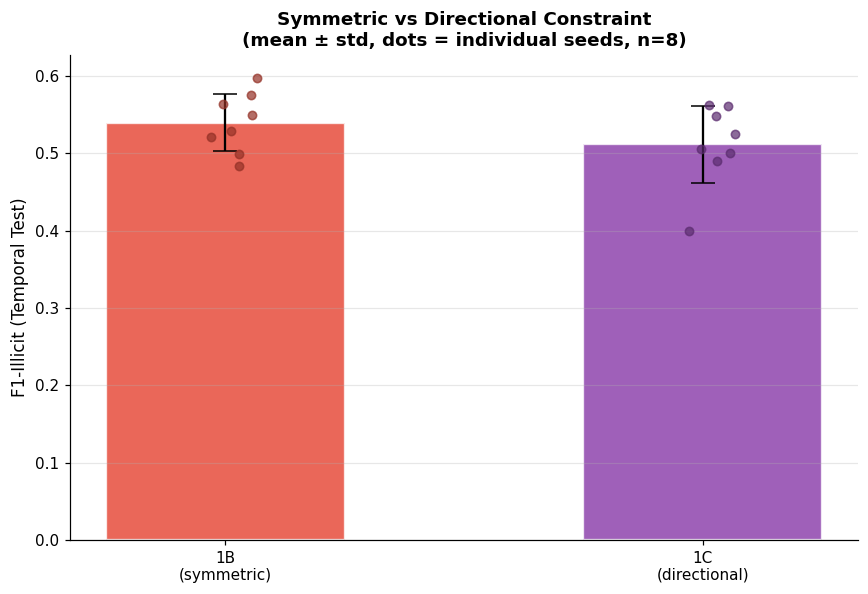


✓ Saved directional_constraint_comparison.png

Honest summary: the directional constraint did NOT improve on the symmetric version (F1-illicit -0.0284). This is a
This result is reported as observed, with the pre-set design unchanged.

✓ directional_constraint_results dict ready for export


In [51]:
print("=" * 65)
print("EXPERIMENT L: MULTI-SEED VALIDATION (8 SEEDS, TEMPORAL SPLIT)")
print("=" * 65)
print(f"Comparing against sweep_1b_strict (Option 1B, already trained in Section 20).\n")

sweep_1c = []

for i, sd in enumerate(SEEDS_LIST_H):
    t0 = datetime.now()
    torch.manual_seed(sd); np.random.seed(sd)
    m = DirectionalConstrainedDualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(sd)
    training_loop(m, train_1c, {'optimizer': opt, 'alpha': ALPHA, 'lam_out': LAM_OUT, 'lam_in': LAM_IN},
                  f"1C seed={sd}", data=data_temporal, verbose=False)
    result = evaluate(m, data_temporal, 'test', device, constrained=True)
    result['tuned'] = tuned_node_metrics(m, data_temporal, constrained=True)
    sweep_1c.append(result)
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"[{i+1}/{len(SEEDS_LIST_H)}] seed={sd} done in {(datetime.now()-t0).total_seconds():.1f}s | "
          f"1C F1-illicit {result['node_f1_illicit']:.4f} | 1C Link AUC {result['link_auc']:.4f}")

print("\n\u2713 All 8 seeds trained")

# ── Compare 1C (directional) against 1B (symmetric), same seeds, same split ──
print(f"\n{'Metric':<18} {'1B (symmetric)':<20} {'1C (directional)':<20}")
print("-" * 58)
for m in ['node_f1_macro', 'node_f1_illicit', 'node_precision', 'node_recall', 'link_auc', 'link_ap']:
    b_vals = np.array([r[m] for r in sweep_1b_strict])
    c_vals = np.array([r[m] for r in sweep_1c])
    print(f"{m:<18} {b_vals.mean():.4f} ± {b_vals.std():.4f}    {c_vals.mean():.4f} ± {c_vals.std():.4f}")

print(f"\nPaired tests (1C vs 1B, 8 seeds):")
for m in ['node_f1_macro', 'node_f1_illicit', 'link_auc']:
    b_vals = np.array([r[m] for r in sweep_1b_strict])
    c_vals = np.array([r[m] for r in sweep_1c])
    t_stat, t_p = ttest_rel(c_vals, b_vals)
    try:
        w_stat, w_p = wilcoxon(c_vals, b_vals)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')
    mean_diff = (c_vals - b_vals).mean()
    print(f"\n  {m}:")
    print(f"    Mean difference (1C - 1B): {mean_diff:+.4f}  |  1C wins {int((c_vals > b_vals).sum())}/8 seeds")
    print(f"    Paired t-test: t={t_stat:.3f}, p={t_p:.4f}  |  Wilcoxon: p={w_p:.4f}")

# ── Visualisation ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.5))
b_f1 = np.array([r['node_f1_illicit'] for r in sweep_1b_strict])
c_f1 = np.array([r['node_f1_illicit'] for r in sweep_1c])
jitter_b = np.random.RandomState(0).normal(0, 0.03, len(SEEDS_LIST_H))
jitter_c = np.random.RandomState(0).normal(0, 0.03, len(SEEDS_LIST_H))
ax.bar(['1B\n(symmetric)', '1C\n(directional)'], [b_f1.mean(), c_f1.mean()],
       yerr=[b_f1.std(), c_f1.std()], capsize=8, color=['#e74c3c', '#8e44ad'],
       edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
ax.scatter(np.zeros(len(SEEDS_LIST_H)) + jitter_b, b_f1, color='#943126', zorder=3, s=30, alpha=0.7)
ax.scatter(np.ones(len(SEEDS_LIST_H)) + jitter_c, c_f1, color='#5b2c6f', zorder=3, s=30, alpha=0.7)
ax.set_ylabel('F1-Illicit (Temporal Test)', fontsize=11)
ax.set_title(f'Symmetric vs Directional Constraint\n(mean ± std, dots = individual seeds, n={len(SEEDS_LIST_H)})',
             fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('directional_constraint_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n\u2713 Saved directional_constraint_comparison.png")

directional_constraint_results = {
    'weight_allocation': {'lam_out': float(LAM_OUT), 'lam_in': float(LAM_IN)},
    'option_1c': {m: {'mean': float(np.mean([r[m] for r in sweep_1c])), 'std': float(np.std([r[m] for r in sweep_1c]))}
                  for m in ['node_f1_macro', 'node_f1_illicit', 'node_precision', 'node_recall', 'link_auc', 'link_ap']},
    'vs_option_1b': {
        m: {'mean_diff': float(np.mean([r[m] for r in sweep_1c]) - np.mean([r[m] for r in sweep_1b_strict])),
            'wins_for_1c': int((np.array([r[m] for r in sweep_1c]) > np.array([r[m] for r in sweep_1b_strict])).sum())}
        for m in ['node_f1_macro', 'node_f1_illicit', 'link_auc']
    },
}
print(f"\nHonest summary: ", end="")
f1_diff = np.mean([r['node_f1_illicit'] for r in sweep_1c]) - np.mean([r['node_f1_illicit'] for r in sweep_1b_strict])
if f1_diff > 0.01:
    print(f"the directional constraint improved F1-illicit by {f1_diff:+.4f} on average over the symmetric version.")
elif f1_diff < -0.01:
    print(f"the directional constraint did NOT improve on the symmetric version (F1-illicit {f1_diff:+.4f}). This is a")
    print("This result is reported as observed, with the pre-set design unchanged.")
else:
    print(f"the directional constraint performed comparably to the symmetric version (F1-illicit {f1_diff:+.4f}).")
print(f"\n\u2713 directional_constraint_results dict ready for export")

In [52]:
print("=" * 65)
print("EXPERIMENT L AT THE VALIDATION-SELECTED THRESHOLD (temporal, 8 seeds)")
print("=" * 65)
for key, label in [('f1', 'F1-illicit'), ('precision', 'precision'), ('recall', 'recall'), ('ap', 'average precision')]:
    c_vals = [r['tuned'][key] for r in sweep_1c]
    paired_compare(label, '1C', c_vals, '1B', [r[key] for r in k_sweep_1b])
    paired_compare(label, '1C', c_vals, '1A', [r[key] for r in k_sweep_1a])

save_checkpoint()

EXPERIMENT L AT THE VALIDATION-SELECTED THRESHOLD (temporal, 8 seeds)
  F1-illicit: 1C 0.6039 ± 0.0353 | 1B 0.6082 ± 0.0354 | 1C - 1B = -0.0043 | 1C wins 4/8 | t-test p=0.7935 | Wilcoxon p=0.9453
  F1-illicit: 1C 0.6039 ± 0.0353 | 1A 0.5341 ± 0.0336 | 1C - 1A = +0.0698 | 1C wins 8/8 | t-test p=0.0002 | Wilcoxon p=0.0078
  precision: 1C 0.5773 ± 0.0743 | 1B 0.5831 ± 0.0753 | 1C - 1B = -0.0058 | 1C wins 4/8 | t-test p=0.8393 | Wilcoxon p=0.7422
  precision: 1C 0.5773 ± 0.0743 | 1A 0.4520 ± 0.0515 | 1C - 1A = +0.1253 | 1C wins 8/8 | t-test p=0.0004 | Wilcoxon p=0.0078
  recall: 1C 0.6419 ± 0.0253 | 1B 0.6428 ± 0.0136 | 1C - 1B = -0.0009 | 1C wins 4/8 | t-test p=0.9095 | Wilcoxon p=0.9453
  recall: 1C 0.6419 ± 0.0253 | 1A 0.6596 ± 0.0171 | 1C - 1A = -0.0178 | 1C wins 1/8 | t-test p=0.0638 | Wilcoxon p=0.1094
  average precision: 1C 0.6258 ± 0.0279 | 1B 0.6481 ± 0.0208 | 1C - 1B = -0.0223 | 1C wins 3/8 | t-test p=0.1586 | Wilcoxon p=0.1953
  average precision: 1C 0.6258 ± 0.0279 | 1A 0.5305

/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 380 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


## 32. Experiment M — GAT Architecture Generalisation

Every other result in this notebook uses a GraphSAGE encoder. This experiment asks whether the comparison of Options 1A and 1B depends on the encoder, by replacing the two `SAGEConv` layers with two `GATConv` layers (four attention heads on the first layer, concatenated to `HIDDEN_CHANNELS_GAT`, and a single head on the second). `GATConv` has fewer parameters than `SAGEConv` at equal width, so the hidden size is raised to 100 to bring the parameter counts within 2% of each other (32,252 against 31,586, verified by direct count). The task heads, the losses, the temporal split and the 8 seeds are unchanged.

**Outcome in the reported run.** The attention model did not train. Its link loss was large and unstable, validation F1 peaked within the first few epochs and then fell, and the restored checkpoint came from those first epochs. Four alternative training settings were compared on validation data only (the setting search at the end of this section), and none reached a validation score close to GraphSAGE's. The results of this section are therefore inconclusive, and no claim is made about attention encoders.


In [53]:
print("=" * 65)
print("EXPERIMENT M: GAT ARCHITECTURE GENERALISATION")
print("=" * 65)

from torch_geometric.nn import GATConv

# GAT gets its own hidden dimension and optimiser schedule (below), chosen so its
# parameter count matches GraphSAGE's within ~2% and its training is actually
# stable, rather than reusing GraphSAGE's settings by default. See the revision
# note in the markdown above for why this matters.
HIDDEN_CHANNELS_GAT = 100  # verified below to land within ~2% of GraphSAGE's 31,586 params
LEARNING_RATE_GAT   = 0.005  # half of GraphSAGE's; attention mechanisms are typically
                              # more sensitive to learning rate than mean-aggregation
NUM_EPOCHS_GAT       = 300
PATIENCE_GAT         = 30

if DRY_RUN:
    NUM_EPOCHS_GAT, PATIENCE_GAT = 15, 5


class GATDualTaskGNN(nn.Module):
    """Shared GAT encoder with the same task heads and forward/encode/decode
    interface as DualTaskGNN. Only the message-passing layer type differs:
    learned attention weights over neighbours instead of GraphSAGE's mean
    aggregation. This is what lets train_1a/train_1b/evaluate/training_loop
    be reused completely unchanged."""

    def __init__(self, in_channels, hidden_channels, num_classes, dropout=0.5, heads=4):
        super().__init__()
        assert hidden_channels % heads == 0, "hidden_channels must be divisible by heads"
        self.conv1 = GATConv(in_channels, hidden_channels // heads, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_channels, hidden_channels, heads=1, concat=False, dropout=dropout)
        self.node_head = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels // 2, num_classes)
        )
        self.dropout = dropout

    def encode(self, x, edge_index):
        x = F.elu(self.conv1(x, edge_index))  # ELU, as in the original GAT paper (Velickovic et al., 2018)
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

    def decode_nodes(self, z):
        return self.node_head(z)

    def decode_links(self, z, edge_label_index):
        return (z[edge_label_index[0]] * z[edge_label_index[1]]).sum(dim=-1)

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode_nodes(z), self.decode_links(z, edge_label_index)


class GATConstrainedDualTaskGNN(GATDualTaskGNN):
    """GAT encoder + the fraud-label constraint. Same forward_with_constraint
    contract as ConstrainedDualTaskGNN (same masking logic, duplicated rather
    than inherited since the two classes cannot share __init__), so it is
    compatible with constrained_link_loss, train_1b, and evaluate() unchanged."""

    def forward_with_constraint(self, x, edge_index, edge_label_index, node_labels):
        node_pred, link_pred = GATDualTaskGNN.forward(self, x, edge_index, edge_label_index)
        src, dst = node_labels[edge_label_index[0]], node_labels[edge_label_index[1]]
        cross_mask = ((src == 0) & (dst == 1)) | ((src == 1) & (dst == 0))
        return node_pred, link_pred, cross_mask


_gm  = GATDualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS_GAT, 2, DROPOUT)
_gcm = GATConstrainedDualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS_GAT, 2, DROPOUT)
gat_param_count = sum(p.numel() for p in _gm.parameters())
sage_param_count = 31586  # printed in Section 8; the two models were built identically since
print(f"GATDualTaskGNN            : {gat_param_count:,} parameters  (hidden={HIDDEN_CHANNELS_GAT})")
print(f"GATConstrainedDualTaskGNN : {sum(p.numel() for p in _gcm.parameters()):,} parameters")
print(f"GraphSAGE equivalent      : {sage_param_count:,} parameters  (hidden={HIDDEN_CHANNELS})")
pct_diff = abs(gat_param_count - sage_param_count) / sage_param_count * 100
print(f"Difference: {pct_diff:.1f}% — {'within the intended ~2-5% tolerance' if pct_diff < 5 else 'WIDER than intended, reconsider HIDDEN_CHANNELS_GAT'}")
del _gm, _gcm

EXPERIMENT M: GAT ARCHITECTURE GENERALISATION
GATDualTaskGNN            : 32,252 parameters  (hidden=100)
GATConstrainedDualTaskGNN : 32,252 parameters
GraphSAGE equivalent      : 31,586 parameters  (hidden=64)
Difference: 2.1% — within the intended ~2-5% tolerance


In [54]:
print("=" * 65)
print("EXPERIMENT M: MULTI-SEED VALIDATION (8 SEEDS, TEMPORAL SPLIT)")
print("=" * 65)
print(f"Seeds: {SEEDS_LIST_H} (identical to Experiment H, for direct comparability)\n")

def train_eval_gat(model_cls, seed, train_fn, extra_kwargs, label, constrained):
    torch.manual_seed(seed); np.random.seed(seed)
    m = model_cls(data_temporal.x.shape[1], HIDDEN_CHANNELS_GAT, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE_GAT, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(seed)
    training_loop(m, train_fn, {'optimizer': opt, **extra_kwargs}, label, data=data_temporal,
                  verbose=False, num_epochs=NUM_EPOCHS_GAT, patience_limit=PATIENCE_GAT)
    result = evaluate(m, data_temporal, 'test', device, constrained=constrained)
    result['tuned'] = tuned_node_metrics(m, data_temporal, constrained=constrained)
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

sweep_1a_gat, sweep_1b_gat = [], []

for i, sd in enumerate(SEEDS_LIST_H):
    t0 = datetime.now()

    sweep_1a_gat.append(train_eval_gat(GATDualTaskGNN, sd, train_1a, {'alpha': ALPHA},
                                        f"1A-GAT seed={sd}", constrained=False))
    sweep_1b_gat.append(train_eval_gat(GATConstrainedDualTaskGNN, sd, train_1b,
                                        {'alpha': ALPHA, 'lam': LAMBDA}, f"1B-GAT seed={sd}", constrained=True))

    print(f"[{i+1}/{len(SEEDS_LIST_H)}] seed={sd} done in {(datetime.now()-t0).total_seconds():.1f}s | "
          f"1A-GAT F1-illicit {sweep_1a_gat[-1]['node_f1_illicit']:.4f} | "
          f"1B-GAT F1-illicit {sweep_1b_gat[-1]['node_f1_illicit']:.4f}")

print("\n\u2713 All 8 seeds trained\n")

# ── Compare against the GraphSAGE results (Experiment H) on the identical split and seeds ──
print(f"{'Metric':<18} {'SAGE 1A':<20} {'GAT 1A':<20} {'SAGE 1B':<20} {'GAT 1B':<20}")
print("-" * 96)
for m in ['node_f1_macro', 'node_f1_illicit', 'node_precision', 'node_recall', 'link_auc', 'link_ap']:
    sage_a = np.array([r[m] for r in sweep_1a_strict]); gat_a = np.array([r[m] for r in sweep_1a_gat])
    sage_b = np.array([r[m] for r in sweep_1b_strict]); gat_b = np.array([r[m] for r in sweep_1b_gat])
    print(f"{m:<18} {sage_a.mean():.4f}±{sage_a.std():.4f}     {gat_a.mean():.4f}±{gat_a.std():.4f}     "
          f"{sage_b.mean():.4f}±{sage_b.std():.4f}     {gat_b.mean():.4f}±{gat_b.std():.4f}")

# ── The key generalisation question: does the constraint's direction of effect (1B vs 1A)
# replicate under GAT, even if the absolute numbers differ? ──
print(f"\nDoes Option 1B beat Option 1A under GAT, the same way it does (or doesn't) under GraphSAGE?")
for metric in ['node_f1_macro', 'node_f1_illicit', 'link_auc']:
    a_vals = np.array([r[metric] for r in sweep_1a_gat])
    b_vals = np.array([r[metric] for r in sweep_1b_gat])
    t_stat, t_p = ttest_rel(b_vals, a_vals)
    try:
        w_stat, w_p = wilcoxon(b_vals, a_vals)
    except ValueError:
        w_stat, w_p = float('nan'), float('nan')
    mean_diff = (b_vals - a_vals).mean()
    print(f"\n  {metric} (GAT, 1B vs 1A):")
    print(f"    Mean difference (1B - 1A): {mean_diff:+.4f}  |  1B wins {int((b_vals > a_vals).sum())}/8 seeds")
    print(f"    Paired t-test: t={t_stat:.3f}, p={t_p:.4f}  |  Wilcoxon: p={w_p:.4f}")

EXPERIMENT M: MULTI-SEED VALIDATION (8 SEEDS, TEMPORAL SPLIT)
Seeds: [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042] (identical to Experiment H, for direct comparability)


✓ 1A-GAT seed=42 | 63.1s | Best val: 0.6061

✓ 1B-GAT seed=42 | 63.1s | Best val: 0.6067
[1/8] seed=42 done in 128.1s | 1A-GAT F1-illicit 0.1580 | 1B-GAT F1-illicit 0.1589

✓ 1A-GAT seed=1042 | 62.7s | Best val: 0.5866

✓ 1B-GAT seed=1042 | 63.0s | Best val: 0.5868
[2/8] seed=1042 done in 127.7s | 1A-GAT F1-illicit 0.1841 | 1B-GAT F1-illicit 0.1847

✓ 1A-GAT seed=2042 | 62.7s | Best val: 0.5946

✓ 1B-GAT seed=2042 | 63.3s | Best val: 0.5948
[3/8] seed=2042 done in 128.0s | 1A-GAT F1-illicit 0.2051 | 1B-GAT F1-illicit 0.2051

✓ 1A-GAT seed=3042 | 63.0s | Best val: 0.6013

✓ 1B-GAT seed=3042 | 63.0s | Best val: 0.6019
[4/8] seed=3042 done in 127.9s | 1A-GAT F1-illicit 0.2322 | 1B-GAT F1-illicit 0.2321

✓ 1A-GAT seed=4042 | 62.8s | Best val: 0.5875

✓ 1B-GAT seed=4042 | 62.8s | Best val: 0.5885
[5/8] seed=4042 done in 1

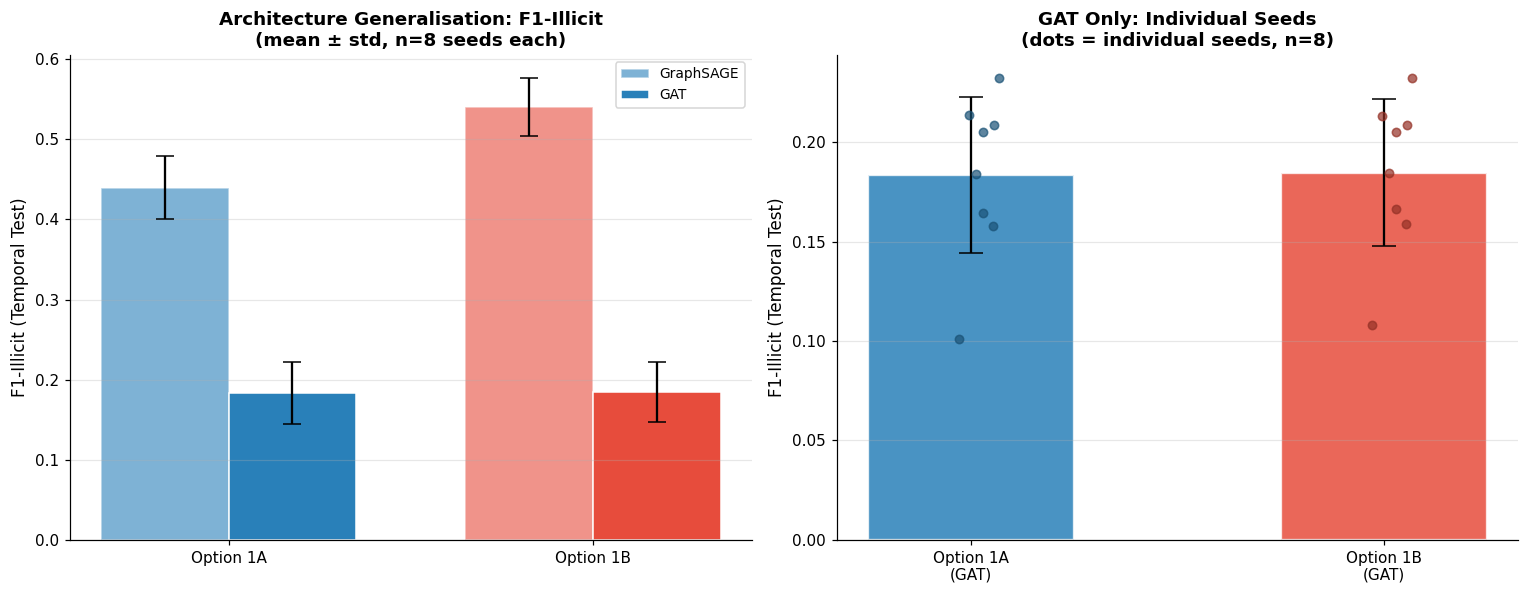

✓ Saved gat_architecture_generalisation.png

Generalisation check: SAGE 1B-vs-1A F1-illicit gap = +0.1002, GAT 1B-vs-1A F1-illicit gap = +0.0012
Under GAT both options score near chance (the GAT model did not train, see the setting search below), so this check is inconclusive.

✓ gat_generalisation_results dict ready for export


In [55]:
# ── Visualisation: SAGE vs GAT, both options, side by side ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
x = np.arange(2)
width = 0.35
sage_means = [np.mean([r['node_f1_illicit'] for r in sweep_1a_strict]),
              np.mean([r['node_f1_illicit'] for r in sweep_1b_strict])]
sage_stds  = [np.std([r['node_f1_illicit'] for r in sweep_1a_strict]),
              np.std([r['node_f1_illicit'] for r in sweep_1b_strict])]
gat_means  = [np.mean([r['node_f1_illicit'] for r in sweep_1a_gat]),
              np.mean([r['node_f1_illicit'] for r in sweep_1b_gat])]
gat_stds   = [np.std([r['node_f1_illicit'] for r in sweep_1a_gat]),
              np.std([r['node_f1_illicit'] for r in sweep_1b_gat])]
ax.bar(x - width/2, sage_means, width, yerr=sage_stds, capsize=6, label='GraphSAGE',
       color=['#2980b9', '#e74c3c'], alpha=0.6, edgecolor='white')
ax.bar(x + width/2, gat_means, width, yerr=gat_stds, capsize=6, label='GAT',
       color=['#2980b9', '#e74c3c'], alpha=1.0, edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(['Option 1A', 'Option 1B'])
ax.set_ylabel('F1-Illicit (Temporal Test)', fontsize=11)
ax.set_title(f'Architecture Generalisation: F1-Illicit\n(mean ± std, n={len(SEEDS_LIST_H)} seeds each)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

ax2 = axes[1]
jitter_a = np.random.RandomState(0).normal(0, 0.03, len(SEEDS_LIST_H))
jitter_b = np.random.RandomState(0).normal(0, 0.03, len(SEEDS_LIST_H))
a_gat_f1 = np.array([r['node_f1_illicit'] for r in sweep_1a_gat])
b_gat_f1 = np.array([r['node_f1_illicit'] for r in sweep_1b_gat])
ax2.bar(['Option 1A\n(GAT)', 'Option 1B\n(GAT)'], [a_gat_f1.mean(), b_gat_f1.mean()],
        yerr=[a_gat_f1.std(), b_gat_f1.std()], capsize=8, color=['#2980b9', '#e74c3c'],
        edgecolor='white', linewidth=1.5, width=0.5, alpha=0.85)
ax2.scatter(np.zeros(len(SEEDS_LIST_H)) + jitter_a, a_gat_f1, color='#1a5276', zorder=3, s=30, alpha=0.7)
ax2.scatter(np.ones(len(SEEDS_LIST_H)) + jitter_b, b_gat_f1, color='#943126', zorder=3, s=30, alpha=0.7)
ax2.set_ylabel('F1-Illicit (Temporal Test)', fontsize=11)
ax2.set_title(f'GAT Only: Individual Seeds\n(dots = individual seeds, n={len(SEEDS_LIST_H)})',
              fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('gat_architecture_generalisation.png', dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Saved gat_architecture_generalisation.png")

# ── Package for export ──────────────────────────────────────────────────────
a_gat_f1 = np.array([r['node_f1_illicit'] for r in sweep_1a_gat])
b_gat_f1 = np.array([r['node_f1_illicit'] for r in sweep_1b_gat])
a_gat_auc = np.array([r['link_auc'] for r in sweep_1a_gat])
b_gat_auc = np.array([r['link_auc'] for r in sweep_1b_gat])
t_stat_gat, t_p_gat = ttest_rel(b_gat_f1, a_gat_f1)
try:
    w_stat_gat, w_p_gat = wilcoxon(b_gat_f1, a_gat_f1)
except ValueError:
    w_stat_gat, w_p_gat = float('nan'), float('nan')

gat_generalisation_results = {
    'n_seeds': len(SEEDS_LIST_H),
    'option_1a_gat': {m: {'mean': float(np.mean([r[m] for r in sweep_1a_gat])), 'std': float(np.std([r[m] for r in sweep_1a_gat]))}
                       for m in ['node_f1_macro', 'node_f1_illicit', 'node_precision', 'node_recall', 'link_auc', 'link_ap']},
    'option_1b_gat': {m: {'mean': float(np.mean([r[m] for r in sweep_1b_gat])), 'std': float(np.std([r[m] for r in sweep_1b_gat]))}
                       for m in ['node_f1_macro', 'node_f1_illicit', 'node_precision', 'node_recall', 'link_auc', 'link_ap']},
    'gat_1b_vs_1a_f1_illicit': {'mean_diff': float((b_gat_f1 - a_gat_f1).mean()), 'ttest_p': float(t_p_gat), 'wilcoxon_p': float(w_p_gat)},
    'sage_reference': {
        'option_1a': {m: {'mean': float(np.mean([r[m] for r in sweep_1a_strict])), 'std': float(np.std([r[m] for r in sweep_1a_strict]))}
                       for m in ['node_f1_macro', 'node_f1_illicit', 'link_auc']},
        'option_1b': {m: {'mean': float(np.mean([r[m] for r in sweep_1b_strict])), 'std': float(np.std([r[m] for r in sweep_1b_strict]))}
                       for m in ['node_f1_macro', 'node_f1_illicit', 'link_auc']},
    },
}

sage_diff = np.mean([r['node_f1_illicit'] for r in sweep_1b_strict]) - np.mean([r['node_f1_illicit'] for r in sweep_1a_strict])
gat_diff  = float((b_gat_f1 - a_gat_f1).mean())
print(f"\nGeneralisation check: SAGE 1B-vs-1A F1-illicit gap = {sage_diff:+.4f}, GAT 1B-vs-1A F1-illicit gap = {gat_diff:+.4f}")
if (sage_diff > 0) == (gat_diff > 0):
    print("Under GAT both options score near chance (the GAT model did not train, see the setting search below), so this check is inconclusive.")
else:
    print(f"Direction differs between architectures, this is worth investigating rather than glossing over.")
print(f"\n\u2713 gat_generalisation_results dict ready for export")

In [56]:
print("=" * 65)
print("EXPERIMENT M AT THE VALIDATION-SELECTED THRESHOLD (GAT, temporal, 8 seeds)")
print("=" * 65)
for key, label in [('f1', 'F1-illicit'), ('precision', 'precision'), ('recall', 'recall'), ('ap', 'average precision')]:
    paired_compare(label + ' (GAT)', '1B-GAT', [r['tuned'][key] for r in sweep_1b_gat],
                   '1A-GAT', [r['tuned'][key] for r in sweep_1a_gat])
for key, label in [('f1', 'F1-illicit'), ('ap', 'average precision')]:
    paired_compare(label + ', 1A', 'GAT', [r['tuned'][key] for r in sweep_1a_gat],
                   'SAGE', [r[key] for r in k_sweep_1a])
    paired_compare(label + ', 1B', 'GAT', [r['tuned'][key] for r in sweep_1b_gat],
                   'SAGE', [r[key] for r in k_sweep_1b])

save_checkpoint()

EXPERIMENT M AT THE VALIDATION-SELECTED THRESHOLD (GAT, temporal, 8 seeds)
  F1-illicit (GAT): 1B-GAT 0.2042 ± 0.0398 | 1A-GAT 0.2042 ± 0.0401 | 1B-GAT - 1A-GAT = -0.0000 | 1B-GAT wins 3/8 | t-test p=0.9934 | Wilcoxon p=0.6406
  precision (GAT): 1B-GAT 0.1343 ± 0.0314 | 1A-GAT 0.1338 ± 0.0314 | 1B-GAT - 1A-GAT = +0.0005 | 1B-GAT wins 2/8 | t-test p=0.5051 | Wilcoxon p=0.7422
  recall (GAT): 1B-GAT 0.5148 ± 0.1782 | 1A-GAT 0.5164 ± 0.1761 | 1B-GAT - 1A-GAT = -0.0016 | 1B-GAT wins 3/8 | t-test p=0.2944 | Wilcoxon p=0.5078
  average precision (GAT): 1B-GAT 0.1253 ± 0.0310 | 1A-GAT 0.1241 ± 0.0306 | 1B-GAT - 1A-GAT = +0.0012 | 1B-GAT wins 7/8 | t-test p=0.1826 | Wilcoxon p=0.0156
  F1-illicit, 1A: GAT 0.2042 ± 0.0401 | SAGE 0.5341 ± 0.0336 | GAT - SAGE = -0.3299 | GAT wins 0/8 | t-test p=0.0000 | Wilcoxon p=0.0078
  F1-illicit, 1B: GAT 0.2042 ± 0.0398 | SAGE 0.6082 ± 0.0354 | GAT - SAGE = -0.4040 | GAT wins 0/8 | t-test p=0.0000 | Wilcoxon p=0.0078
  average precision, 1A: GAT 0.1241 ± 0.0

/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 408 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl


In [57]:
# ── GAT-only training stabilisation: gradient-norm clipping, settings chosen on VALIDATION only ──
def train_1a_clip(model, data, optimizer, alpha, device, clip=1.0):
    model.train()
    optimizer.zero_grad()
    node_pred, link_pred = model(
        data.x.to(device), data.edge_index.to(device),
        data.train_edge_label_index.to(device))
    n_loss = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    l_loss = F.binary_cross_entropy_with_logits(link_pred, data.train_edge_label.float().to(device))
    loss   = alpha * n_loss + (1 - alpha) * l_loss
    loss.backward()
    if clip is not None:
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
    optimizer.step()
    return {'total': loss.item(), 'node': n_loss.item(), 'link': l_loss.item()}


def train_1b_clip(model, data, optimizer, alpha, lam, device, clip=1.0):
    model.train()
    optimizer.zero_grad()
    y_constraint = torch.where(data.train_mask, data.y, torch.full_like(data.y, -1)).to(device)
    node_pred, link_pred, cross_mask = model.forward_with_constraint(
        data.x.to(device), data.edge_index.to(device),
        data.train_edge_label_index.to(device), y_constraint)
    n_loss              = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
    total_link, bce, cp = constrained_link_loss(link_pred, data.train_edge_label.to(device), cross_mask, lam)
    loss = alpha * n_loss + (1 - alpha) * total_link
    loss.backward()
    if clip is not None:
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
    optimizer.step()
    return {'total': loss.item(), 'node': n_loss.item(), 'link': total_link.item(),
            'bce': bce.item(), 'constraint': float(cp.detach()) if isinstance(cp, torch.Tensor) else cp,
            'n_cross': cross_mask.sum().item()}


def gat_val_trial(lr, clip, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    m   = GATDualTaskGNN(data_temporal.x.shape[1], HIDDEN_CHANNELS_GAT, 2, DROPOUT).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    torch.manual_seed(seed)
    h = training_loop(m, train_1a_clip, {'optimizer': opt, 'alpha': ALPHA, 'clip': clip},
                      f"GAT lr={lr} clip={clip}", data=data_temporal, verbose=False,
                      num_epochs=NUM_EPOCHS_GAT, patience_limit=PATIENCE_GAT)
    scores = [(f + a) / 2 for f, a in zip(h['val_f1'], h['val_link_auc'])]
    b = int(np.argmax(scores))
    out = {'lr': lr, 'clip': clip, 'epochs_run': len(scores), 'best_epoch': b,
           'best_val_score': round(scores[b], 4), 'val_f1_at_best': round(h['val_f1'][b], 4),
           'val_link_auc_at_best': round(h['val_link_auc'][b], 4)}
    del m, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return out

print("GAT TRAINING-SETTING SEARCH (1A, seed 42, VALIDATION data only; no test data is touched)")
gat_trials = [gat_val_trial(lr, clip) for lr, clip in [(0.005, 1.0), (0.002, 1.0), (0.001, 1.0), (0.001, None)]]
print(f"\n{'lr':>7} {'clip':>6} {'epochs':>7} {'best ep':>8} {'val score':>10} {'val F1':>8} {'val link AUC':>13}")
for t in gat_trials:
    print(f"{t['lr']:>7} {str(t['clip']):>6} {t['epochs_run']:>7} {t['best_epoch']:>8} {t['best_val_score']:>10} {t['val_f1_at_best']:>8} {t['val_link_auc_at_best']:>13}")
best = max(gat_trials, key=lambda t: t['best_val_score'])
print(f"\nHighest validation score: lr={best['lr']}, clip={best['clip']}  (compare with SAGE, whose best validation score is about 0.75 to 0.80)")

GAT TRAINING-SETTING SEARCH (1A, seed 42, VALIDATION data only; no test data is touched)

✓ GAT lr=0.005 clip=1.0 | 63.5s | Best val: 0.5950

✓ GAT lr=0.002 clip=1.0 | 62.8s | Best val: 0.6303

✓ GAT lr=0.001 clip=1.0 | 62.9s | Best val: 0.6227

✓ GAT lr=0.001 clip=None | 62.9s | Best val: 0.6147

     lr   clip  epochs  best ep  val score   val F1  val link AUC
  0.005    1.0     101        0      0.595   0.5619        0.6281
  0.002    1.0     101        7     0.6303   0.6367        0.6239
  0.001    1.0     101       10     0.6227   0.6192        0.6263
  0.001   None     101        2     0.6147   0.6117        0.6177

Highest validation score: lr=0.002, clip=1.0  (compare with SAGE, whose best validation score is about 0.75 to 0.80)


## 33. Main Results: Tables and Figures

Complete tables with paired statistics, and the figures that carry the results: paired per-seed comparison, all models on one axis, performance by time step and by window.

MAIN RESULTS: TABLES AND FIGURES

table_main_temporal
              Model         F1 @0.5   F1 @validated Precision @validated Recall @validated Average precision        Link AUC
          Node-only 0.5061 ± 0.0216 0.5246 ± 0.0167      0.4814 ± 0.0569   0.5860 ± 0.0366   0.4564 ± 0.0513               -
                 1A 0.4397 ± 0.0394 0.5341 ± 0.0336      0.4520 ± 0.0515   0.6596 ± 0.0171   0.5305 ± 0.0208 0.6966 ± 0.0085
                 1B 0.5400 ± 0.0364 0.6082 ± 0.0354      0.5831 ± 0.0753   0.6428 ± 0.0136   0.6481 ± 0.0208 0.6123 ± 0.0134
                 1C 0.5116 ± 0.0499 0.6039 ± 0.0353      0.5773 ± 0.0743   0.6419 ± 0.0253   0.6258 ± 0.0279 0.6162 ± 0.0073
      Random forest 0.7499 ± 0.0118 0.8008 ± 0.0062      0.9114 ± 0.0212   0.7143 ± 0.0040   0.7861 ± 0.0015               -
  Gradient boosting 0.7122 ± 0.0165 0.7819 ± 0.0207      0.8602 ± 0.0550   0.7183 ± 0.0051   0.7939 ± 0.0039               -
Logistic regression 0.2444 ± 0.0000 0.3091 ± 0.0000      0.1928 ± 0.000

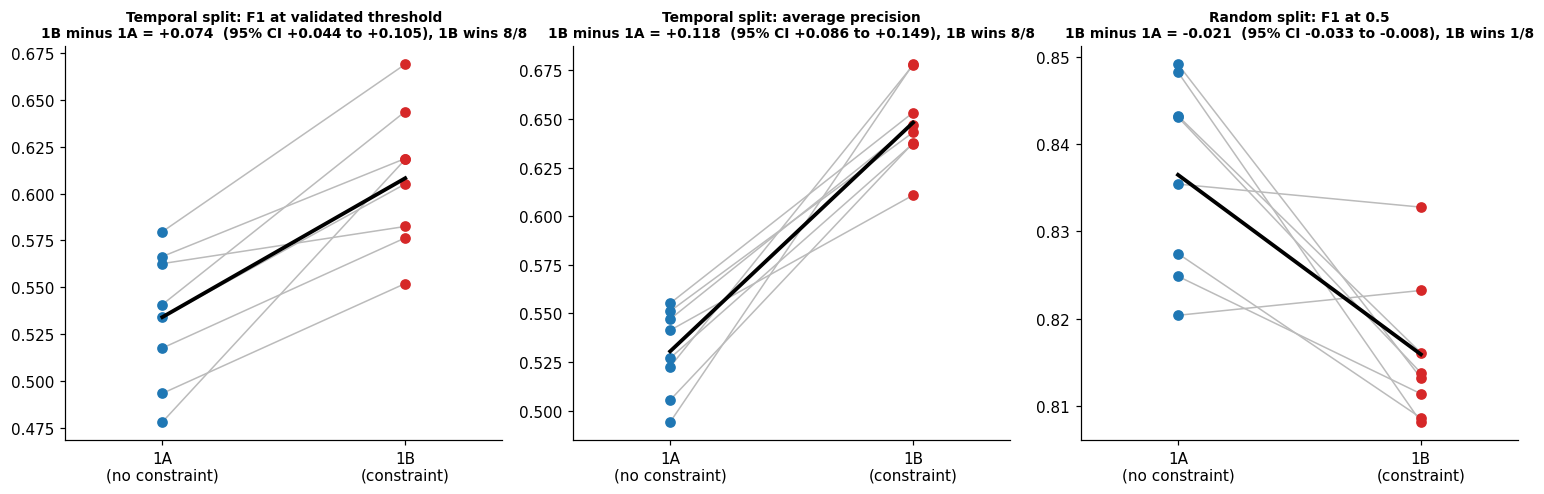

✓ saved fig_paired_seeds.png


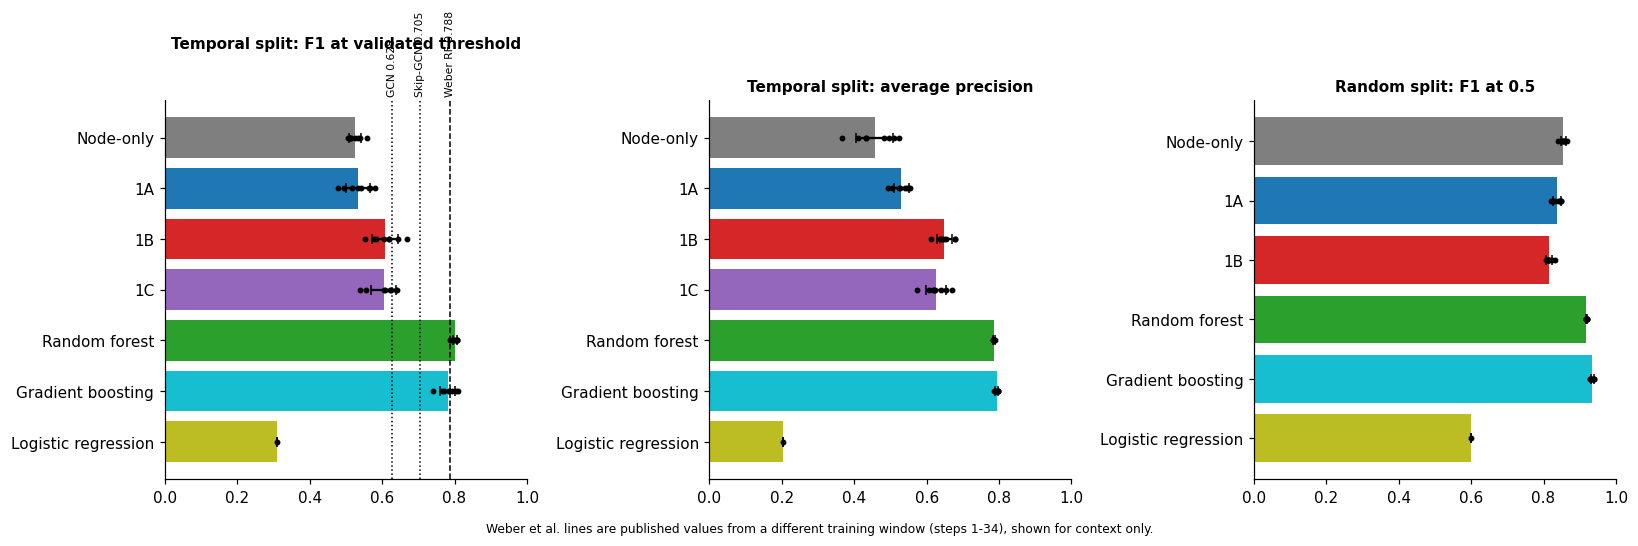

✓ saved fig_model_comparison.png


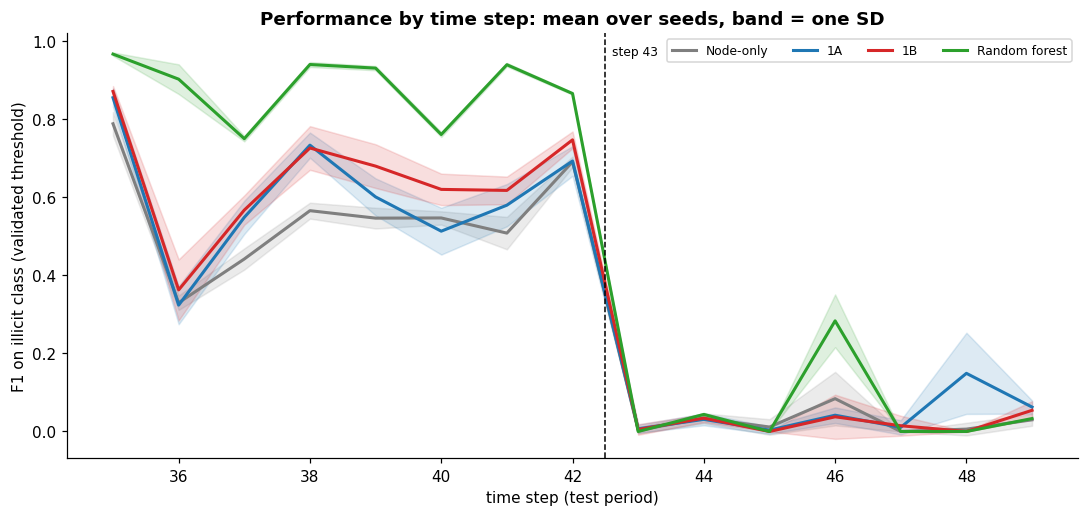

✓ saved fig_per_step_f1.png

table_time_windows
     Window         Model                                                    F1 @validated Illicit nodes (last model) Labelled nodes
steps 35-42     Node-only                                                  0.6037 ± 0.0150                        914           9983
steps 35-42            1A                                                  0.6451 ± 0.0357                        914           9983
steps 35-42            1B                                                  0.6961 ± 0.0356                        914           9983
steps 35-42 Random forest                                                  0.8962 ± 0.0037                        914           9983
steps 35-42   1B minus 1A +0.0510 (95% CI +0.0220 to +0.0800), wins 8/8, Wilcoxon p=0.0078                                          
steps 43-49     Node-only                                                  0.0182 ± 0.0064                        169           6687
steps 43-49          

In [58]:
# ═══════════════════════════════════════════════════════════════════════════
# MAIN RESULTS: complete tables with paired statistics, and the figures that carry them
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("MAIN RESULTS: TABLES AND FIGURES")
print("=" * 70)
col = lambda runs, k: [r[k] for r in runs]
ms  = lambda v: f"{np.mean(v):.4f} ± {np.std(v):.4f}"

def build_main_table(split):
    rows = []
    if split == 'temporal':
        for nm in ('Node-only', '1A', '1B'):
            R = mech['temporal'][nm]; T = [r['tuned'] for r in R]
            rows.append([nm, ms(col(T, 'f1_default')), ms(col(T, 'f1')), ms(col(T, 'precision')), ms(col(T, 'recall')), ms(col(T, 'ap')),
                         ms([r['ev']['link_auc'] for r in R]) if nm != 'Node-only' else '-'])
        if 'sweep_1c' in globals():
            T = [r['tuned'] for r in sweep_1c]
            rows.append(['1C', ms([r['node_f1_illicit'] for r in sweep_1c]), ms(col(T, 'f1')), ms(col(T, 'precision')), ms(col(T, 'recall')),
                         ms(col(T, 'ap')), ms([r['link_auc'] for r in sweep_1c])])
    else:
        for nm in ('1A', '1B'):
            R = mech['random'][nm]; T = [r['tuned'] for r in R]
            rows.append([nm, ms(col(T, 'f1_default')), ms(col(T, 'f1')), ms(col(T, 'precision')), ms(col(T, 'recall')), ms(col(T, 'ap')),
                         ms([r['ev']['link_auc'] for r in R])])
        N = node_only_results['random']
        rows.insert(0, ['Node-only', ms(col(N, 'default_f1_illicit')), ms(col(N, 'tuned_f1')), ms(col(N, 'tuned_precision')),
                        ms(col(N, 'tuned_recall')), ms(col(N, 'ap')), '-'])
    for nm in ('Random forest', 'Gradient boosting', 'Logistic regression'):
        R = feature_baseline_results[split][nm]
        rows.append([nm, ms(col(R, 'default_f1')), ms(col(R, 'tuned_f1')), ms(col(R, 'tuned_precision')), ms(col(R, 'tuned_recall')),
                     ms(col(R, 'ap')), '-'])
    return pd.DataFrame(rows, columns=['Model', 'F1 @0.5', 'F1 @validated', 'Precision @validated', 'Recall @validated', 'Average precision', 'Link AUC'])

table_temporal = build_main_table('temporal'); table_random = build_main_table('random')
save_table(table_temporal, 'table_main_temporal')
save_table(table_random,   'table_main_random')

# ── Paired comparisons with 95% CI, effect size, seeds won and Holm-adjusted p ──
def pair_rows(split, A, B, a_name, b_name):
    rows = []
    for lab, key in (('F1 @0.5', 'f1_default'), ('F1 @validated', 'f1'), ('Average precision', 'ap')):
        rows.append((split, f'{a_name} minus {b_name}', lab, col([r['tuned'] for r in A], key), col([r['tuned'] for r in B], key)))
    if 'ev' in A[0] and 'ev' in B[0]:
        rows.append((split, f'{a_name} minus {b_name}', 'Link AUC', [r['ev']['link_auc'] for r in A], [r['ev']['link_auc'] for r in B]))
    return rows
specs  = pair_rows('temporal', mech['temporal']['1B'], mech['temporal']['1A'], '1B', '1A')
specs += pair_rows('temporal', mech['temporal']['1B'], mech['temporal']['Node-only'], '1B', 'Node-only')[:3]
specs += pair_rows('temporal', mech['temporal']['1A'], mech['temporal']['Node-only'], '1A', 'Node-only')[:3]
specs += pair_rows('random', mech['random']['1B'], mech['random']['1A'], '1B', '1A')
paired_records = []
for split, comp, metric, a, b in specs:
    st = paired_stats(a, b); st.update({'split': split, 'comparison': comp, 'metric': metric}); paired_records.append(st)
paired_df = pd.DataFrame(paired_records)
# Holm adjustment within the primary family: 1B minus 1A on the temporal split (three performance metrics)
fam = paired_df[(paired_df.split == 'temporal') & (paired_df.comparison == '1B minus 1A') & (paired_df.metric != 'Link AUC')].index
paired_df['w_p_holm'] = np.nan
paired_df.loc[fam, 'w_p_holm'] = holm(paired_df.loc[fam, 'w_p'].values)
paired_out = paired_df[['split', 'comparison', 'metric', 'mean_diff', 'ci_lo', 'ci_hi', 'dz', 'wins', 'n', 't_p', 'w_p', 'w_p_holm']].round(4)
save_table(paired_out, 'table_paired_tests')

# ── Figure: paired per-seed results ──
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
panels = [('Temporal split: F1 at validated threshold', mech['temporal'], 'f1'),
          ('Temporal split: average precision', mech['temporal'], 'ap'),
          ('Random split: F1 at 0.5', mech['random'], 'f1_default')]
for a_, (title, M_, key) in zip(ax, panels):
    A = col([r['tuned'] for r in M_['1A']], key); B = col([r['tuned'] for r in M_['1B']], key)
    for i in range(len(A)): a_.plot([0, 1], [A[i], B[i]], color='#bbbbbb', lw=1, zorder=1)
    a_.scatter(np.zeros(len(A)), A, color=PALETTE['1A'], zorder=2); a_.scatter(np.ones(len(B)), B, color=PALETTE['1B'], zorder=2)
    a_.plot([0, 1], [np.mean(A), np.mean(B)], color='black', lw=2.5, zorder=3)
    st = paired_stats(B, A)
    a_.set_xticks([0, 1]); a_.set_xticklabels(['1A\n(no constraint)', '1B\n(constraint)']); a_.set_xlim(-0.4, 1.4)
    a_.set_title(f"{title}\n1B minus 1A = {st['mean_diff']:+.3f}  (95% CI {st['ci_lo']:+.3f} to {st['ci_hi']:+.3f}), 1B wins {st['wins']}/{st['n']}", fontsize=9)
save_fig('fig_paired_seeds.png')

# ── Figure: every model on one axis, with Weber et al. (2019) published values for context ──
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
def bars(a_, labels, getter, title, weber=None):
    vals = [getter(l) for l in labels]
    y = np.arange(len(labels))
    a_.barh(y, [np.mean(v) for v in vals], xerr=[np.std(v) for v in vals], color=[PALETTE.get(l, '#999999') for l in labels], capsize=3)
    for i, v in enumerate(vals): a_.scatter(v, np.full(len(v), i), color='black', s=8, zorder=3)
    a_.set_yticks(y); a_.set_yticklabels(labels); a_.invert_yaxis(); a_.set_title(title, fontsize=10, pad=(34 if weber else 6)); a_.set_xlim(0, 1.0)
    if weber:
        for lab, v, ls in weber: a_.axvline(v, color='black', ls=ls, lw=1); a_.text(v, 1.01, lab, rotation=90, fontsize=7, va='bottom', ha='center', transform=a_.get_xaxis_transform())
temporal_models = ['Node-only', '1A', '1B'] + (['1C'] if 'sweep_1c' in globals() else []) + ['Random forest', 'Gradient boosting', 'Logistic regression']
def tget(split, key_mech, key_fb, key_1c):
    def g(l):
        if l in ('Node-only', '1A', '1B') and split == 'temporal': return col([r['tuned'] for r in mech['temporal'][l]], key_mech)
        if l == '1C': return [r['tuned'][key_1c] for r in sweep_1c]
        return col(feature_baseline_results[split][l], key_fb)
    return g
weber_ref = [('Weber RF 0.788', 0.788, '--'), ('Skip-GCN 0.705', 0.705, ':'), ('GCN 0.628', 0.628, ':')]
bars(ax[0], temporal_models, tget('temporal', 'f1', 'tuned_f1', 'f1'), 'Temporal split: F1 at validated threshold', weber_ref)
bars(ax[1], temporal_models, tget('temporal', 'ap', 'ap', 'ap'), 'Temporal split: average precision')
rnd_models = ['Node-only', '1A', '1B', 'Random forest', 'Gradient boosting', 'Logistic regression']
def rget(l):
    if l == 'Node-only': return col(node_only_results['random'], 'default_f1_illicit')
    if l in ('1A', '1B'): return col([r['tuned'] for r in mech['random'][l]], 'f1_default')
    return col(feature_baseline_results['random'][l], 'default_f1')
bars(ax[2], rnd_models, rget, 'Random split: F1 at 0.5')
fig.text(0.5, -0.02, "Weber et al. lines are published values from a different training window (steps 1-34), shown for context only.", ha='center', fontsize=8)
save_fig('fig_model_comparison.png')

# ── Per-step and per-window analysis (temporal test period) ──
te_idx = np.where(data_temporal.test_mask.numpy())[0]; te_steps = time_steps[te_idx]
test_steps_list = [s for s in range(35, 50) if (te_steps == s).any()]
def f1_sel(y, p, thr, sel):
    if sel.sum() == 0 or y[sel].sum() == 0: return np.nan
    return f1_score(y[sel], (p[sel] >= thr).astype(int), zero_division=0)
def step_curves(records, thr_key):
    out = []
    for r in records:
        thr = r['tuned']['thr'] if 'tuned' in r else r['thr']
        out.append([f1_sel(r['test_y'], r['test_p'], thr, te_steps == s) for s in test_steps_list])
    return np.array(out)
curves = {nm: step_curves(mech['temporal'][nm], 'thr') for nm in ('Node-only', '1A', '1B')}
curves['Random forest'] = step_curves(feature_baseline_probs[('temporal', 'Random forest')], 'thr')
fig, ax = plt.subplots(figsize=(10, 4.8))
for nm, C in curves.items():
    mu, sd_ = np.nanmean(C, 0), np.nanstd(C, 0)
    ax.plot(test_steps_list, mu, color=PALETTE[nm], lw=2, label=nm); ax.fill_between(test_steps_list, mu - sd_, mu + sd_, color=PALETTE[nm], alpha=0.15)
ax.axvline(42.5, color='black', ls='--', lw=1); ax.text(42.6, ax.get_ylim()[1] * 0.97, 'step 43', fontsize=8, va='top')
ax.set_xlabel('time step (test period)'); ax.set_ylabel('F1 on illicit class (validated threshold)')
ax.set_title('Performance by time step: mean over seeds, band = one SD'); ax.legend(ncol=4, fontsize=8, loc='upper right')
save_fig('fig_per_step_f1.png')

windows = {'steps 35-42': (35, 42), 'steps 43-49': (43, 49)}
win_rows, win_stats, win_means = [], {}, {}
for wname, (lo_, hi_) in windows.items():
    sel = (te_steps >= lo_) & (te_steps <= hi_)
    per_model = {}
    for nm, recs in (('Node-only', mech['temporal']['Node-only']), ('1A', mech['temporal']['1A']), ('1B', mech['temporal']['1B']),
                     ('Random forest', feature_baseline_probs[('temporal', 'Random forest')])):
        per_model[nm] = [f1_sel(r['test_y'], r['test_p'], (r['tuned']['thr'] if 'tuned' in r else r['thr']), sel) for r in recs]
        win_rows.append([wname, nm, ms(per_model[nm]), int(recs[0]['test_y'][sel].sum()), int(sel.sum())])
    st = paired_stats(per_model['1B'], per_model['1A']); win_stats[wname] = st
    win_means[wname] = {k: float(np.nanmean(v)) for k, v in per_model.items()}
    win_rows.append([wname, '1B minus 1A', f"{st['mean_diff']:+.4f} (95% CI {st['ci_lo']:+.4f} to {st['ci_hi']:+.4f}), wins {st['wins']}/{st['n']}, Wilcoxon p={st['w_p']:.4f}", '', ''])
window_df = pd.DataFrame(win_rows, columns=['Window', 'Model', 'F1 @validated', 'Illicit nodes (last model)', 'Labelled nodes'])
save_table(window_df, 'table_time_windows')


## 34. Evidence Table

Every finding with the reason for it and the numbers that prove it, built from the runs above.

In [59]:
# ═══════════════════════════════════════════════════════════════════════════
# EVIDENCE TABLE: every finding, the reason offered for it, the numbers that bear on it, and an honest
# verdict on the strength of the evidence. Built from the runs above, so no number is typed by hand and
# the verdict text follows the data.
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("EVIDENCE TABLE")
print("=" * 70)
def prow(split, comp, metric): return paired_df[(paired_df.split == split) & (paired_df.comparison == comp) & (paired_df.metric == metric)].iloc[0]
def fmt_pair(r, nd=3): return f"{r['mean_diff']:+.{nd}f} (95% CI {r['ci_lo']:+.{nd}f} to {r['ci_hi']:+.{nd}f}), higher in {int(r['wins'])}/{int(r['n'])} seeds"
def mrow(split, metric): return mech_df[(mech_df.split == split) & (mech_df.metric == metric)].iloc[0]
pos = lambda s: bool(s['ci_lo'] > 0)
neg = lambda s: bool(s['ci_hi'] < 0)
verdict = lambda s: 'higher' if pos(s) else ('lower' if neg(s) else 'not different')
EV = []

# 1 ── suppression
r1 = mrow('temporal', 'constraint reduction (test edges)')
EV.append(['The constraint lowers link scores for illicit-licit pairs', 'The penalty is applied to exactly these pairs during training.',
           f"Constraint reduction on held-out test edges (temporal): 1A {r1['1A mean']:.3f}, 1B {r1['1B mean']:.3f}. Difference {r1['diff (1B-1A)']:+.3f} (95% CI {r1['ci_lo']:+.3f} to {r1['ci_hi']:+.3f}), 1B higher in {r1['seeds 1B higher']} seeds.",
           'table_mechanism; fig_mechanism (a)', 'Direct measurement'])

# 2 ── improvement on the main temporal split, and how far it replicates
t1, t2, t3 = prow('temporal', '1B minus 1A', 'F1 @0.5'), prow('temporal', '1B minus 1A', 'F1 @validated'), prow('temporal', '1B minus 1A', 'Average precision')
fold_f1 = [(r['fold'].split(' (')[0], r.to_dict()) for _, r in fold_pairs_df[(fold_pairs_df.comparison == '1B minus 1A') & (fold_pairs_df.metric == 'F1 @validated') & (~fold_pairs_df.fold.str.startswith('main'))].iterrows()]
fold_ap = [(r['fold'].split(' (')[0], r.to_dict()) for _, r in fold_pairs_df[(fold_pairs_df.comparison == '1B minus 1A') & (fold_pairs_df.metric == 'Average precision') & (~fold_pairs_df.fold.str.startswith('main'))].iterrows()]
rep_f1 = [(k, v) for k, v in win_stats.items()] + fold_f1
n_f1 = sum(pos(s) for _, s in rep_f1); n_ap = sum(pos(s) for _, s in fold_ap)
EV.append(['Effect of the constraint on illicit-class F1 and average precision on the main temporal split (steps 35-49)',
           'Row 1 shows the constraint acts on link scores, row 3 that it separates the classes. Whether separation is the cause is tested in row 4.',
           f"F1 @0.5 {fmt_pair(t1)}. F1 @validated {fmt_pair(t2)}. Average precision {fmt_pair(t3)}. Holm-adjusted Wilcoxon p: F1 @validated {t2['w_p_holm']:.4f}, AP {t3['w_p_holm']:.4f}.",
           'table_paired_tests; fig_paired_seeds',
           f"Paired seed-level evidence on one fixed split. In the further windows and folds tested, the F1 gain is clearly positive in {n_f1} of {len(rep_f1)} and the AP gain in {n_ap} of {len(fold_ap)} folds (rows 11 and 12)."])

# 3 ── separation effect
s1, s2, s3 = mrow('temporal', 'silhouette, test nodes'), mrow('temporal', 'separation ratio, test nodes'), mrow('temporal', 'silhouette, training nodes')
EV.append(['The constraint increases class separation in the shared embedding', 'The penalty makes illicit-licit pairs score low on a dot-product decoder, which pulls their embeddings apart.',
           f"Silhouette of illicit vs licit nodes (temporal): training nodes 1A {s3['1A mean']:.3f}, 1B {s3['1B mean']:.3f} (difference {s3['diff (1B-1A)']:+.3f}, 1B higher in {s3['seeds 1B higher']}). Test nodes 1A {s1['1A mean']:.3f}, 1B {s1['1B mean']:.3f} (difference {s1['diff (1B-1A)']:+.3f}, 1B higher in {s1['seeds 1B higher']}). Separation ratio, test nodes: {s2['diff (1B-1A)']:+.3f}.",
           'table_mechanism; fig_mechanism (b)', 'Direct measurement'])

# 4 ── does separation explain the gain?
rho, rp = mechanism_summary['spearman_rho_dsep_vs_df1_temporal'], mechanism_summary['spearman_p']
rs = mrow('random', 'silhouette, test nodes'); rf0 = mrow('random', 'F1 on illicit class @0.5')
contrast = bool(rs['diff (1B-1A)'] > 0 and rf0['diff (1B-1A)'] <= 0)
reasons = []
if not rp < 0.05: reasons.append(f"across the eight seeds the added separation does not track the added F1 (rho {rho:+.2f}, p {rp:.2f})")
if contrast: reasons.append(f"on the random split test-node separation rises ({rs['diff (1B-1A)']:+.3f}) while F1 at 0.5 does not ({rf0['diff (1B-1A)']:+.3f})")
dose = globals().get('dose_summary')
dose_txt = ''
if dose:
    d1, d2 = dose['sil_test_vs_f1'], dose['sil_test_within_vs_f1_within']
    dose_txt = f" Over all {dose['n_pairs']} lambda-by-seed runs: separation against F1 rho {d1['rho']:+.2f} (p {d1['p']:.3f}), and within a fixed lambda rho {d2['rho']:+.2f} (p {d2['p']:.3f})."
    if not d2['p'] < 0.05: reasons.append(f"within a fixed lambda, seeds with more separation do not score higher (rho {d2['rho']:+.2f}, p {d2['p']:.2f})")
EV.append(['Whether added class separation produces the F1 gain', 'Hypothesis: the node head reads the same embedding, so more separation should mean better classification.',
           f"Per-seed Spearman correlation between added test-node separation and added F1 (temporal): rho {rho:+.2f}, p {rp:.3f}, n = 8.{dose_txt} Random split: separation difference {rs['diff (1B-1A)']:+.3f}, F1 @0.5 difference {rf0['diff (1B-1A)']:+.3f}.",
           'fig_mechanism (c), (d); fig_dose_response; table_dose_response',
           ('Supported' if (rp < 0.05 and not contrast and not reasons) else 'Not supported by these data: ' + '; '.join(reasons) + '. Separation rises with the constraint, but these data do not show it is the cause of the F1 gain.')])

# 5 ── dose-response in lambda
lams = sorted(lam_results)
f1_l = [np.mean([r['tuned']['f1'] for r in lam_results[l]]) for l in lams]; ap_l = [np.mean([r['tuned']['ap'] for r in lam_results[l]]) for l in lams]
la_l = [np.mean([r['ev']['link_auc'] for r in lam_results[l]]) for l in lams]; rd_l = [np.mean([r['reduction'] for r in lam_results[l]]) for l in lams]
lab = lambda l: '1A' if l == 0 else f'{l:g}'
EV.append(['Effect of constraint strength (lambda)', 'If the constraint causes the gain, performance should change with its weight.',
           'F1 @validated by lambda: ' + ', '.join(f'{lab(l)} {v:.3f}' for l, v in zip(lams, f1_l)) + '. AP: ' + ', '.join(f'{v:.3f}' for v in ap_l) + '. Link AUC: ' + ', '.join(f'{v:.3f}' for v in la_l) + '. Constraint reduction: ' + ', '.join(f'{v:.3f}' for v in rd_l) + '.',
           'table_lambda_temporal; fig_lambda_temporal',
           f"Direct measurement. Link AUC falls monotonically with lambda: {bool(np.all(np.diff(la_l) < 0))}. Reduction rises monotonically: {bool(np.all(np.diff(rd_l) > 0))}. F1 is highest at lambda {lab(lams[int(np.argmax(f1_l))])}."])

# 6 ── random split
q05, qv, qap = prow('random', '1B minus 1A', 'F1 @0.5'), prow('random', '1B minus 1A', 'F1 @validated'), prow('random', '1B minus 1A', 'Average precision')
EV.append(['Effect of the constraint under a random split', 'Hypothesis: when training and test data match there is little to gain, and the penalty also lowers scores for real illicit-licit edges.',
           f"F1 @0.5: {fmt_pair(q05)}. F1 @validated: {fmt_pair(qv)}. Average precision: {fmt_pair(qap)}. 1A test-node silhouette: temporal {mrow('temporal', 'silhouette, test nodes')['1A mean']:.3f}, random {rs['1A mean']:.3f}.",
           'table_paired_tests; fig_mechanism (d)',
           f"Measured. At the default threshold F1 is {verdict(q05)}, at the validated threshold {verdict(qv)}, and average precision is {verdict(qap)}. The explanation is a hypothesis."])

# 7 ── link cost
l_t = prow('temporal', '1B minus 1A', 'Link AUC'); l_r = prow('random', '1B minus 1A', 'Link AUC')
ccA = np.nanmean([r['edge_means']['cc_real'] for r in mech['temporal']['1A']]); ccB = np.nanmean([r['edge_means']['cc_real'] for r in mech['temporal']['1B']])
EV.append(['The constraint costs link-prediction accuracy', 'Real transactions also link illicit and licit nodes, and the penalty teaches the model to score them low.',
           f"Link AUC temporal {fmt_pair(l_t)}. Random {fmt_pair(l_r)}. Mean score of real illicit-licit edges (temporal): 1A {ccA:.3f}, 1B {ccB:.3f}.", 'table_paired_tests; fig_mechanism (a)', 'Direct measurement'])

# 8 ── random split overstates
EV.append(['A random split overstates performance because the periods differ', 'Features reveal when a transaction happened, and the class balance shifts, so a model tested on the future meets a distribution it was not trained on.',
           f"Domain classifier AUC: training vs test period {shift_results['temporal_train_vs_test_auc']:.3f}, random control {shift_results['random_split_control_auc']:.3f}. Illicit share: {shift_results['illicit_share_train_period']:.3f} (train period), {shift_results['illicit_share_test_period']:.3f} (test period). 1A F1 @0.5: random {np.mean([r['tuned']['f1_default'] for r in mech['random']['1A']]):.3f}, temporal {np.mean([r['tuned']['f1_default'] for r in mech['temporal']['1A']]):.3f}.",
           'fig_distribution_shift; table_main_random; table_main_temporal',
           'Direct measurement. An AUC this close to 1 means the features identify the period almost perfectly, which is consistent with the look-ahead in Elliptic features reported by Safar et al. (2026). This notebook does not test that explanation.'])

# 9 ── no leakage via message passing
EV.append(['No future information can reach training through message passing', 'Every edge joins two nodes in the same time step, so adding test-period edges cannot change the neighbourhood of a training node.',
           f"{shift_results['share_edges_within_step']:.4%} of edges lie inside one time step. Strict and transductive temporal training give identical results in the multi-seed ablation.",
           'fig_dataset_structure; multi-seed ablation section', 'Structural fact plus numerical check'])

# 10 ── random forest
W1, W2 = win_means['steps 35-42'], win_means['steps 43-49']
rf = np.mean([r['tuned_f1'] for r in feature_baseline_results['temporal']['Random forest']]); b1 = np.mean([r['tuned']['f1'] for r in mech['temporal']['1B']])
rfa = np.mean([r['ap'] for r in feature_baseline_results['temporal']['Random forest']]); b1a = np.mean([r['tuned']['ap'] for r in mech['temporal']['1B']])
EV.append(['Random forest compared with the graph models, by window', 'The graph models are small and untuned, and Elliptic carries much of its signal in aggregated features that a tree model uses directly.',
           f"Whole test period F1 @validated: random forest {rf:.3f}, 1B {b1:.3f}. AP {rfa:.3f} against {b1a:.3f}. Steps 35-42: random forest {W1['Random forest']:.3f}, 1B {W1['1B']:.3f}, 1A {W1['1A']:.3f}, node-only {W1['Node-only']:.3f}. Steps 43-49: random forest {W2['Random forest']:.3f}, 1B {W2['1B']:.3f}, 1A {W2['1A']:.3f}, node-only {W2['Node-only']:.3f}. Published Weber et al. random forest: 0.788.",
           'table_main_temporal; table_time_windows; fig_model_comparison; fig_per_step_f1', 'Direct measurement. The explanation is a hypothesis. After step 43 no model is better than the others (row 11).'])

# 11 ── collapse after step 43
EV.append(['Performance after step 43', 'A regime change: the illicit behaviour in this period differs from anything in the training window.',
           f"F1 @validated, steps 43-49: " + ', '.join(f"{k} {v:.3f}" for k, v in W2.items()) + f". Steps 35-42: " + ', '.join(f"{k} {v:.3f}" for k, v in W1.items()) + '.',
           'table_time_windows; fig_per_step_f1', 'Direct measurement. The cause (a dark-market shutdown at step 43 is reported in the Elliptic literature) is not tested here.'])

# 12 ── stability across windows and folds
rows12 = []
for k, v in win_stats.items(): rows12.append(f"{k}: F1 {v['mean_diff']:+.3f} (wins {v['wins']}/{v['n']})")
for _, r in fold_pairs_df[(fold_pairs_df.comparison == '1B minus 1A')].iterrows():
    if r['metric'] == 'F1 @validated': rows12.append(f"{r['fold'].split(' (')[0]}: F1 {r['mean_diff']:+.3f} (wins {int(r['wins'])}/{int(r['n'])}), AP " + f"{fold_pairs_df[(fold_pairs_df.fold == r['fold']) & (fold_pairs_df.comparison == '1B minus 1A') & (fold_pairs_df.metric == 'Average precision')].iloc[0]['mean_diff']:+.3f}")
EV.append(['Stability of the temporal gain across windows and folds', 'The same comparison is repeated on other test windows and on earlier training and test periods.',
           '1B minus 1A: ' + '; '.join(rows12) + '.', 'table_time_windows; table_rolling_folds_paired; fig_per_step_f1; fig_rolling_folds',
           f"Replication is partial: the F1 gain is clearly positive in {n_f1} of {len(rep_f1)} further windows or folds, and the AP gain in {n_ap} of {len(fold_ap)} folds."])

# 13 ── lambda cannot be chosen on validation
vals = {l: [best_val_f1(r) for r in lam_results[l]] for l in lams if l > 0}
vm = {l: float(np.mean(v)) for l, v in vals.items()}; vs = max(float(np.std(v)) for v in vals.values())
EV.append(['Whether validation data can choose lambda', 'The validation window is short, so validation F1 is noisy.',
           'Mean best validation F1 by lambda: ' + ', '.join(f'{lab(l)} {v:.3f}' for l, v in vm.items()) + f". Largest SD across seeds: {vs:.3f}.",
           'table_lambda_temporal', f"Range of validation F1 across lambda {max(vm.values()) - min(vm.values()):.3f}, against a largest SD of {vs:.3f}. " + ('Differences are within one SD, so lambda = 1 stays an a priori choice.' if (max(vm.values()) - min(vm.values())) < vs else 'Validation separates the values of lambda.')])

# 14 ── pipeline flaws
AS = audit_summary; names = [k for k in AS if k != 'link_auc_1A']
singles = '; '.join(f"{k}: {AS[k]['gain_f1']:+.3f}" for k in names if k[0].isdigit() or k.startswith(('flaws 1+2', 'all five except')))
EV.append(['Combined and interacting effects of the five pipeline flaws', 'Labels from non-training nodes, easy link negatives, held-out edges in the link graph, a scaler fitted on all nodes and premature early stopping each give the model information or a shortcut it should not have.',
           f"Gain of 1B over 1A (F1 @validated): final pipeline {AS['clean pipeline (final)']['gain_f1']:+.3f}, all five together {AS['all five together']['gain_f1']:+.3f}. Each variant: {singles}. 1A link AUC: final {AS['link_auc_1A']['clean pipeline (final)']:.3f}, with held-out edges in the link graph {AS['link_auc_1A']['3. held-out edges in the link graph']:.3f}.",
           'table_pipeline_audit; fig_pipeline_audit',
           'Controlled re-introduction of each flaw. The effects are not additive: some single flaws leave the gain unchanged or reduce it, so attribute the inflation to the combination.'])
evidence_df = pd.DataFrame(EV, columns=['Finding', 'Reason (offered)', 'Proof (numbers)', 'Where to find it', 'Strength of evidence'])
evidence_df.to_csv('tables/evidence_table.csv', index=False)
for i, row in evidence_df.iterrows():
    print(f"\n[{i+1}] {row['Finding']}\n    Reason  : {row['Reason (offered)']}\n    Proof   : {row['Proof (numbers)']}\n    Where   : {row['Where to find it']}\n    Strength: {row['Strength of evidence']}")
print("\n\u2713 saved tables/evidence_table.csv")


EVIDENCE TABLE

[1] The constraint lowers link scores for illicit-licit pairs
    Reason  : The penalty is applied to exactly these pairs during training.
    Proof   : Constraint reduction on held-out test edges (temporal): 1A -0.015, 1B 0.237. Difference +0.252 (95% CI +0.225 to +0.278), 1B higher in 8/8 seeds.
    Where   : table_mechanism; fig_mechanism (a)
    Strength: Direct measurement

[2] Effect of the constraint on illicit-class F1 and average precision on the main temporal split (steps 35-49)
    Reason  : Row 1 shows the constraint acts on link scores, row 3 that it separates the classes. Whether separation is the cause is tested in row 4.
    Proof   : F1 @0.5 +0.100 (95% CI +0.068 to +0.132), higher in 8/8 seeds. F1 @validated +0.074 (95% CI +0.044 to +0.105), higher in 8/8 seeds. Average precision +0.118 (95% CI +0.086 to +0.149), higher in 8/8 seeds. Holm-adjusted Wilcoxon p: F1 @validated 0.0234, AP 0.0234.
    Where   : table_paired_tests; fig_paired_seeds
    Streng

## Mechanism control

Section 4.5.4 asks why the constraint helps. This control separates three explanations. Every arm is Option 1A with one extra term, run on the temporal split with the same eight seeds:
- **1S, shuffled labels:** the 1B penalty with the training labels permuted among training nodes. A gain here means the benefit is regularisation and does not need the labels.
- **1E, embedding separation:** a loss that pushes sampled illicit and licit training nodes apart in the embedding, with no use of the link score, at weights 1 and 5. A gain here means separation alone is enough.
- **1B:** the real constraint, reused from the main run.

The settings were fixed before any result was seen. It needs the main-run results (`mech`) in memory, so run it after the runtime holds them or after `load_checkpoint()`. It writes `thesis_results_control.json`, `tables/table_mechanism_control.csv` and `fig_mechanism_control.png`.

MECHANISM CONTROL

✓ 1S 42 | 28.1s | Best val: 0.7465

✓ 1E w=1 42 | 24.6s | Best val: 0.7626

✓ 1E w=5 42 | 18.3s | Best val: 0.6984
seed 42 done

✓ 1S 1042 | 24.2s | Best val: 0.7317

✓ 1E w=1 1042 | 18.7s | Best val: 0.7330

✓ 1E w=5 1042 | 18.1s | Best val: 0.6730
seed 1042 done

✓ 1S 2042 | 22.7s | Best val: 0.7261

✓ 1E w=1 2042 | 25.0s | Best val: 0.7629

✓ 1E w=5 2042 | 18.2s | Best val: 0.6809
seed 2042 done

✓ 1S 3042 | 29.5s | Best val: 0.7529

✓ 1E w=1 3042 | 32.0s | Best val: 0.7522

✓ 1E w=5 3042 | 18.4s | Best val: 0.6825
seed 3042 done

✓ 1S 4042 | 35.6s | Best val: 0.7473

✓ 1E w=1 4042 | 34.1s | Best val: 0.7589

✓ 1E w=5 4042 | 18.3s | Best val: 0.6668
seed 4042 done

✓ 1S 5042 | 23.5s | Best val: 0.7270

✓ 1E w=1 5042 | 33.0s | Best val: 0.7570

✓ 1E w=5 5042 | 18.3s | Best val: 0.6818
seed 5042 done

✓ 1S 6042 | 22.6s | Best val: 0.7114

✓ 1E w=1 6042 | 25.1s | Best val: 0.7494

✓ 1E w=5 6042 | 18.4s | Best val: 0.6827
seed 6042 done

✓ 1S 7042 | 35.5s | Best val: 

/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


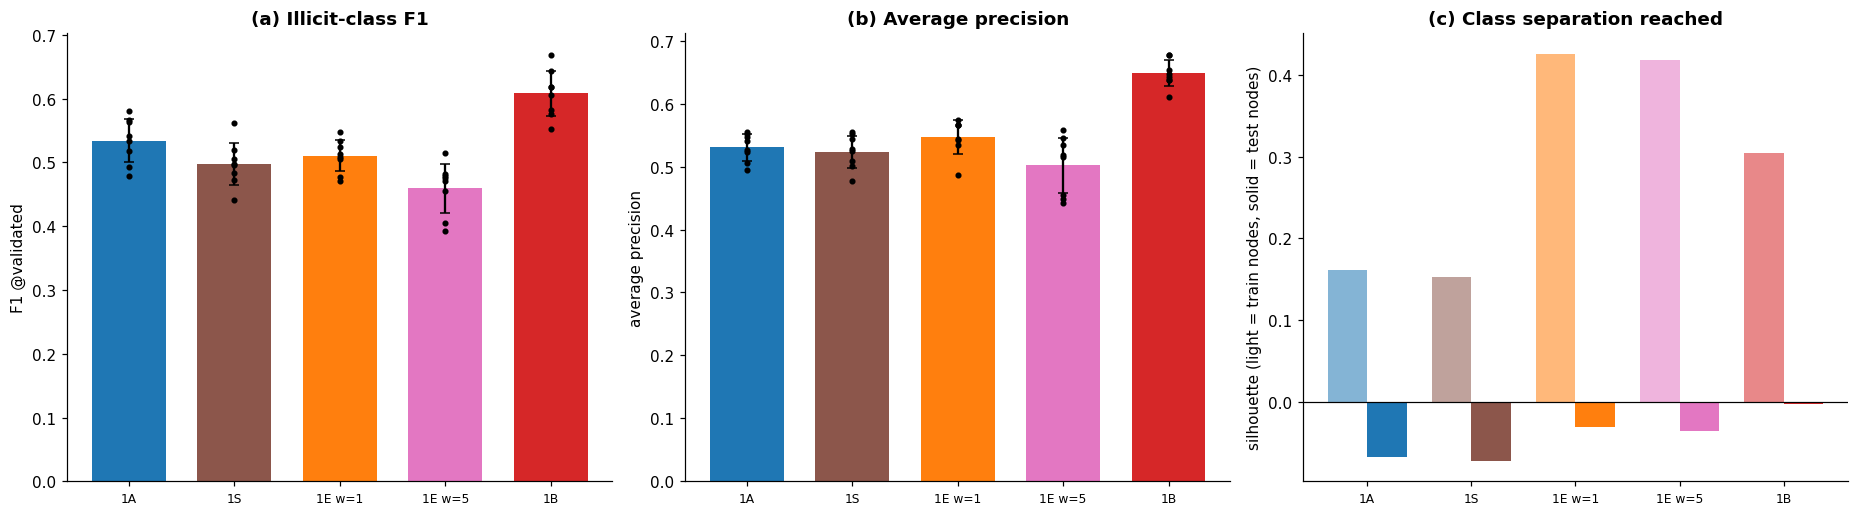

✓ saved fig_mechanism_control.png

WHAT THE CONTROL SHOWS (verdicts follow the numbers)
 - 1S is worse than 1A: a penalty on meaningless labels hurts, so the 1B gain is not a generic regularisation effect.
 - 1E w=1 (embedding, no link penalty): reaches the separation of 1B on training nodes (silhouette 0.43 against 0.30) and shows no gain, so separation alone is not sufficient to produce the 1B gain.
 - 1E w=5 (embedding, no link penalty): reaches the separation of 1B on training nodes (silhouette 0.42 against 0.30) and shows no gain, so separation alone is not sufficient to produce the 1B gain.
 - 1B against 1E w=5 in F1: +0.149 (CI +0.091 to +0.207), wins 8/8


/tmp/ipykernel_560/1434219325.py:12: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  blob = pickle.dumps(v)
/tmp/ipykernel_560/1434219325.py:18: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(keep, f)


checkpoint saved: 481 variables -> /content/drive/MyDrive/aml_results_checkpoint.pkl
✓ thesis_results_control.json written


In [60]:
# ═══════════════════════════════════════════════════════════════════════════
# MECHANISM CONTROL: does the gain of 1B need the LINK penalty, or the real LABELS, or neither?
# Every arm below is Option 1A (same encoder, node head, link task, optimiser, schedule, seeds, temporal
# split) with ONE extra term added to the link loss, exactly where 1B adds its penalty:
#   1S  shuffled-label constraint: 1B's penalty, but the training labels are randomly permuted among the
#       training nodes. Same penalty, same strength, no real label information.
#       If 1S gains over 1A, the gain is a regularisation effect and does not need the labels.
#   1E  embedding separation, no link penalty: a loss on sampled illicit-licit TRAINING node pairs that pushes
#       their embeddings apart (cosine similarity), with no use of the link score. Weight 1.0 (as 1B) and 5.0.
#       If 1E gains over 1A, separating the classes in the embedding is enough.
# Both are fixed in advance. Training labels only are used, as in 1B.
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 70)
print("MECHANISM CONTROL")
print("=" * 70)
CTRL_SEEDS    = SEEDS_LIST_H
N_CROSS_PAIRS = 4096
EMB_WEIGHTS   = (1.0, 5.0)

def make_train_1s(seed):
    """Option 1B with the training labels permuted among training nodes (fixed per seed)."""
    state = {}
    def fn(model, data, optimizer, alpha, lam, device):
        if 'y' not in state:
            g  = torch.Generator().manual_seed(10_000 + seed)
            tr = torch.where(data.train_mask)[0]
            y_perm = torch.full_like(data.y, -1)
            y_perm[tr] = data.y[tr][torch.randperm(len(tr), generator=g)]
            state['y'] = y_perm.to(device)
        model.train(); optimizer.zero_grad()
        node_pred, link_pred, cross_mask = model.forward_with_constraint(
            data.x.to(device), data.edge_index.to(device), data.train_edge_label_index.to(device), state['y'])
        n_loss = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
        total_link, bce, cp = constrained_link_loss(link_pred, data.train_edge_label.to(device), cross_mask, lam)
        loss = alpha * n_loss + (1 - alpha) * total_link
        loss.backward(); optimizer.step()
        return {'total': loss.item(), 'node': n_loss.item(), 'link': total_link.item(), 'bce': bce.item(),
                'constraint': float(cp.detach()) if isinstance(cp, torch.Tensor) else cp, 'n_cross': cross_mask.sum().item()}
    return fn

def make_train_1e(emb_weight):
    """Option 1A plus a label-based separation loss on node embeddings. No term touches the link score."""
    state = {}
    def fn(model, data, optimizer, alpha, device):
        if not state:
            state['ill'] = torch.where(data.train_mask & (data.y == 1))[0].to(device)
            state['lic'] = torch.where(data.train_mask & (data.y == 0))[0].to(device)
        model.train(); optimizer.zero_grad()
        z         = model.encode(data.x.to(device), data.edge_index.to(device))
        node_pred = model.decode_nodes(z)
        link_pred = model.decode_links(z, data.train_edge_label_index.to(device))
        n_loss = node_loss_fn(node_pred, data.y.to(device), data.train_mask.to(device), data.class_weights, device)
        l_loss = F.binary_cross_entropy_with_logits(link_pred, data.train_edge_label.float().to(device))
        i = state['ill'][torch.randint(len(state['ill']), (N_CROSS_PAIRS,), device=device)]
        j = state['lic'][torch.randint(len(state['lic']), (N_CROSS_PAIRS,), device=device)]
        pen = ((F.cosine_similarity(z[i], z[j], dim=-1) + 1) / 2).mean()
        loss = alpha * n_loss + (1 - alpha) * (l_loss + emb_weight * pen)
        loss.backward(); optimizer.step()
        return {'total': loss.item(), 'node': n_loss.item(), 'link': l_loss.item(), 'constraint': pen.item()}
    return fn

ctrl = {'1S': [], 'E1': [], 'E5': []}
for sd in CTRL_SEEDS:
    ctrl['1S'].append(run_dual(data_temporal, sd, True,  label=f"1S {sd}", fn_override=make_train_1s(sd)))
    ctrl['E1'].append(run_dual(data_temporal, sd, False, label=f"1E w=1 {sd}", fn_override=make_train_1e(EMB_WEIGHTS[0])))
    ctrl['E5'].append(run_dual(data_temporal, sd, False, label=f"1E w=5 {sd}", fn_override=make_train_1e(EMB_WEIGHTS[1])))
    print(f"seed {sd} done", flush=True)

arms = {'1A (no constraint)': mech['temporal']['1A'], '1S (shuffled labels)': ctrl['1S'],
        '1E w=1 (embedding, no link penalty)': ctrl['E1'], '1E w=5 (embedding, no link penalty)': ctrl['E5'],
        '1B (constraint)': mech['temporal']['1B']}
base = arms['1A (no constraint)']
rows, ctrl_stats = [], {}
for nm, R in arms.items():
    f1, ap = [r['tuned']['f1'] for r in R], [r['tuned']['ap'] for r in R]
    st_f1 = paired_stats(f1, [r['tuned']['f1'] for r in base]); st_ap = paired_stats(ap, [r['tuned']['ap'] for r in base])
    ctrl_stats[nm] = {'f1': st_f1, 'ap': st_ap,
                      'sil_train': float(np.mean([r['sep_train']['silhouette'] for r in R])),
                      'sil_test':  float(np.mean([r['sep_test']['silhouette'] for r in R])),
                      'link_auc':  float(np.mean([r['ev']['link_auc'] for r in R]))}
    rows.append({'Arm': nm, 'F1 @validated': ms(f1), 'Average precision': ms(ap),
                 'Gain over 1A (F1)': 'reference' if nm.startswith('1A') else f"{st_f1['mean_diff']:+.4f} (CI {st_f1['ci_lo']:+.4f} to {st_f1['ci_hi']:+.4f}), wins {st_f1['wins']}/{st_f1['n']}, p {st_f1['w_p']:.4f}",
                 'Gain over 1A (AP)': 'reference' if nm.startswith('1A') else f"{st_ap['mean_diff']:+.4f} (CI {st_ap['ci_lo']:+.4f} to {st_ap['ci_hi']:+.4f}), wins {st_ap['wins']}/{st_ap['n']}",
                 'Silhouette, train nodes': f"{ctrl_stats[nm]['sil_train']:.3f}", 'Silhouette, test nodes': f"{ctrl_stats[nm]['sil_test']:.3f}",
                 'Link AUC': f"{ctrl_stats[nm]['link_auc']:.3f}"})
ctrl_df = pd.DataFrame(rows)
save_table(ctrl_df, 'table_mechanism_control')

# ── Figure ──
names = list(arms); cols_ = ['#1f77b4', '#8c564b', '#ff7f0e', '#e377c2', '#d62728']
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for k, key in enumerate(('f1', 'ap')):
    for i, nm in enumerate(names):
        v = [r['tuned'][key] for r in arms[nm]]
        ax[k].bar(i, np.mean(v), 0.7, yerr=np.std(v), color=cols_[i], capsize=3)
        ax[k].scatter(np.full(len(v), i), v, color='black', s=9, zorder=3)
    ax[k].set_xticks(range(len(names))); ax[k].set_xticklabels([n.split(' (')[0] for n in names], fontsize=8)
    ax[k].set_ylabel({'f1': 'F1 @validated', 'ap': 'average precision'}[key])
    ax[k].set_title(['(a) Illicit-class F1', '(b) Average precision'][k])
w = 0.38
for i, nm in enumerate(names):
    ax[2].bar(i - w / 2, ctrl_stats[nm]['sil_train'], w, color=cols_[i], alpha=0.55)
    ax[2].bar(i + w / 2, ctrl_stats[nm]['sil_test'],  w, color=cols_[i])
ax[2].axhline(0, color='black', lw=0.8)
ax[2].set_xticks(range(len(names))); ax[2].set_xticklabels([n.split(' (')[0] for n in names], fontsize=8)
ax[2].set_ylabel('silhouette (light = train nodes, solid = test nodes)'); ax[2].set_title('(c) Class separation reached')
save_fig('fig_mechanism_control.png')

# ── Verdicts from the numbers ──
def sig_pos(st): return st['ci_lo'] > 0
def sig_neg(st): return st['ci_hi'] < 0
sb = ctrl_stats['1B (constraint)']
print("\nWHAT THE CONTROL SHOWS (verdicts follow the numbers)")
b_ok = sig_pos(sb['f1'])
if not b_ok:
    print(" ! 1B itself shows no significant F1 gain over 1A in this run, so the arms below cannot be interpreted against it.")
s1 = ctrl_stats['1S (shuffled labels)']['f1']
if sig_pos(s1):   v1 = "1S gains over 1A: the penalty helps even with meaningless labels, so part of the 1B gain is regularisation and does not need the labels."
elif sig_neg(s1): v1 = "1S is worse than 1A: a penalty on meaningless labels hurts, so the 1B gain is not a generic regularisation effect."
else:             v1 = "1S shows no detectable gain over 1A (interval includes zero): the 1B gain needs the real labels and is not a generic regularisation effect."
print(" -", v1)
ev_lines = {}
for key, nm in (('E1', '1E w=1 (embedding, no link penalty)'), ('E5', '1E w=5 (embedding, no link penalty)')):
    st, cs = ctrl_stats[nm]['f1'], ctrl_stats[nm]
    reached = cs['sil_train'] >= sb['sil_train'] - 0.05
    if sig_pos(st):   v = f"{nm}: gains over 1A ({st['mean_diff']:+.3f}), so separating the classes in the embedding without any link penalty can help."
    elif reached:     v = f"{nm}: reaches the separation of 1B on training nodes (silhouette {cs['sil_train']:.2f} against {sb['sil_train']:.2f}) and shows no gain, so separation alone is not sufficient to produce the 1B gain."
    else:             v = f"{nm}: no gain, but it did not reach the separation of 1B (silhouette {cs['sil_train']:.2f} against {sb['sil_train']:.2f}), so this arm is not conclusive."
    ev_lines[nm] = v; print(" -", v)
bb = paired_stats([r['tuned']['f1'] for r in mech['temporal']['1B']], [r['tuned']['f1'] for r in ctrl['E5']])
print(f" - 1B against 1E w=5 in F1: {bb['mean_diff']:+.3f} (CI {bb['ci_lo']:+.3f} to {bb['ci_hi']:+.3f}), wins {bb['wins']}/{bb['n']}")
def _jsonable(o):
    if isinstance(o, dict): return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return _jsonable(o.tolist())
    if isinstance(o, (np.floating, float)): return None if (np.isnan(o) or np.isinf(o)) else float(o)
    if isinstance(o, np.integer): return int(o)
    return o
control_summary = {'verdict_1S': v1, 'verdict_1E': ev_lines,
                   'arms': {nm: {'f1_gain_vs_1A': ctrl_stats[nm]['f1'], 'ap_gain_vs_1A': ctrl_stats[nm]['ap'],
                                 'sil_train': ctrl_stats[nm]['sil_train'], 'sil_test': ctrl_stats[nm]['sil_test'],
                                 'link_auc': ctrl_stats[nm]['link_auc']} for nm in arms},
                   '1B_vs_1E_w5_f1': bb}
with open('thesis_results_control.json', 'w') as f:
    json.dump(_jsonable(control_summary), f, indent=2, default=float)
save_checkpoint()
print("✓ thesis_results_control.json written")


## 35. Save Models and Export Results

In [61]:
SUFFIX = '_DRYRUN' if DRY_RUN else ''

torch.save({
    'model_state_dict': model_1a.state_dict(), 'history': history_1a,
    'test_metrics': test_1a,
    'config': {'hidden': HIDDEN_CHANNELS, 'dropout': DROPOUT, 'lr': LEARNING_RATE, 'alpha': ALPHA},
}, 'model_option1a.pt')

torch.save({
    'model_state_dict': model_1a_temporal.state_dict(), 'history': history_1a_temporal,
    'test_metrics': test_1a_temporal,
    'config': {'hidden': HIDDEN_CHANNELS, 'dropout': DROPOUT, 'lr': LEARNING_RATE, 'alpha': ALPHA, 'split': 'temporal'},
}, 'model_option1a_temporal.pt')

torch.save({
    'model_state_dict': model_1b_temporal.state_dict(), 'history': history_1b_temporal,
    'test_metrics': test_1b_temporal,
    'config': {'hidden': HIDDEN_CHANNELS, 'dropout': DROPOUT, 'lr': LEARNING_RATE, 'alpha': ALPHA, 'lambda': LAMBDA, 'split': 'temporal'},
}, 'model_option1b_temporal.pt')

torch.save({
    'model_state_dict': model_1b.state_dict(), 'history': history_1b,
    'test_metrics': test_1b,
    'constraint_stats': {k: float(v) for k, v in constraint_stats.items() if not isinstance(v, np.ndarray)},
    'config': {'hidden': HIDDEN_CHANNELS, 'dropout': DROPOUT, 'lr': LEARNING_RATE, 'alpha': ALPHA, 'lambda': LAMBDA},
}, 'model_option1b.pt')

# ── Reproducibility metadata ────────────────────────────────────────────────
# Captured at export time so a reviewer/examiner can see exactly what produced
# these numbers: library versions, hardware, and the seed — not just the results.
import sklearn, platform, subprocess

try:
    installed = subprocess.run(['pip', 'freeze'], capture_output=True, text=True, timeout=30).stdout
    pinned_versions = {
        line.split('==')[0]: line.split('==')[1]
        for line in installed.splitlines()
        if '==' in line and line.split('==')[0].lower() in
           {'torch', 'torch-geometric', 'scikit-learn', 'numpy', 'pandas', 'scipy'}
    }
except Exception as e:
    pinned_versions = {'error': str(e)}

reproducibility = {
    'seed': SEED,
    'device': str(device),
    'gpu_name': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'cuda_version': torch.version.cuda if torch.cuda.is_available() else None,
    'python_version': platform.python_version(),
    'library_versions': {
        'torch': torch.__version__,
        'torch_geometric': __import__('torch_geometric').__version__,
        'scikit_learn': sklearn.__version__,
        'numpy': np.__version__,
        'pandas': pd.__version__,
    },
    'pip_freeze_pinned': pinned_versions,
    'deterministic_algorithms': torch.are_deterministic_algorithms_enabled(),
    'export_timestamp_utc': datetime.utcnow().isoformat() + 'Z',
}

results_export = {
    'dataset': {
        **full_dataset_stats,
        'time_steps': 49, 'node_split': '70/15/15', 'edge_split': '60/20/20',
        'node_cap': MAX_NODES,
        'nodes_used': int(N),
        'class_weight_licit'  : round(float(class_weights[0]), 4),
        'class_weight_illicit': round(float(class_weights[1]), 4),
        'weight_ratio'        : round(float(class_weights[1]/class_weights[0]), 4),
    },
    'option_1a_test': {k: round(v, 4) for k, v in test_1a.items()},
    'option_1b_test': {k: round(v, 4) for k, v in test_1b.items()},
    'constraint_test': {
        'illicit_illicit': round(constraint_stats['illicit_illicit'], 4),
        'licit_licit'    : round(constraint_stats['licit_licit'], 4),
        'cross_class'    : round(constraint_stats['cross_class'], 4),
        'reduction'      : round(constraint_stats['reduction'], 4),
        'n_ii': constraint_stats['n_ii'],
        'n_ll': constraint_stats['n_ll'],
        'n_cc': constraint_stats['n_cc'],
    },
    'reproducibility': reproducibility,
    'multi_seed_robustness': robustness_summary,
    'temporal_split': temporal_split_results,
    'multiseed_leakage_ablation': multiseed_leakage_results,
    'multiseed_temporal_link_prediction': multiseed_temporal_link_results,
    'directional_diagnostic': directional_diagnostic_results,
    'directional_constraint_experiment_L': directional_constraint_results,
    'gat_generalisation_experiment_M': gat_generalisation_results,
    'multiseed_temporal_threshold': multiseed_temporal_threshold_results,
    'run_mode': 'dry_run' if DRY_RUN else 'full',
    'gat_training_setting_search': gat_trials,
    'seeds': {'random': SEEDS_LIST, 'temporal': SEEDS_LIST_H},
    'protocol': {
        'platform': 'Google Colab',
        'negative_sampling': 'same time step as the real edge, no existing edge',
        'constraint_labels': 'training nodes only',
        'link_evaluation_graph': 'validation: train edges; test: train + validation edges',
        'node_evaluation_graph': 'full graph (transductive)',
        'feature_scaling': 'mean/std from labelled training nodes only, fitted per split protocol',
        'sd_convention': 'population SD (ddof=0)',
        'average_precision': 'sklearn average_precision_score',
    },
    'node_only_baseline_multiseed': node_only_results,
    'directional_constraint_validated_threshold': [r['tuned'] for r in sweep_1c],
    'gat_validated_threshold': {'option_1a': [r['tuned'] for r in sweep_1a_gat],
                                'option_1b': [r['tuned'] for r in sweep_1b_gat]},
    'per_seed_validated_threshold': {'option_1a': k_sweep_1a, 'option_1b': k_sweep_1b},
    'feature_only_baselines': feature_baseline_results,
    'constraint_reduction_1a_vs_1b': {'reduction_1a': float(reduction_of(p_a, g_t)), 'reduction_1b': float(reduction_of(p_b, g_t)),
                                      'paired_bootstrap_ci95': [float(lo), float(hi)]},
    'dataset_structure_and_shift': shift_results,
    'mechanism': {'summary': mechanism_summary, 'table': mech_df.to_dict('records'),
                  'per_seed': {s_: {m_: [{k: v for k, v in r.items() if k not in ('val_y', 'val_p', 'test_y', 'test_p')} for r in runs] for m_, runs in d_.items()} for s_, d_ in mech.items()}},
    'paired_tests': paired_df.to_dict('records'),
    'time_windows': window_df.to_dict('records'),
    'lambda_temporal': lambda_summary,
    'rolling_folds': fold_pairs_df.to_dict('records'),
    'pipeline_audit': audit_summary,
    'dose_response': dose_summary,
    'window_means': win_means,
    'evidence_table': evidence_df.to_dict('records'),
    'mechanism_control': control_summary,
}

def _jsonable(o):
    if isinstance(o, dict): return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return _jsonable(o.tolist())
    if isinstance(o, (np.floating, float)): return None if (np.isnan(o) or np.isinf(o)) else float(o)
    if isinstance(o, np.integer): return int(o)
    return o

with open(f'thesis_results{SUFFIX}.json', 'w') as f:
    json.dump(_jsonable(results_export), f, indent=2, default=float)

# Pin exactly what was actually installed this run, so a future session (or a
# reviewer trying to reproduce results) installs the identical stack rather
# than whatever the unpinned '!pip install' line resolves to at that time.
with open('requirements.txt', 'w') as f:
    for pkg, ver in sorted(pinned_versions.items()):
        f.write(f"{pkg}=={ver}\n")

print("\u2713 model_option1a.pt")
print("\u2713 model_option1b.pt")
print("\u2713 model_option1a_temporal.pt")
print("\u2713 model_option1b_temporal.pt")
print(f"\u2713 thesis_results{SUFFIX}.json  (includes a 'reproducibility' section)")
print("\u2713 requirements.txt     (exact pinned versions from this run)")
import glob
for _f in sorted(glob.glob('*.png')):
    print('\u2713', _f)
import zipfile
with zipfile.ZipFile(f'thesis_figures_and_tables{SUFFIX}.zip', 'w') as _z:
    for _f in sorted(glob.glob('*.png')): _z.write(_f)
    for _f in sorted(glob.glob('tables/*.csv')): _z.write(_f)
print(f'\u2713 thesis_figures_and_tables{SUFFIX}.zip')
print(f"\nGPU used this run: {reproducibility['gpu_name']}  (CUDA {reproducibility['cuda_version']})")
print("Keep this notebook's requirements.txt and the GPU name alongside any numbers")
print("you report \u2014 both matter for exact reproducibility on CUDA.")

✓ model_option1a.pt
✓ model_option1b.pt
✓ model_option1a_temporal.pt
✓ model_option1b_temporal.pt
✓ thesis_results.json  (includes a 'reproducibility' section)
✓ requirements.txt     (exact pinned versions from this run)
✓ baseline_comparison.png
✓ constraint_analysis.png
✓ constraint_directional_diagnostic.png
✓ directional_constraint_comparison.png
✓ fig_architecture.png
✓ fig_dataset_structure.png
✓ fig_distribution_shift.png
✓ fig_dose_response.png
✓ fig_evaluation_protocols.png
✓ fig_lambda_temporal.png
✓ fig_mechanism.png
✓ fig_mechanism_control.png
✓ fig_model_comparison.png
✓ fig_paired_seeds.png
✓ fig_per_step_f1.png
✓ fig_pipeline_audit.png
✓ fig_rolling_folds.png
✓ gat_architecture_generalisation.png
✓ lambda_sweep.png
✓ multiseed_leakage_ablation.png
✓ multiseed_robustness.png
✓ multiseed_temporal_link_auc.png
✓ multiseed_temporal_threshold.png
✓ option1a_results.png
✓ option1b_results.png
✓ temporal_vs_random_comparison.png
✓ thesis_figures_and_tables.zip

GPU used this ru

/tmp/ipykernel_560/16406130.py:59: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  'export_timestamp_utc': datetime.utcnow().isoformat() + 'Z',


## Summary

| Component | Specification |
|---|---|
| Encoder | GraphSAGE · 2 layers · 64 dims · mean aggregation · ReLU · Dropout 0.5 |
| Node head | Linear(64→32) → ReLU → Dropout → Linear(32→2) |
| Link decoder | Dot product of endpoint embeddings |
| Class weighting | Inverse-frequency on training partition |
| Unknown masking | Nodes with label −1 excluded from classification loss |
| Negative sampling | Same time step as the real edge, source node kept, no existing edge |
| Node split | 70 / 15 / 15 — stratified by class |
| Edge split | 60 / 20 / 20 |
| Evaluation | Random split and temporal split (train steps 1-29, validation 30-34, test 35-49), 8 seeds, thresholds selected on validation data |
| Option 1B constraint | BCE + λ × mean σ(score) over cross-class training pairs, using labels of training nodes only |

### Results
Results are in thesis_results.json and thesis_results_patch.json. Claims and contributions are stated in the thesis chapters, not in this notebook.
